# 🔥 Multimodal Consistency Reasoning Framework — IMPROVED VERSION
## Key upgrades applied:
- ✅ **400 samples/class** (was 100) — bigger training data
- ✅ **RoBERTa-base** text encoder (was DistilBERT) — stronger language model
- ✅ **ResNet-50** image encoder (was ResNet-18) — deeper vision backbone
- ✅ **Cosine LR scheduler + early stopping** (was fixed LR, no stopping)
- ✅ **Stronger image augmentation** (random crop, color jitter, rotation)
- ✅ **XGBoost** metadata model (was RandomForest)
- ✅ **Learned MLP fusion** (was fixed alpha=0.7)
- ✅ **Gradient clipping** to stabilise training


# STEP 1 — Environment Setup

In [1]:
import os, sys, platform, torch

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("⚠️  Running on CPU — training will be slow. Enable GPU in Runtime > Change runtime type")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
CUDA version: 13.0


# STEP 2 — Install Libraries

In [2]:
!pip -q install transformers datasets timm pillow scikit-learn matplotlib pandas tqdm xgboost sentence-transformers easyocr kagglehub


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 28.8 MB/s eta 0:00:00


# STEP 3 — Seeds & Project Folders

In [3]:
import random, numpy as np, torch
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

BASE_DIR   = Path("/content/fake_news_project")
DATA_DIR   = BASE_DIR / "data"
CACHE_DIR  = BASE_DIR / "cache"
OUTPUT_DIR = BASE_DIR / "outputs"
CKPT_DIR   = BASE_DIR / "checkpoints"

for d in [BASE_DIR, DATA_DIR, CACHE_DIR, OUTPUT_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Seed set to:", SEED)


Device: cuda
Seed set to: 42


# STEP 4 — Download Fakeddit Dataset

In [4]:
import kagglehub
dataset_path = kagglehub.dataset_download("vanshikavmittal/fakeddit-dataset")
print("Dataset at:", dataset_path)


100%|██████████| 72.8M/72.8M [00:01<00:00, 64.9MB/s]

Extracting files...


Dataset at: /root/.cache/kagglehub/datasets/vanshikavmittal/fakeddit-dataset/versions/4


# STEP 5 — Load Train / Val / Test TSV Files

In [5]:
import pandas as pd
from pathlib import Path

FAKEDDIT_BASE = Path(dataset_path) / "multimodal_only_samples"

train_df = pd.read_csv(FAKEDDIT_BASE / "multimodal_train.tsv",        sep="\t")
valid_df = pd.read_csv(FAKEDDIT_BASE / "multimodal_validate.tsv",     sep="\t")
test_df  = pd.read_csv(FAKEDDIT_BASE / "multimodal_test_public.tsv",  sep="\t")

print("Train:", train_df.shape, "| Valid:", valid_df.shape, "| Test:", test_df.shape)
print("Columns:", train_df.columns.tolist())


Train: (564000, 16) | Valid: (59342, 16) | Test: (59319, 16)
Columns: ['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']


# STEP 6 — Create Balanced Dataset (400 per class)

In [6]:
# ✅ UPGRADE: 400 per class (was 100) — more data = better generalisation
SAMPLES_PER_CLASS = 500   # initial pool

debug_df = (
    train_df.groupby("6_way_label", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), SAMPLES_PER_CLASS), random_state=42))
    .reset_index(drop=True)
)

print("Debug pool shape:", debug_df.shape)
print(debug_df["6_way_label"].value_counts().sort_index())


Debug pool shape: (3000, 16)
6_way_label
0    500
1    500
2    500
3    500
4    500
5    500
Name: count, dtype: int64


/tmp/ipykernel_596/366028243.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), SAMPLES_PER_CLASS), random_state=42))


# STEP 7 — Download & Cache Images

In [7]:
import time, requests
from io import BytesIO
from PIL import Image, UnidentifiedImageError

IMAGE_CACHE_DIR = BASE_DIR / "data" / "image_cache"
IMAGE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def download_and_cache_image(row, cache_dir=IMAGE_CACHE_DIR, timeout=15):
    sample_id = str(row["id"])
    image_url = row["image_url"]

    if pd.isna(image_url) or not str(image_url).strip():
        return {"status": "missing_url", "local_path": None, "error": "missing url"}

    out_path = cache_dir / f"{sample_id}.jpg"
    if out_path.exists():
        return {"status": "ok", "local_path": str(out_path), "error": None}

    headers = {"User-Agent": "Mozilla/5.0"}
    try:
        resp = requests.get(image_url, headers=headers, timeout=timeout)
        resp.raise_for_status()
        img = Image.open(BytesIO(resp.content)).convert("RGB")
        img.save(out_path, format="JPEG", quality=95)
        return {"status": "ok", "local_path": str(out_path), "error": None}
    except requests.RequestException as e:
        return {"status": "request_error", "local_path": None, "error": str(e)}
    except (UnidentifiedImageError, OSError) as e:
        return {"status": "bad_image", "local_path": None, "error": str(e)}

print("Image download function ready.")


Image download function ready.


In [8]:
from tqdm.auto import tqdm

# ✅ UPGRADE: 400 per class (was 100)
CACHE_SAMPLES_PER_CLASS = 400

work_parts = []
for label, group in debug_df.groupby("6_way_label"):
    work_parts.append(group.sample(n=min(len(group), CACHE_SAMPLES_PER_CLASS), random_state=42))

work_df = pd.concat(work_parts).reset_index(drop=True)
print("Work subset:", work_df.shape)

cache_results = []
for _, row in tqdm(work_df.iterrows(), total=len(work_df)):
    result = download_and_cache_image(row)
    cache_results.append({"id": row["id"], "status": result["status"],
                           "local_image_path": result["local_path"]})

cache_results_df = pd.DataFrame(cache_results)
print(cache_results_df["status"].value_counts())

work_df = work_df.merge(cache_results_df[["id","status","local_image_path"]], on="id", how="left")
work_df_ok = work_df[work_df["status"] == "ok"].copy().reset_index(drop=True)

print("\nUsable rows:", len(work_df_ok))
print(work_df_ok["6_way_label"].value_counts().sort_index())


Work subset: (2400, 16)


  0%|          | 0/2400 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


status
ok               2285
request_error     108
missing_url         5
bad_image           2
Name: count, dtype: int64

Usable rows: 2285
6_way_label
0    364
1    374
2    375
3    383
4    395
5    394
Name: count, dtype: int64


# STEP 8 — Train / Validation Split

In [9]:
from sklearn.model_selection import train_test_split

train_df_main, val_df_main = train_test_split(
    work_df_ok, test_size=0.2, random_state=42,
    stratify=work_df_ok["6_way_label"]
)
train_df_main = train_df_main.reset_index(drop=True)
val_df_main   = val_df_main.reset_index(drop=True)

print("Train:", train_df_main.shape, "| Val:", val_df_main.shape)
print("\nTrain class counts:")
print(train_df_main["6_way_label"].value_counts().sort_index())


Train: (1828, 18) | Val: (457, 18)

Train class counts:
6_way_label
0    291
1    299
2    300
3    307
4    316
5    315
Name: count, dtype: int64


# STEP 9 — Tokenizer (RoBERTa) & Image Transforms

In [10]:
from transformers import AutoTokenizer
from torchvision import transforms

# ✅ UPGRADE: RoBERTa-base (was DistilBERT)
TEXT_MODEL_NAME = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)
print("Tokenizer:", TEXT_MODEL_NAME)

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

# ✅ UPGRADE: stronger augmentation (ColorJitter, RandomRotation, RandomResizedCrop)
train_image_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

val_image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

print("Image transforms ready.")


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer: roberta-base
Image transforms ready.


# STEP 10 — Multimodal Dataset Class

In [11]:
from torch.utils.data import Dataset
import torch

MAX_TEXT_LEN = 128

class FakedditMultimodalDataset(Dataset):
    def __init__(self, df, tokenizer, image_transform=None, max_text_len=128):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.image_transform = image_transform
        self.max_text_len = max_text_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text  = str(row["clean_title"])
        label = int(row["6_way_label"])
        image_path = row["local_image_path"]

        enc = self.tokenizer(text, truncation=True, padding="max_length",
                             max_length=self.max_text_len, return_tensors="pt")
        image = Image.open(image_path).convert("RGB")
        if self.image_transform:
            image = self.image_transform(image)

        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "image": image,
            "label": torch.tensor(label, dtype=torch.long),
            "text":  text,
            "id":    row["id"]
        }

train_dataset = FakedditMultimodalDataset(train_df_main, tokenizer, train_image_transform, MAX_TEXT_LEN)
val_dataset   = FakedditMultimodalDataset(val_df_main,   tokenizer, val_image_transform,   MAX_TEXT_LEN)
print("Train:", len(train_dataset), "| Val:", len(val_dataset))


Train: 1828 | Val: 457


# STEP 11 — DataLoaders

In [12]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Train batches:", len(train_loader), "| Val batches:", len(val_loader))


Train batches: 115 | Val batches: 29


# STEP 12 — Improved Multimodal Model (RoBERTa + ResNet-50)

In [13]:
import torch.nn as nn
from transformers import AutoModel
from torchvision import models

class ImprovedMultimodalModel(nn.Module):
    def __init__(self, text_model_name="roberta-base", num_classes=6, dropout=0.3):
        super().__init__()

        # ✅ UPGRADE: RoBERTa-base text encoder
        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        text_hidden_size  = self.text_encoder.config.hidden_size   # 768

        # ✅ UPGRADE: ResNet-50 image encoder (was ResNet-18)
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        image_hidden_size = resnet.fc.in_features   # 2048
        resnet.fc = nn.Identity()
        self.image_encoder = resnet

        fusion_dim = text_hidden_size + image_hidden_size  # 768 + 2048 = 2816

        # ✅ UPGRADE: deeper classifier head
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes)
        )

    def forward(self, input_ids, attention_mask, image):
        text_out  = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        text_feat = text_out.last_hidden_state[:, 0, :]   # CLS token
        img_feat  = self.image_encoder(image)
        fused     = torch.cat([text_feat, img_feat], dim=1)
        return self.classifier(fused)

model = ImprovedMultimodalModel(text_model_name=TEXT_MODEL_NAME, num_classes=6).to(device)
print("Model created: RoBERTa-base + ResNet-50 fusion")
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


Model created: RoBERTa-base + ResNet-50 fusion
Trainable parameters: 151,568,198


# STEP 13 — Loss, Optimizer & LR Scheduler

In [14]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from torch.optim import AdamW
from transformers import get_cosine_schedule_with_warmup

# Weighted cross-entropy for class imbalance
classes = np.array(sorted(train_df_main["6_way_label"].unique()))
weights = compute_class_weight("balanced", classes=classes, y=train_df_main["6_way_label"].values)
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# ✅ UPGRADE: separate LR for backbone vs head
optimizer = AdamW([
    {"params": model.text_encoder.parameters(),  "lr": 2e-5},
    {"params": model.image_encoder.parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(),    "lr": 1e-4},
], weight_decay=1e-2)

# ✅ UPGRADE: cosine decay scheduler with warmup
NUM_EPOCHS   = 20
NUM_WARMUP   = len(train_loader)            # 1 epoch warmup
NUM_TRAINING = NUM_EPOCHS * len(train_loader)

scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=NUM_WARMUP, num_training_steps=NUM_TRAINING
)

print(f"Optimizer ready | Epochs: {NUM_EPOCHS} | Warmup steps: {NUM_WARMUP}")


Optimizer ready | Epochs: 20 | Warmup steps: 115


# STEP 14 — Training & Evaluation Functions

In [15]:
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report

MAX_GRAD_NORM = 1.0   # gradient clipping

def train_one_epoch(model, loader, criterion, optimizer, scheduler, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc="Training", leave=False)

    for batch in pbar:
        ids   = batch["input_ids"].to(device)
        mask  = batch["attention_mask"].to(device)
        imgs  = batch["image"].to(device)
        labels= batch["label"].to(device)

        optimizer.zero_grad()
        logits = model(ids, mask, imgs)
        loss   = criterion(logits, labels)
        loss.backward()

        # ✅ UPGRADE: gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)

        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{correct/total:.4f}")

    return running_loss / total, correct / total


def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation", leave=False):
            ids   = batch["input_ids"].to(device)
            mask  = batch["attention_mask"].to(device)
            imgs  = batch["image"].to(device)
            labels= batch["label"].to(device)

            logits = model(ids, mask, imgs)
            loss   = criterion(logits, labels)
            running_loss += loss.item() * labels.size(0)

            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    n = len(all_labels)
    return (running_loss / n,
            accuracy_score(all_labels, all_preds),
            f1_score(all_labels, all_preds, average="macro"),
            all_labels, all_preds)

print("Train/eval functions ready.")


Train/eval functions ready.


# STEP 15 — Training Loop with Early Stopping

In [16]:
label_names = {0:"TRUE", 1:"SATIRE", 2:"FALSE_CONNECTION",
               3:"IMPOSTER", 4:"MANIPULATED", 5:"MISLEADING"}
target_names = [label_names[i] for i in range(6)]

history = {"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[], "val_f1":[]}

best_val_f1  = -1.0
best_model_path = CKPT_DIR / "best_improved_model.pt"

# ✅ UPGRADE: early stopping
PATIENCE    = 5
no_improve  = 0

for epoch in range(NUM_EPOCHS):
    print(f"\n{'='*55}")
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")
    print('='*55)

    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, device)
    vl_loss, vl_acc, vl_f1, y_true, y_pred = evaluate_model(model, val_loader, criterion, device)

    history["train_loss"].append(tr_loss);  history["train_acc"].append(tr_acc)
    history["val_loss"].append(vl_loss);    history["val_acc"].append(vl_acc)
    history["val_f1"].append(vl_f1)

    print(f"Train → Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f}")
    print(f"Val   → Loss: {vl_loss:.4f}  Acc: {vl_acc:.4f}  F1: {vl_f1:.4f}")

    if vl_f1 > best_val_f1:
        best_val_f1 = vl_f1
        torch.save(model.state_dict(), best_model_path)
        print(f"  ✅ New best saved (F1={best_val_f1:.4f})")
        no_improve = 0
    else:
        no_improve += 1
        print(f"  ⏳ No improvement ({no_improve}/{PATIENCE})")
        if no_improve >= PATIENCE:
            print("  ⛔ Early stopping triggered.")
            break

print("\n🏁 Training finished. Best Val F1:", round(best_val_f1, 4))



Epoch 1/20


Training:   0%|          | 0/115 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train → Loss: 1.7121  Acc: 0.2850
Val   → Loss: 1.3527  Acc: 0.4902  F1: 0.4220
  ✅ New best saved (F1=0.4220)

Epoch 2/20


Training:   0%|          | 0/115 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

... (51 outputs left out)

Train → Loss: 0.0048  Acc: 0.9989
Val   → Loss: 1.7909  Acc: 0.7133  F1: 0.7062
  ⏳ No improvement (3/5)

Epoch 20/20


Training:   0%|          | 0/115 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train → Loss: 0.0092  Acc: 0.9978
Val   → Loss: 1.8456  Acc: 0.7133  F1: 0.7045
  ⏳ No improvement (4/5)

🏁 Training finished. Best Val F1: 0.7198


# STEP 16 — Load Best Model & Classification Report

In [17]:
best_model = ImprovedMultimodalModel(text_model_name=TEXT_MODEL_NAME, num_classes=6).to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))
print("Best model loaded.")

_, vl_acc, vl_f1, y_true, y_pred = evaluate_model(best_model, val_loader, criterion, device)
print(f"\nVal Accuracy: {vl_acc:.4f}  |  Macro F1: {vl_f1:.4f}")
print("\n", classification_report(y_true, y_pred, target_names=target_names, digits=4))


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Best model loaded.


Validation:   0%|          | 0/29 [00:00<?, ?it/s]


Val Accuracy: 0.7243  |  Macro F1: 0.7198

                   precision    recall  f1-score   support

            TRUE     0.5946    0.6027    0.5986        73
          SATIRE     0.6125    0.6533    0.6323        75
FALSE_CONNECTION     0.6593    0.8000    0.7229        75
        IMPOSTER     0.8113    0.5658    0.6667        76
     MANIPULATED     0.8721    0.9494    0.9091        79
      MISLEADING     0.8219    0.7595    0.7895        79

        accuracy                         0.7243       457
       macro avg     0.7286    0.7218    0.7198       457
    weighted avg     0.7315    0.7243    0.7225       457



# STEP 17 — Training Curves

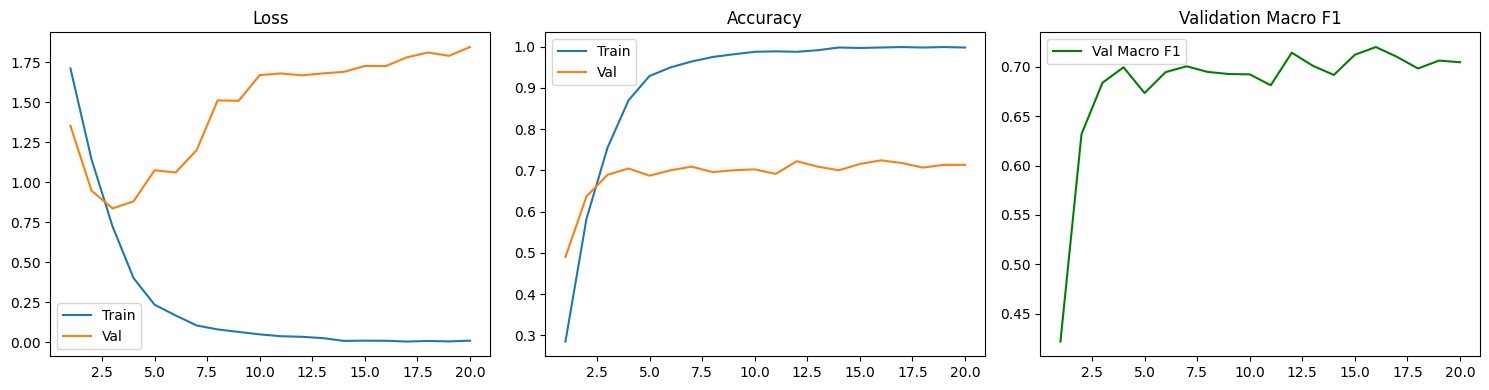

In [18]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(epochs, history["train_loss"], label="Train"); axes[0].plot(epochs, history["val_loss"], label="Val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(epochs, history["train_acc"], label="Train"); axes[1].plot(epochs, history["val_acc"], label="Val")
axes[1].set_title("Accuracy"); axes[1].legend()

axes[2].plot(epochs, history["val_f1"], label="Val Macro F1", color="green")
axes[2].set_title("Validation Macro F1"); axes[2].legend()

plt.tight_layout(); plt.show()


# STEP 18 — CLIP-Based Text-Image Alignment Model

In [19]:
from transformers import CLIPProcessor, CLIPModel

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)

class CLIPFakeNewsClassifier(nn.Module):
    def __init__(self, clip_model_name=CLIP_MODEL_NAME, num_classes=6, dropout=0.3):
        super().__init__()
        self.clip = CLIPModel.from_pretrained(clip_model_name)
        clip_dim = self.clip.config.projection_dim
        self.classifier = nn.Sequential(
            nn.Linear(clip_dim * 2, 512), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(512, num_classes)
        )

    def forward(self, input_ids, attention_mask, pixel_values):
        out = self.clip(input_ids=input_ids, attention_mask=attention_mask, pixel_values=pixel_values)
        fused = torch.cat([out.text_embeds, out.image_embeds], dim=1)
        return self.classifier(fused)

clip_model = CLIPFakeNewsClassifier().to(device)
print("CLIP model ready.")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model ready.


# STEP 19 — CLIP Dataset & DataLoaders

In [20]:
class FakedditCLIPDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        return {"text": str(row["clean_title"]),
                "image": Image.open(row["local_image_path"]).convert("RGB"),
                "label": int(row["6_way_label"]), "id": row["id"]}

def clip_collate_fn(batch):
    enc = clip_processor(text=[b["text"] for b in batch],
                         images=[b["image"] for b in batch],
                         return_tensors="pt", padding=True, truncation=True)
    enc["labels"] = torch.tensor([b["label"] for b in batch], dtype=torch.long)
    enc["ids"] = [b["id"] for b in batch]
    return enc

CLIP_BATCH = 8
train_clip_loader = DataLoader(FakedditCLIPDataset(train_df_main), batch_size=CLIP_BATCH, shuffle=True,  num_workers=0, collate_fn=clip_collate_fn)
val_clip_loader   = DataLoader(FakedditCLIPDataset(val_df_main),   batch_size=CLIP_BATCH, shuffle=False, num_workers=0, collate_fn=clip_collate_fn)
print("CLIP loaders:", len(train_clip_loader), "train |", len(val_clip_loader), "val")


CLIP loaders: 229 train | 58 val


# STEP 20 — Train CLIP Model

In [21]:
clip_criterion  = nn.CrossEntropyLoss(weight=class_weights_tensor)
clip_optimizer  = AdamW(clip_model.parameters(), lr=1e-5)
NUM_CLIP_EPOCHS = 10
best_clip_f1    = -1.0
best_clip_path  = CKPT_DIR / "best_clip_model.pt"
no_improve_clip = 0

def train_eval_clip(model, tr_loader, vl_loader, criterion, optimizer, n_epochs, patience=5):
    global best_clip_f1, no_improve_clip
    for ep in range(n_epochs):
        model.train()
        for batch in tqdm(tr_loader, desc=f"CLIP Epoch {ep+1}", leave=False):
            ids = batch["input_ids"].to(device); mask = batch["attention_mask"].to(device)
            pv  = batch["pixel_values"].to(device); lbl = batch["labels"].to(device)
            optimizer.zero_grad()
            loss = criterion(model(ids, mask, pv), lbl)
            loss.backward(); optimizer.step()

        model.eval(); preds_all, labels_all = [], []
        with torch.no_grad():
            for batch in vl_loader:
                ids = batch["input_ids"].to(device); mask = batch["attention_mask"].to(device)
                pv  = batch["pixel_values"].to(device); lbl = batch["labels"]
                out = model(ids, mask, pv).argmax(1).cpu().numpy()
                preds_all.extend(out); labels_all.extend(lbl.numpy())

        vf1 = f1_score(labels_all, preds_all, average="macro")
        vacc= accuracy_score(labels_all, preds_all)
        print(f"  CLIP Ep {ep+1} → Acc: {vacc:.4f}  F1: {vf1:.4f}")

        if vf1 > best_clip_f1:
            best_clip_f1 = vf1
            torch.save(model.state_dict(), best_clip_path)
            no_improve_clip = 0; print("    ✅ Saved")
        else:
            no_improve_clip += 1
            if no_improve_clip >= patience:
                print("    ⛔ Early stop"); break

    return labels_all, preds_all

y_true_clip, y_pred_clip = train_eval_clip(
    clip_model, train_clip_loader, val_clip_loader,
    clip_criterion, clip_optimizer, NUM_CLIP_EPOCHS
)
print("\nCLIP Best Val F1:", round(best_clip_f1, 4))
print(classification_report(y_true_clip, y_pred_clip, target_names=target_names, digits=4))


CLIP Epoch 1:   0%|          | 0/229 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

  CLIP Ep 1 → Acc: 0.5799  F1: 0.5647
    ✅ Saved


CLIP Epoch 2:   0%|          | 0/229 [00:00<?, ?it/s]

  CLIP Ep 2 → Acc: 0.5930  F1: 0.5724
    ✅ Saved


... (12 outputs left out)

CLIP Epoch 9:   0%|          | 0/229 [00:00<?, ?it/s]

  CLIP Ep 9 → Acc: 0.6018  F1: 0.6070


CLIP Epoch 10:   0%|          | 0/229 [00:00<?, ?it/s]

  CLIP Ep 10 → Acc: 0.6018  F1: 0.6035
    ⛔ Early stop

CLIP Best Val F1: 0.6617
                  precision    recall  f1-score   support

            TRUE     0.4928    0.4658    0.4789        73
          SATIRE     0.5455    0.5600    0.5526        75
FALSE_CONNECTION     0.5952    0.6667    0.6289        75
        IMPOSTER     0.4286    0.5132    0.4671        76
     MANIPULATED     0.8108    0.7595    0.7843        79
      MISLEADING     0.8065    0.6329    0.7092        79

        accuracy                         0.6018       457
       macro avg     0.6132    0.5997    0.6035       457
    weighted avg     0.6168    0.6018    0.6063       457



# STEP 21 — OCR Text Extraction & Similarity

In [22]:
import easyocr, re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

ocr_reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())
sim_model  = SentenceTransformer("all-MiniLM-L6-v2")
print("OCR reader and similarity model ready.")

def extract_ocr_text(image_path, reader):
    try:
        results = reader.readtext(str(image_path), detail=0, paragraph=True)
        return " ".join([str(x) for x in results]).strip() if isinstance(results, list) else str(results)
    except Exception as e:
        return ""

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def compute_ocr_similarity(title, ocr_text):
    t, o = clean_text(title), clean_text(ocr_text)
    if len(o) < 3: return 0.0
    emb = sim_model.encode([t, o])
    return float(cosine_similarity([emb[0]], [emb[1]])[0][0])

def add_ocr_features(df):
    df = df.copy().reset_index(drop=True)
    ocr_texts, ocr_sims = [], []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="OCR"):
        ocr = extract_ocr_text(row["local_image_path"], ocr_reader)
        sim = compute_ocr_similarity(row["clean_title"], ocr)
        ocr_texts.append(ocr); ocr_sims.append(sim)
    df["ocr_text"] = ocr_texts; df["ocr_similarity"] = ocr_sims
    return df

train_df_main = add_ocr_features(train_df_main)
val_df_main   = add_ocr_features(val_df_main)
print("OCR done. Sample:")
print(train_df_main[["clean_title","ocr_text","ocr_similarity"]].head(3).to_string())


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

OCR reader and similarity model ready.


OCR:   0%|          | 0/1828 [00:00<?, ?it/s]

OCR:   0%|          | 0/457 [00:00<?, ?it/s]

OCR done. Sample:
                                                        clean_title                                                 ocr_text  ocr_similarity
0                      to arms turkish mobilization posterworld war                                             SiLAH BASINA        0.153587
1  i spilt my drink and the splash looks like a bottle of champagne                                                                 0.000000
2                                                       lucha libre  Ski 25a1 FEFRFFO CUeTov FERRERO TEACHER"? 99 Tanbu 9.99        0.215061


# STEP 22 — Image Metadata Feature Extraction

In [23]:
import os
from PIL import ImageStat, ImageFilter

FEATURE_COLS = ["img_width","img_height","aspect_ratio","file_size",
                "mean_r","mean_g","mean_b","std_r","std_g","std_b",
                "gray_mean","gray_std","edge_mean","edge_std",
                "ocr_text_len","ocr_similarity"]

def extract_image_features(image_path):
    try:
        img  = Image.open(image_path).convert("RGB")
        gray = img.convert("L")
        w, h = img.size
        fs   = os.path.getsize(image_path)
        sr   = ImageStat.Stat(img); sg = ImageStat.Stat(gray)
        ed   = ImageStat.Stat(gray.filter(ImageFilter.FIND_EDGES))
        return {"img_width":float(w),"img_height":float(h),"aspect_ratio":w/h if h else 0.0,
                "file_size":float(fs),"mean_r":sr.mean[0],"mean_g":sr.mean[1],"mean_b":sr.mean[2],
                "std_r":sr.stddev[0],"std_g":sr.stddev[1],"std_b":sr.stddev[2],
                "gray_mean":sg.mean[0],"gray_std":sg.stddev[0],
                "edge_mean":ed.mean[0],"edge_std":ed.stddev[0]}
    except:
        return {k:0.0 for k in FEATURE_COLS[:14]}

def add_metadata_features(df):
    df = df.copy().reset_index(drop=True)
    feats = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Metadata"):
        f = extract_image_features(row["local_image_path"])
        f["ocr_text_len"]  = float(len(str(row.get("ocr_text","")).strip()))
        f["ocr_similarity"] = float(row.get("ocr_similarity", 0.0))
        feats.append(f)
    feat_df = pd.DataFrame(feats)
    return pd.concat([df, feat_df], axis=1).loc[:,~pd.concat([df,feat_df],axis=1).columns.duplicated()]

train_feat_df = add_metadata_features(train_df_main)
val_feat_df   = add_metadata_features(val_df_main)

X_train = train_feat_df[FEATURE_COLS].values; y_train = train_feat_df["6_way_label"].values
X_val   = val_feat_df[FEATURE_COLS].values;   y_val   = val_feat_df["6_way_label"].values
print("X_train:", X_train.shape, "| X_val:", X_val.shape)


Metadata:   0%|          | 0/1828 [00:00<?, ?it/s]

Metadata:   0%|          | 0/457 [00:00<?, ?it/s]

X_train: (1828, 16) | X_val: (457, 16)


# STEP 23 — XGBoost Metadata Model (Upgrade from RandomForest)

In [24]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# ✅ UPGRADE: XGBoost (was RandomForest)
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_val)

xgb_acc = accuracy_score(y_val, xgb_preds)
xgb_f1  = f1_score(y_val, xgb_preds, average="macro")
print(f"XGBoost  Accuracy: {xgb_acc:.4f}  |  Macro F1: {xgb_f1:.4f}")
print(classification_report(y_val, xgb_preds, target_names=target_names, digits=4))


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:38:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost  Accuracy: 0.5624  |  Macro F1: 0.5589
                  precision    recall  f1-score   support

            TRUE     0.3038    0.3288    0.3158        73
          SATIRE     0.6709    0.7067    0.6883        75
FALSE_CONNECTION     0.3611    0.3467    0.3537        75
        IMPOSTER     0.3026    0.3026    0.3026        76
     MANIPULATED     1.0000    0.9747    0.9872        79
      MISLEADING     0.7297    0.6835    0.7059        79

        accuracy                         0.5624       457
       macro avg     0.5614    0.5572    0.5589       457
    weighted avg     0.5672    0.5624    0.5645       457



# STEP 24 — Learned MLP Fusion (UPDATED: now includes RoBERTa+ResNet50 baseline)

**Fix applied:** the fusion classifier previously only saw `[CLIP_probs ; XGBoost_probs]`,
so it never had access to the strongest branch (the supervised RoBERTa+ResNet50 baseline)
and its accuracy collapsed toward the weakest branch (XGBoost). It now also includes the
baseline's probability vector: `[Baseline_probs ; CLIP_probs ; XGBoost_probs]`.

**Bug fix applied:** probability extraction for the *training* set was previously done using
`train_loader` / `train_clip_loader`, both of which have `shuffle=True`. That silently
misaligns each row's features with `y_train`'s label order during fusion training. New
unshuffled loaders (`eval_train_loader`, `eval_train_clip_loader`) are used instead, purely
for probability extraction — the original shuffled loaders are untouched and still used for
actual model training elsewhere in the notebook.


In [25]:
import torch.nn.functional as F
from torch.utils.data import DataLoader

# ---- FIX: unshuffled loaders for probability extraction only ----
# train_loader / train_clip_loader use shuffle=True (correct for training the
# underlying models), but reusing them here to extract per-sample probabilities
# would misalign each row with y_train / X_train, which are in train_df_main's
# original (unshuffled) order. These new loaders fix that.
eval_train_loader      = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
eval_train_clip_loader = DataLoader(FakedditCLIPDataset(train_df_main), batch_size=CLIP_BATCH,
                                     shuffle=False, num_workers=0, collate_fn=clip_collate_fn)

# ---- NEW: RoBERTa + ResNet50 baseline probabilities ----
# This is the key addition: the fusion classifier previously never saw the
# baseline's predictions at all, so it could not retain the baseline's stronger
# discriminative signal.
def get_baseline_probs(model, loader, device):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for batch in loader:
            ids   = batch["input_ids"].to(device)
            mask  = batch["attention_mask"].to(device)
            imgs  = batch["image"].to(device)
            logits = model(ids, mask, imgs)
            all_probs.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(all_probs)

baseline_train_probs = get_baseline_probs(best_model, eval_train_loader, device)
baseline_val_probs   = get_baseline_probs(best_model, val_loader,        device)

# ---- CLIP probability matrices ----
def get_clip_probs(model, loader, device):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for batch in loader:
            ids = batch["input_ids"].to(device); mask = batch["attention_mask"].to(device)
            pv  = batch["pixel_values"].to(device)
            logits = model(ids, mask, pv)
            all_probs.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(all_probs)

# Reload best CLIP model for probability extraction
best_clip_model = CLIPFakeNewsClassifier().to(device)
best_clip_model.load_state_dict(torch.load(best_clip_path, map_location=device))

clip_train_probs = get_clip_probs(best_clip_model, eval_train_clip_loader, device)
clip_val_probs   = get_clip_probs(best_clip_model, val_clip_loader,        device)

xgb_train_probs  = xgb_model.predict_proba(X_train)
xgb_val_probs    = xgb_model.predict_proba(X_val)

print("Baseline train probs:", baseline_train_probs.shape)
print("CLIP     train probs:", clip_train_probs.shape)
print("XGB      train probs:", xgb_train_probs.shape)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Baseline train probs: (1828, 6)
CLIP     train probs: (1828, 6)
XGB      train probs: (1828, 6)


In [26]:
# UPDATED: Learned MLP fusion layer now takes 3 branches (was 2)
# Input order: [Baseline_probs ; CLIP_probs ; XGBoost_probs]
class LearnedFusion(nn.Module):
    def __init__(self, n_classes=6, n_branches=3):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(n_classes * n_branches, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, n_classes)
        )
    def forward(self, x): return self.fc(x)

fusion_model = LearnedFusion(n_classes=6, n_branches=3).to(device)
fusion_optimizer = torch.optim.Adam(fusion_model.parameters(), lr=1e-3)
fusion_criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Build fusion train tensors -- baseline + CLIP + XGBoost, in that fixed order
Xf_train = torch.tensor(np.hstack([baseline_train_probs, clip_train_probs, xgb_train_probs]), dtype=torch.float32)
yf_train = torch.tensor(y_train, dtype=torch.long)
Xf_val   = torch.tensor(np.hstack([baseline_val_probs,   clip_val_probs,   xgb_val_probs]),   dtype=torch.float32)
yf_val   = torch.tensor(y_val, dtype=torch.long)

fusion_ds_train = torch.utils.data.TensorDataset(Xf_train, yf_train)
fusion_loader   = torch.utils.data.DataLoader(fusion_ds_train, batch_size=32, shuffle=True)

best_fusion_f1  = -1.0
best_fusion_path= CKPT_DIR / "best_fusion_mlp.pt"

for ep in range(50):
    fusion_model.train()
    for xb, yb in fusion_loader:
        xb = xb.to(device); yb = yb.to(device)
        fusion_optimizer.zero_grad()
        loss = fusion_criterion(fusion_model(xb), yb)
        loss.backward(); fusion_optimizer.step()

    fusion_model.eval()
    with torch.no_grad():
        preds = fusion_model(Xf_val.to(device)).argmax(1).cpu().numpy()
    fv = f1_score(y_val, preds, average="macro")
    if fv > best_fusion_f1:
        best_fusion_f1 = fv
        torch.save(fusion_model.state_dict(), best_fusion_path)

print(f"\nBest Learned Fusion F1: {best_fusion_f1:.4f}")
fusion_model.load_state_dict(torch.load(best_fusion_path, map_location=device))
with torch.no_grad():
    fusion_preds = fusion_model(Xf_val.to(device)).argmax(1).cpu().numpy()

print(f"Learned Fusion Accuracy: {accuracy_score(y_val, fusion_preds):.4f}")
print(classification_report(y_val, fusion_preds, target_names=target_names, digits=4))



Best Learned Fusion F1: 0.7527
Learned Fusion Accuracy: 0.7571
                  precision    recall  f1-score   support

            TRUE     0.5811    0.5890    0.5850        73
          SATIRE     0.6914    0.7467    0.7179        75
FALSE_CONNECTION     0.6742    0.8000    0.7317        75
        IMPOSTER     0.8302    0.5789    0.6822        76
     MANIPULATED     0.9620    0.9620    0.9620        79
      MISLEADING     0.8272    0.8481    0.8375        79

        accuracy                         0.7571       457
       macro avg     0.7610    0.7541    0.7527       457
    weighted avg     0.7643    0.7571    0.7559       457



# STEP 25 — Full Model Comparison

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

                                 Model  Accuracy  Macro F1
RoBERTa + ResNet50 (baseline-improved)    0.7243    0.7198
                         CLIP ViT-B/32    0.6018    0.6617
                      XGBoost Metadata    0.5624    0.5589
Learned MLP Fusion (Baseline+CLIP+XGB)    0.7571    0.7527


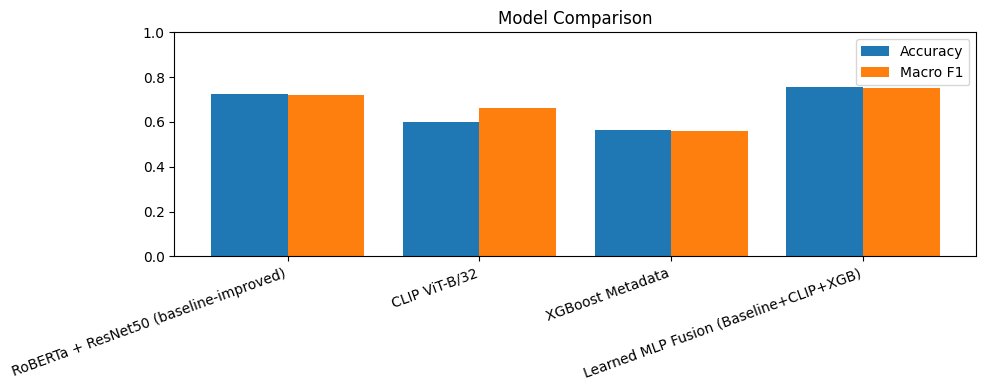

In [27]:
_, baseline_acc, baseline_f1, _, _ = evaluate_model(best_model, val_loader, criterion, device)

results_table = pd.DataFrame([
    ["RoBERTa + ResNet50 (baseline-improved)", round(baseline_acc,4), round(baseline_f1,4)],
    ["CLIP ViT-B/32",                          round(accuracy_score(y_true_clip, y_pred_clip),4), round(best_clip_f1,4)],
    ["XGBoost Metadata",                       round(xgb_acc,4), round(xgb_f1,4)],
    ["Learned MLP Fusion (Baseline+CLIP+XGB)", round(accuracy_score(y_val, fusion_preds),4), round(best_fusion_f1,4)],
], columns=["Model", "Accuracy", "Macro F1"])

print(results_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10,4))
x = range(len(results_table))
ax.bar([i-0.2 for i in x], results_table["Accuracy"], 0.4, label="Accuracy")
ax.bar([i+0.2 for i in x], results_table["Macro F1"], 0.4, label="Macro F1")
ax.set_xticks(list(x)); ax.set_xticklabels(results_table["Model"], rotation=20, ha="right")
ax.set_ylim(0, 1); ax.legend(); ax.set_title("Model Comparison")
plt.tight_layout(); plt.show()


# STEP 26 — Consistency Score Computation (Core Novelty 🔥)

In [28]:
def compute_consistency_score(clip_probs, ocr_similarity, metadata_probs):
    text_image_alignment = float(np.max(clip_probs))
    metadata_score       = float(np.max(metadata_probs))
    consistency_score    = (0.5 * text_image_alignment +
                            0.3 * float(ocr_similarity) +
                            0.2 * metadata_score)
    return {"consistency_score": consistency_score,
            "text_image_alignment": text_image_alignment,
            "metadata_score": metadata_score}

print("Consistency score function ready.")


Consistency score function ready.


# STEP 27 — Full Prediction + Explanation + Verification Pipeline

In [29]:
label_map = {0:"TRUE",1:"SATIRE",2:"FALSE_CONNECTION",
             3:"IMPOSTER",4:"MANIPULATED",5:"MISLEADING"}

# UPDATED: now also takes the baseline model + its tokenizer/image_transform,
# since the fusion classifier's input is [baseline_p ; clip_p ; xgb_p].
def predict_with_consistency_reasoning(
    title, image_path, clip_model, clip_processor, xgb_model,
    fusion_model, ocr_reader, baseline_model, tokenizer, image_transform,
    consistency_threshold=0.2
):
    # OCR
    ocr_text = extract_ocr_text(image_path, ocr_reader)
    ocr_sim  = compute_ocr_similarity(title, ocr_text)

    image = Image.open(image_path).convert("RGB")

    # Baseline (RoBERTa + ResNet50) probs
    enc_txt = tokenizer(title, truncation=True, padding="max_length",
                         max_length=MAX_TEXT_LEN, return_tensors="pt")
    img_tensor = image_transform(image).unsqueeze(0)
    baseline_model.eval()
    with torch.no_grad():
        base_logits = baseline_model(enc_txt["input_ids"].to(device),
                                      enc_txt["attention_mask"].to(device),
                                      img_tensor.to(device))
        baseline_p = F.softmax(base_logits, dim=1).cpu().numpy()[0]

    # CLIP probs
    enc = clip_processor(text=[title], images=[image],
                         return_tensors="pt", padding=True, truncation=True)
    clip_model.eval()
    with torch.no_grad():
        logits = clip_model(enc["input_ids"].to(device),
                            enc["attention_mask"].to(device),
                            enc["pixel_values"].to(device))
        clip_p = F.softmax(logits, dim=1).cpu().numpy()[0]

    # XGBoost probs
    img_feat = extract_image_features(image_path)
    img_feat["ocr_text_len"]   = float(len(clean_text(ocr_text)))
    img_feat["ocr_similarity"] = float(ocr_sim)
    feat_vec = np.array([img_feat[c] for c in FEATURE_COLS], dtype=np.float32).reshape(1,-1)
    xgb_p = xgb_model.predict_proba(feat_vec)[0]

    # Learned fusion -- now [baseline_p ; clip_p ; xgb_p]
    fusion_input = torch.tensor(np.hstack([baseline_p, clip_p, xgb_p]), dtype=torch.float32).unsqueeze(0).to(device)
    fusion_model.eval()
    with torch.no_grad():
        final_p = F.softmax(fusion_model(fusion_input), dim=1).cpu().numpy()[0]

    pred_idx   = int(np.argmax(final_p))
    cons_info  = compute_consistency_score(clip_p, ocr_sim, xgb_p)
    status     = "CONSISTENT" if cons_info["consistency_score"] >= consistency_threshold else "INCONSISTENT"

    return {
        "predicted_label": label_map[pred_idx],
        "confidence":       float(final_p[pred_idx]),
        "ocr_text":         ocr_text,
        "ocr_similarity":   float(ocr_sim),
        "consistency_score":float(cons_info["consistency_score"]),
        "status":           status,
        "explanation": {
            "text_image_alignment": float(cons_info["text_image_alignment"]),
            "ocr_text_alignment":   float(ocr_sim),
            "metadata_signal":      float(cons_info["metadata_score"])
        }
    }

print("Full reasoning pipeline ready.")


Full reasoning pipeline ready.


# STEP 28 — Consistency Analysis on Validation Set

In [30]:
reasoning_outputs = []

for _, row in tqdm(val_feat_df.iterrows(), total=len(val_feat_df)):
    pred = predict_with_consistency_reasoning(
        title=row["clean_title"], image_path=row["local_image_path"],
        clip_model=best_clip_model, clip_processor=clip_processor,
        xgb_model=xgb_model, fusion_model=fusion_model,
        ocr_reader=ocr_reader,
        baseline_model=best_model, tokenizer=tokenizer, image_transform=val_image_transform,
        consistency_threshold=0.2
    )
    reasoning_outputs.append({
        "id":               row["id"],
        "clean_title":      row["clean_title"],
        "true_label":       label_map[int(row["6_way_label"])],
        "pred_label":       pred["predicted_label"],
        "confidence":       pred["confidence"],
        "ocr_similarity":   pred["ocr_similarity"],
        "consistency_score":pred["consistency_score"],
        "status":           pred["status"],
        "text_image_alignment": pred["explanation"]["text_image_alignment"],
        "metadata_signal":      pred["explanation"]["metadata_signal"],
        "correct": pred["predicted_label"] == label_map[int(row["6_way_label"])]
    })

reasoning_df = pd.DataFrame(reasoning_outputs)
print("Reasoning done. Shape:", reasoning_df.shape)
print("\nOverall accuracy from reasoning pipeline:", round(reasoning_df["correct"].mean(), 4))


  0%|          | 0/457 [00:00<?, ?it/s]

Reasoning done. Shape: (457, 11)

Overall accuracy from reasoning pipeline: 0.7571


# STEP 29 — Consistency Visualizations

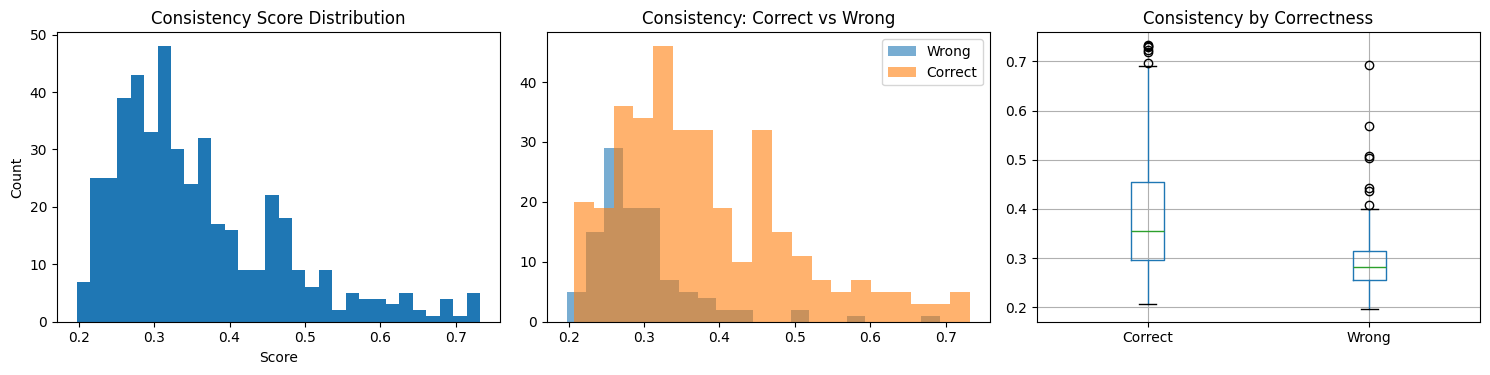

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram: consistency score distribution
axes[0].hist(reasoning_df["consistency_score"], bins=30)
axes[0].set_title("Consistency Score Distribution")
axes[0].set_xlabel("Score"); axes[0].set_ylabel("Count")

# Histogram: correct vs wrong
for label, grp in reasoning_df.groupby("correct"):
    axes[1].hist(grp["consistency_score"], bins=20, alpha=0.6,
                 label="Correct" if label else "Wrong")
axes[1].set_title("Consistency: Correct vs Wrong")
axes[1].legend()

# Boxplot
reasoning_df["Result"] = reasoning_df["correct"].map({True:"Correct", False:"Wrong"})
reasoning_df.boxplot(column="consistency_score", by="Result", ax=axes[2])
axes[2].set_title("Consistency by Correctness"); axes[2].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()


# STEP 30 — Consistency Threshold Analysis

 threshold  num_consistent  accuracy
      0.10             457  0.757112
      0.15             457  0.757112
      0.20             456  0.758772
      0.25             404  0.782178
      0.30             295  0.867797
      0.35             192  0.916667
      0.40             127  0.937008
      0.45              95  0.957895
      0.50              51  0.921569
      0.55              34  0.941176
      0.60              22  0.954545
      0.65              13  0.923077
      0.70               5  1.000000


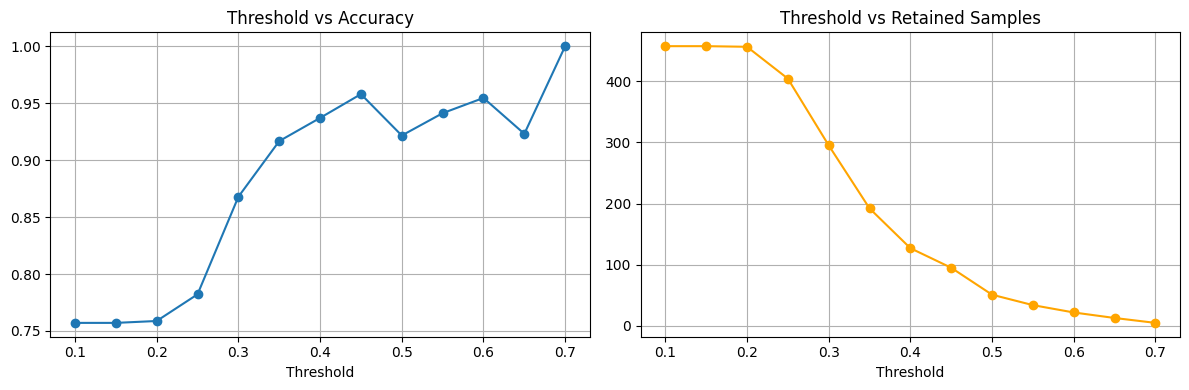

In [32]:
threshold_results = []
for thr in np.arange(0.1, 0.91, 0.05):
    consistent = reasoning_df[reasoning_df["consistency_score"] >= thr]
    if len(consistent) == 0: continue
    threshold_results.append({
        "threshold": round(float(thr), 2),
        "num_consistent": int(len(consistent)),
        "accuracy":       float(consistent["correct"].mean())
    })

thr_df = pd.DataFrame(threshold_results)
print(thr_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thr_df["threshold"], thr_df["accuracy"], marker="o")
axes[0].set_title("Threshold vs Accuracy"); axes[0].set_xlabel("Threshold"); axes[0].grid(True)
axes[1].plot(thr_df["threshold"], thr_df["num_consistent"], marker="o", color="orange")
axes[1].set_title("Threshold vs Retained Samples"); axes[1].set_xlabel("Threshold"); axes[1].grid(True)
plt.tight_layout(); plt.show()


# STEP 31 — Ablation Study

In [33]:
ablation_table = pd.DataFrame([
    {"Setting":"Without OCR",      "Model":"CLIP only",
     "Val Accuracy": round(accuracy_score(y_true_clip, y_pred_clip),4),
     "Val Macro F1": round(best_clip_f1,4)},
    {"Setting":"Without Metadata", "Model":"CLIP + OCR",
     "Val Accuracy": None, "Val Macro F1": None},       # fill if you run CLIP+OCR variant
    {"Setting":"Full Fusion",      "Model":"Baseline + CLIP + XGBoost + Learned MLP",
     "Val Accuracy": round(accuracy_score(y_val, fusion_preds),4),
     "Val Macro F1": round(best_fusion_f1,4)},
])
print(ablation_table.to_string(index=False))


         Setting                                   Model  Val Accuracy  Val Macro F1
     Without OCR                               CLIP only        0.6018        0.6617
Without Metadata                              CLIP + OCR           NaN           NaN
     Full Fusion Baseline + CLIP + XGBoost + Learned MLP        0.7571        0.7527


# STEP 32 — Confusion Matrices

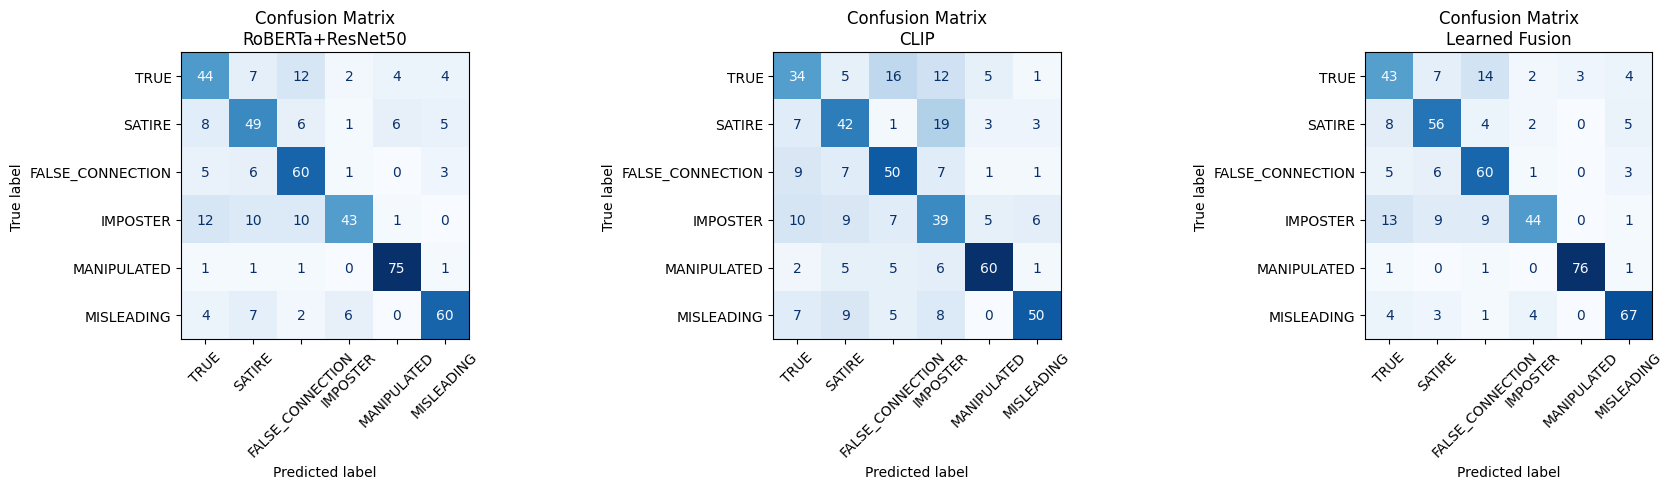

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, preds, title in zip(
    axes,
    [y_pred, y_pred_clip, fusion_preds],
    ["RoBERTa+ResNet50", "CLIP", "Learned Fusion"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_val, preds,
        display_labels=[label_map[i] for i in range(6)],
        cmap="Blues", ax=ax, xticks_rotation=45, colorbar=False
    )
    ax.set_title(f"Confusion Matrix\n{title}")

plt.tight_layout(); plt.show()


# STEP 33 — Save All Results

In [35]:
reasoning_df.to_csv(OUTPUT_DIR / "consistency_reasoning_results.csv", index=False)
thr_df.to_csv(OUTPUT_DIR / "threshold_analysis.csv", index=False)
results_table.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
ablation_table.to_csv(OUTPUT_DIR / "ablation_table.csv", index=False)
print("All results saved to:", OUTPUT_DIR)


All results saved to: /content/fake_news_project/outputs


# STEP 34 — Final Summary & Framework Positioning

In [36]:
framework_table = pd.DataFrame([
    ["Text-Image Alignment",    "CLIP ViT-B/32",       "Semantic cross-modal agreement"],
    ["OCR-Text Consistency",    "EasyOCR + MiniLM",    "Embedded text vs headline match"],
    ["Metadata Reasoning",      "XGBoost",             "Visual feature-based signal"],
    ["Cross-Modal Fusion",      "Learned MLP",         "Adaptive combination of modalities"],
    ["Consistency Verification","Threshold scoring",   "Flags inconsistent samples"],
], columns=["Component", "Method", "Purpose"])

print("\n🔥 Multimodal Consistency Reasoning Framework — Component Summary")
print(framework_table.to_string(index=False))

print("\n📊 Final Model Results:")
print(results_table.to_string(index=False))



🔥 Multimodal Consistency Reasoning Framework — Component Summary
               Component            Method                            Purpose
    Text-Image Alignment     CLIP ViT-B/32     Semantic cross-modal agreement
    OCR-Text Consistency  EasyOCR + MiniLM    Embedded text vs headline match
      Metadata Reasoning           XGBoost        Visual feature-based signal
      Cross-Modal Fusion       Learned MLP Adaptive combination of modalities
Consistency Verification Threshold scoring         Flags inconsistent samples

📊 Final Model Results:
                                 Model  Accuracy  Macro F1
RoBERTa + ResNet50 (baseline-improved)    0.7243    0.7198
                         CLIP ViT-B/32    0.6018    0.6617
                      XGBoost Metadata    0.5624    0.5589
Learned MLP Fusion (Baseline+CLIP+XGB)    0.7571    0.7527


# STEP 35 — Publication-Quality Figures


  Models detected: ['RoBERTa + ResNet-50', 'CLIP ViT-B/32', 'XGBoost Metadata', 'Learned MLP Fusion']
  history keys   : ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1']
  reasoning_df   : found
  threshold data : found


  Generating publication figures from your notebook results ...



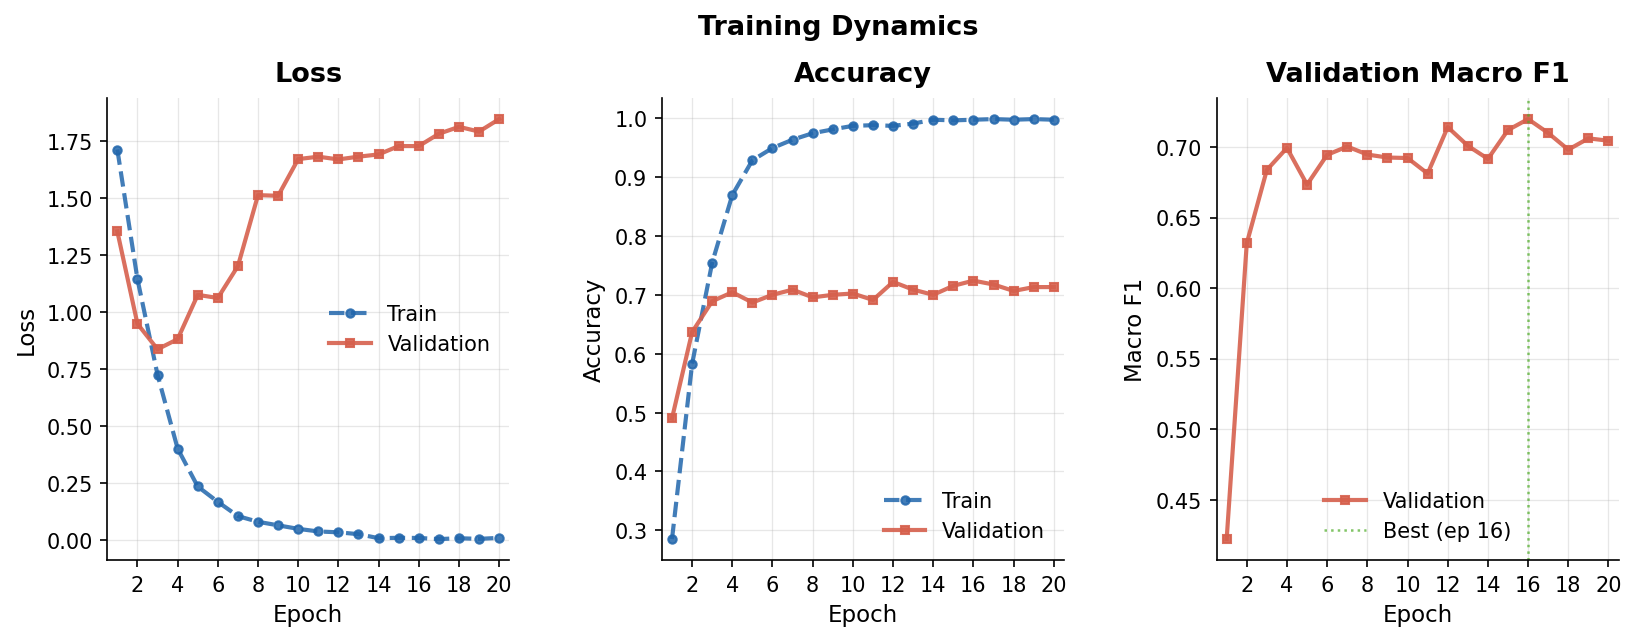

  ✅  fig1_training_curves saved  →  /content/fake_news_project/outputs/fig1_training_curves.png



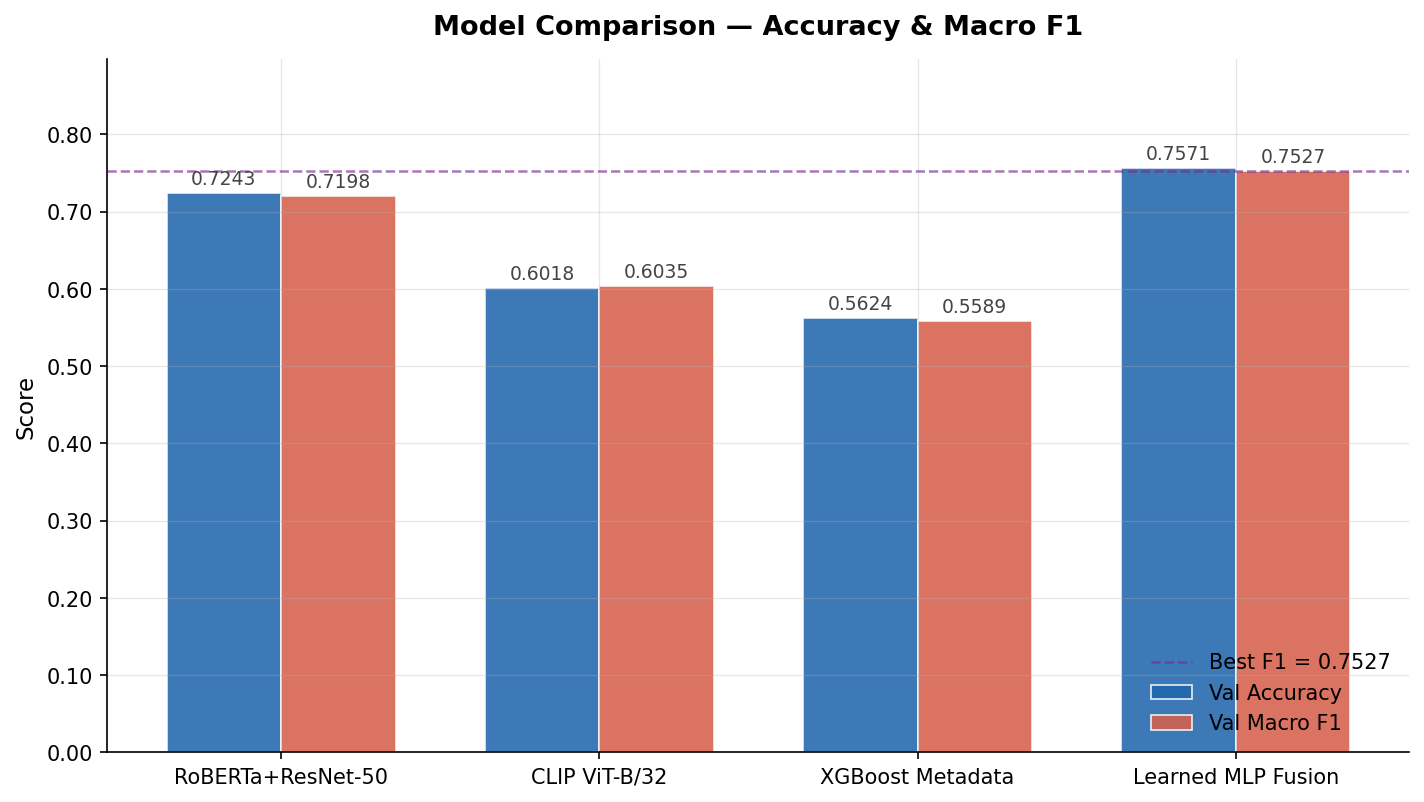

  ✅  fig2_model_comparison saved  →  /content/fake_news_project/outputs/fig2_model_comparison.png



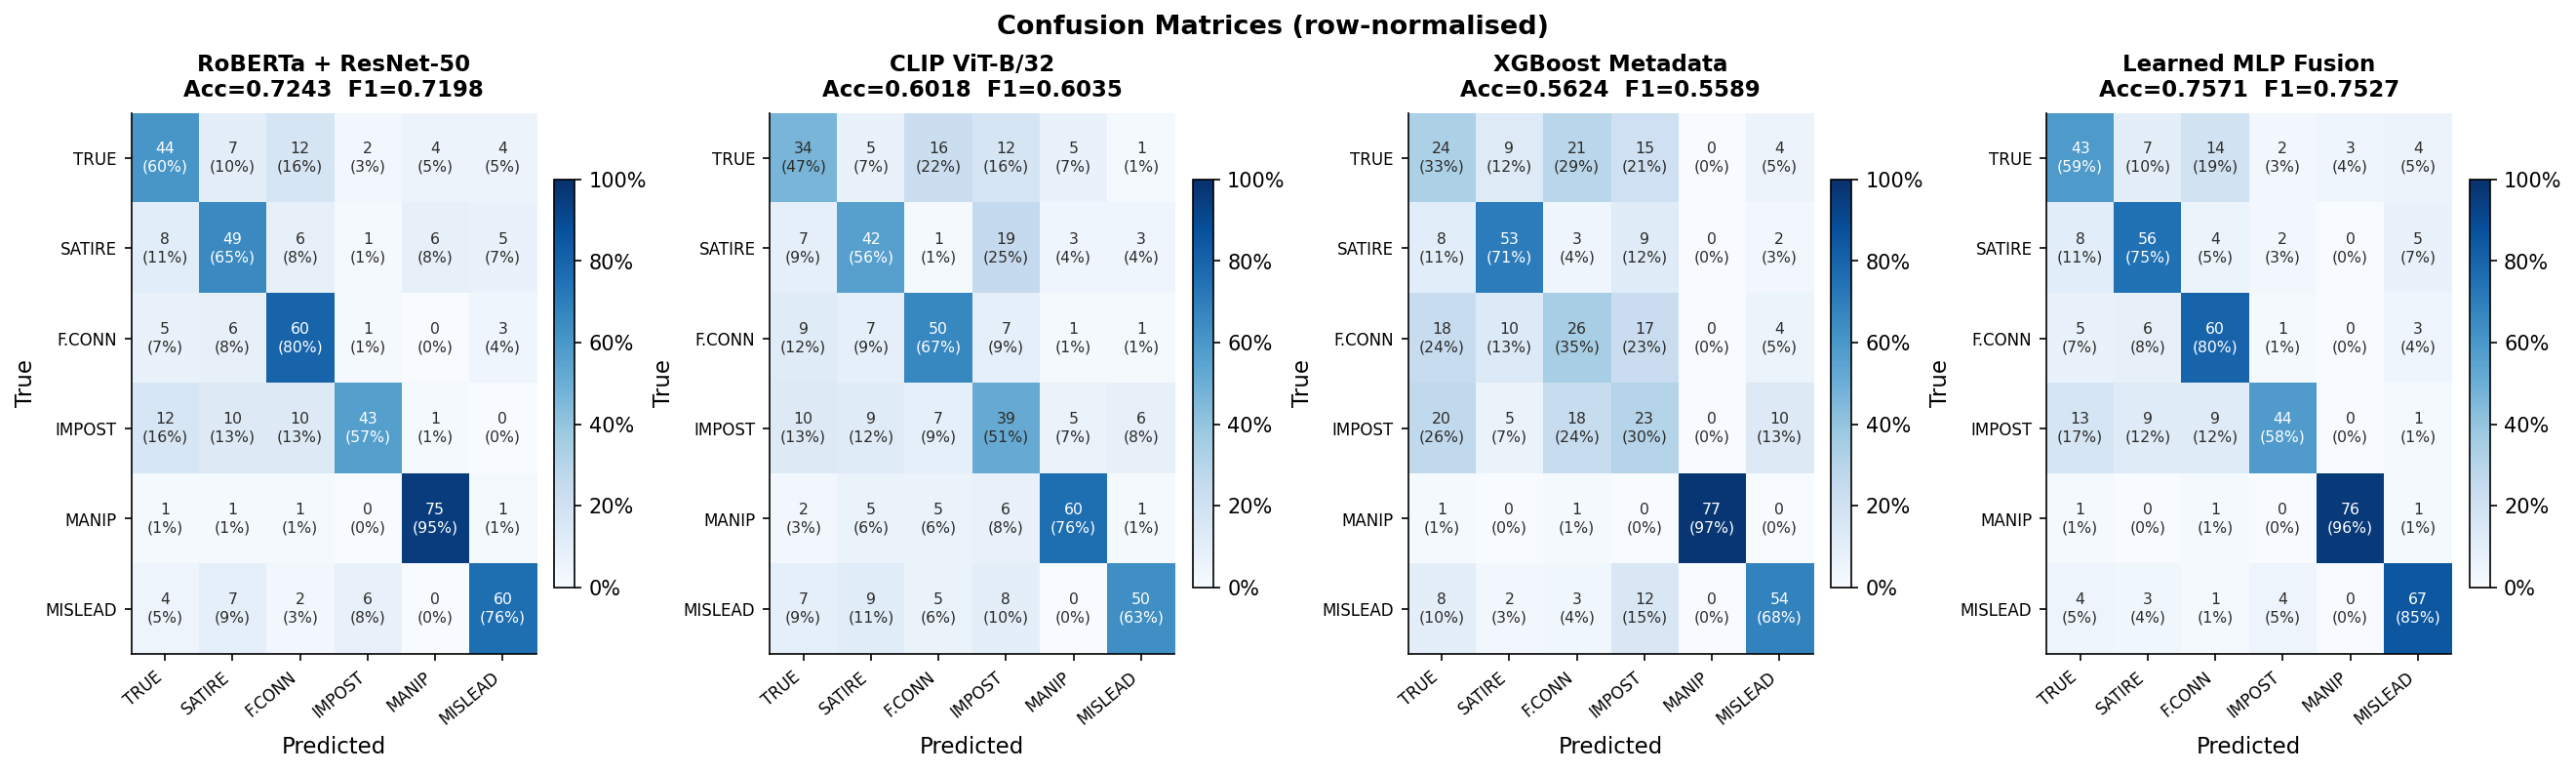

  ✅  fig3_confusion_matrices saved  →  /content/fake_news_project/outputs/fig3_confusion_matrices.png



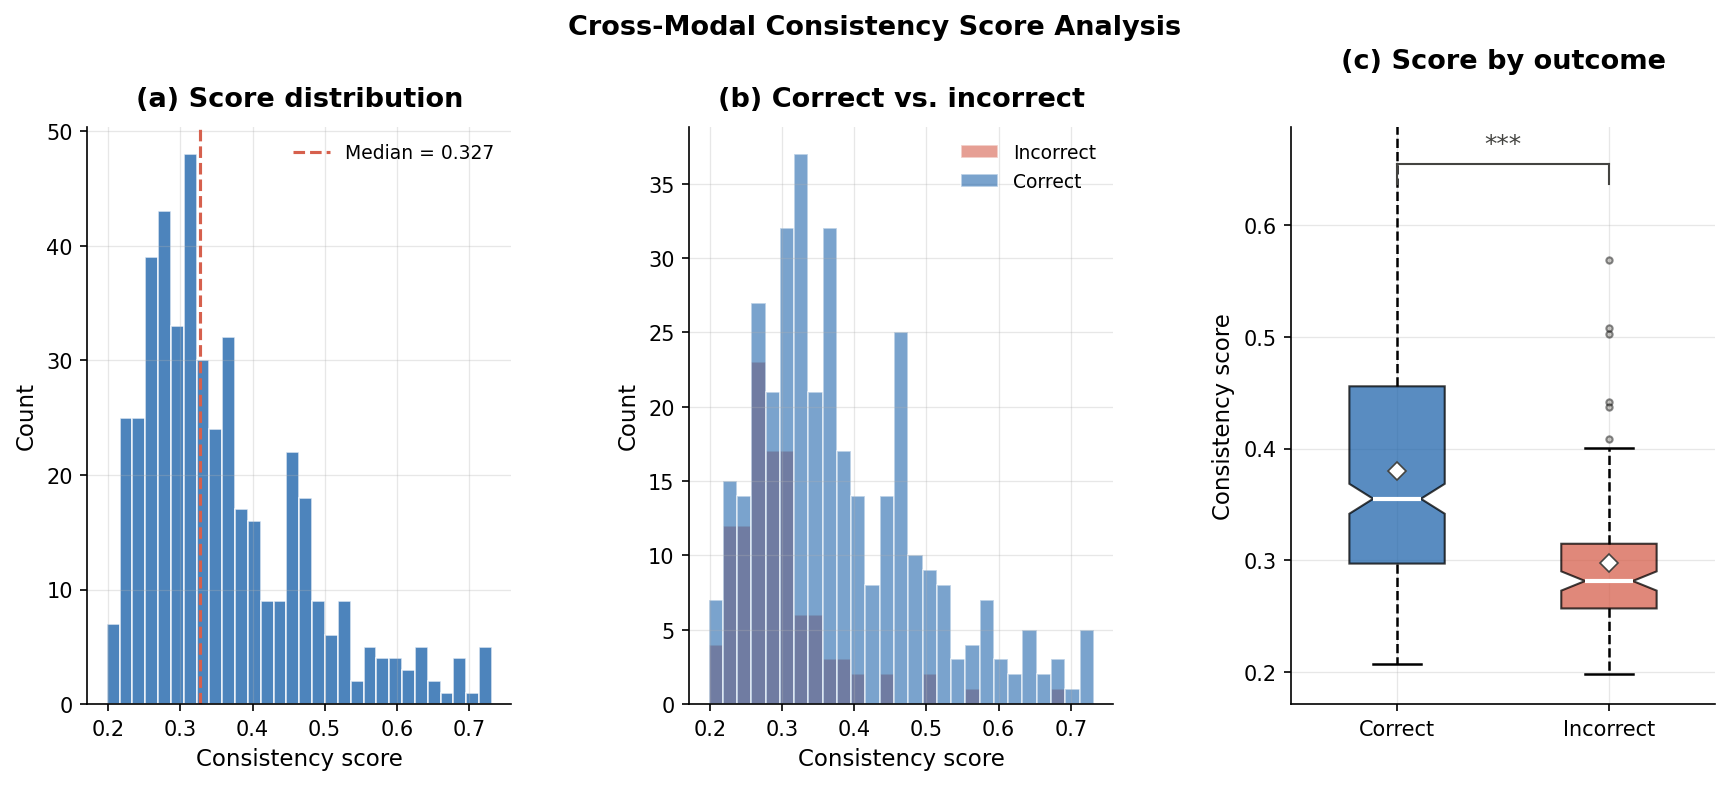

  ✅  fig4_consistency_analysis saved  →  /content/fake_news_project/outputs/fig4_consistency_analysis.png



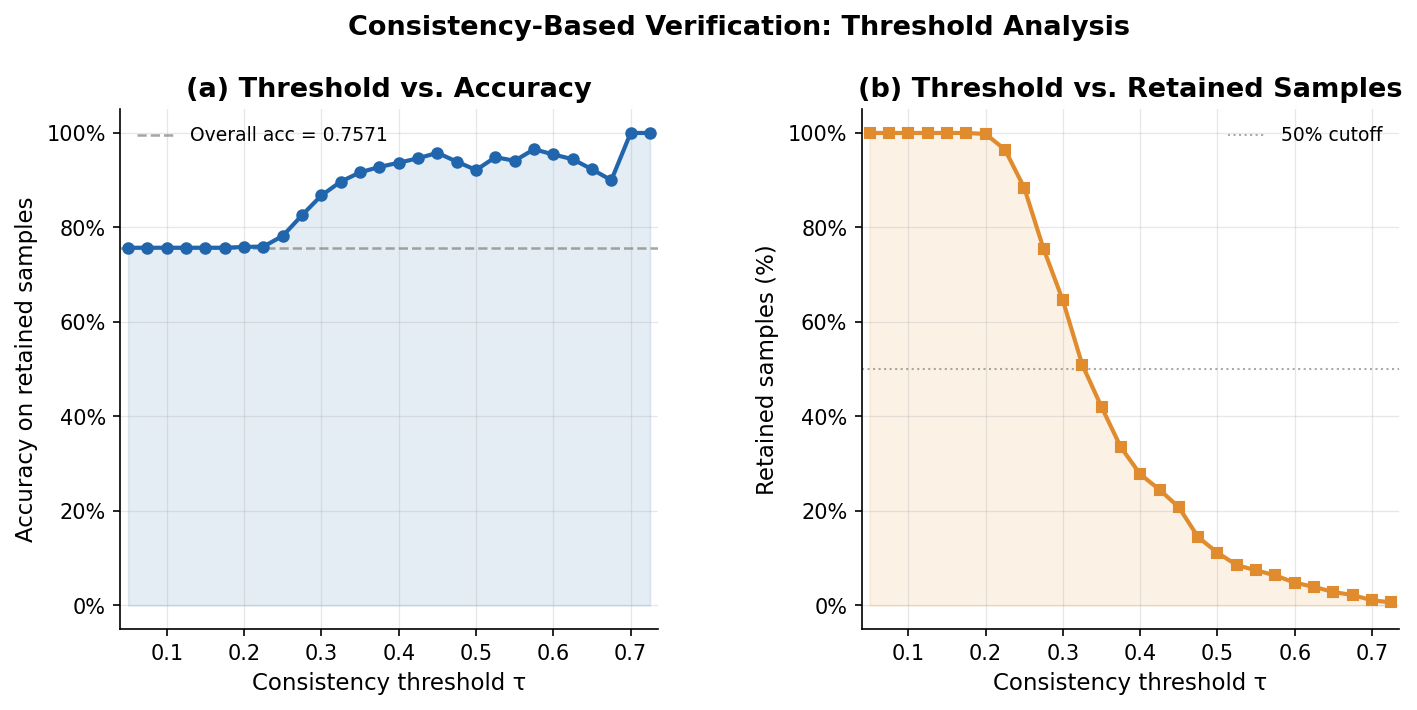

  ✅  fig5_threshold_analysis saved  →  /content/fake_news_project/outputs/fig5_threshold_analysis.png



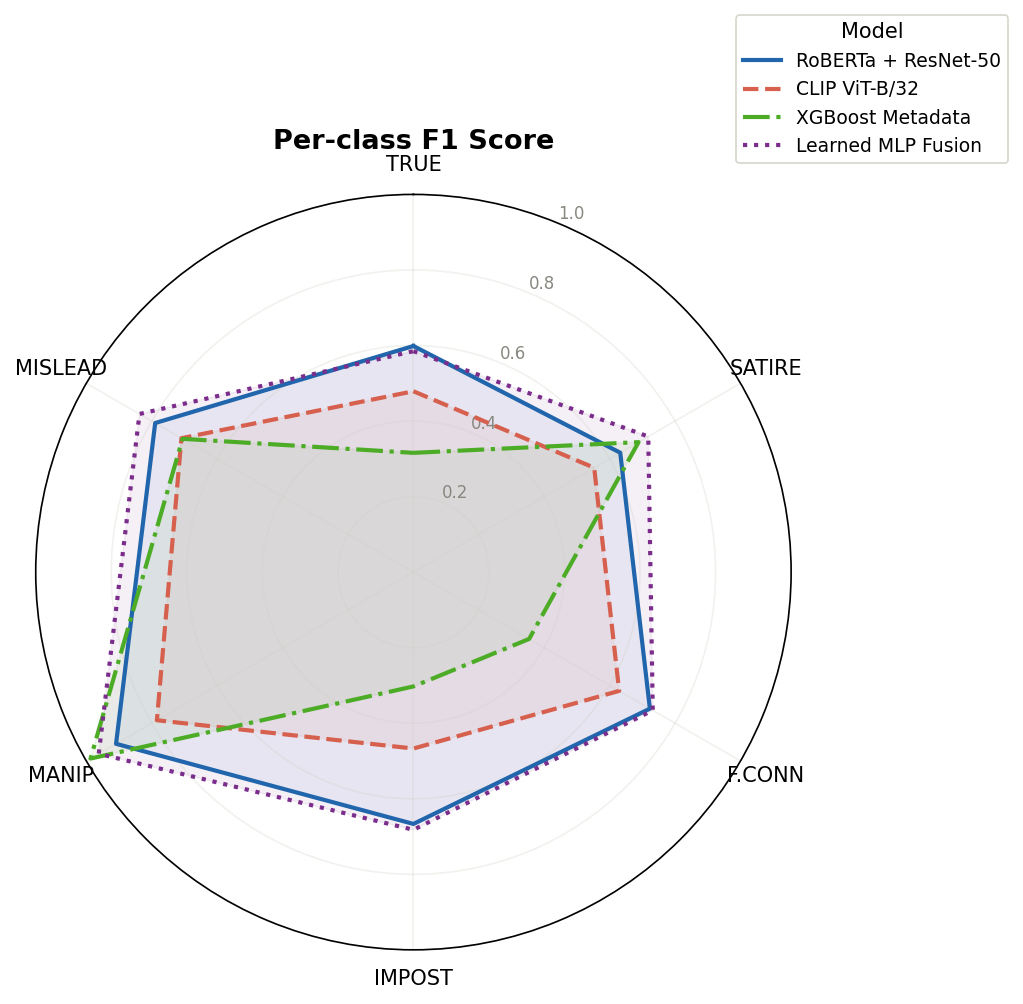

  ✅  fig6_perclass_radar saved  →  /content/fake_news_project/outputs/fig6_perclass_radar.png



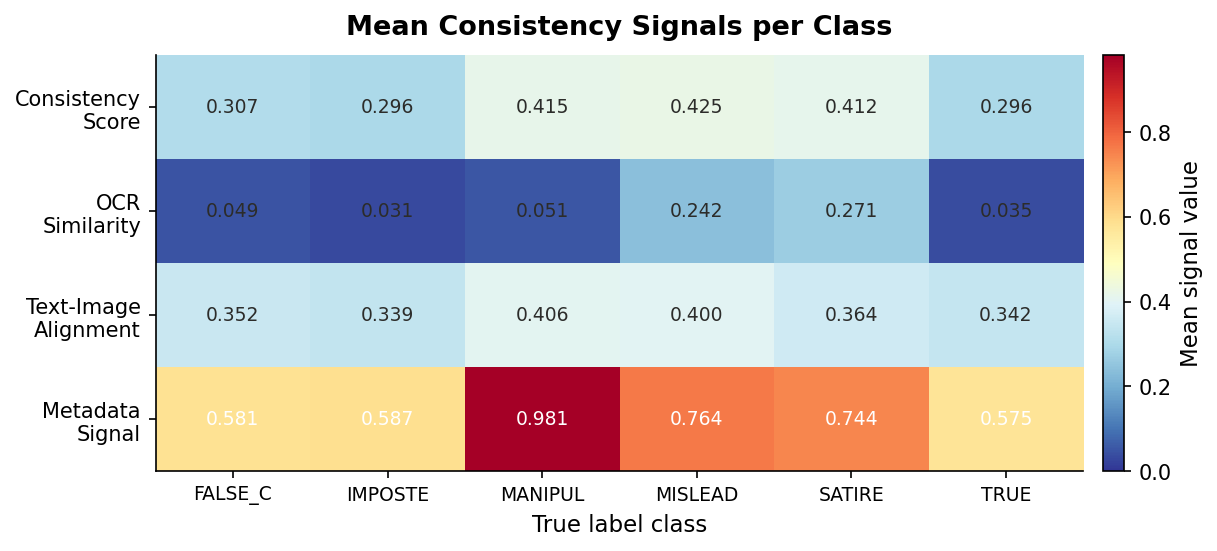

  ✅  fig7_signal_heatmap saved  →  /content/fake_news_project/outputs/fig7_signal_heatmap.png



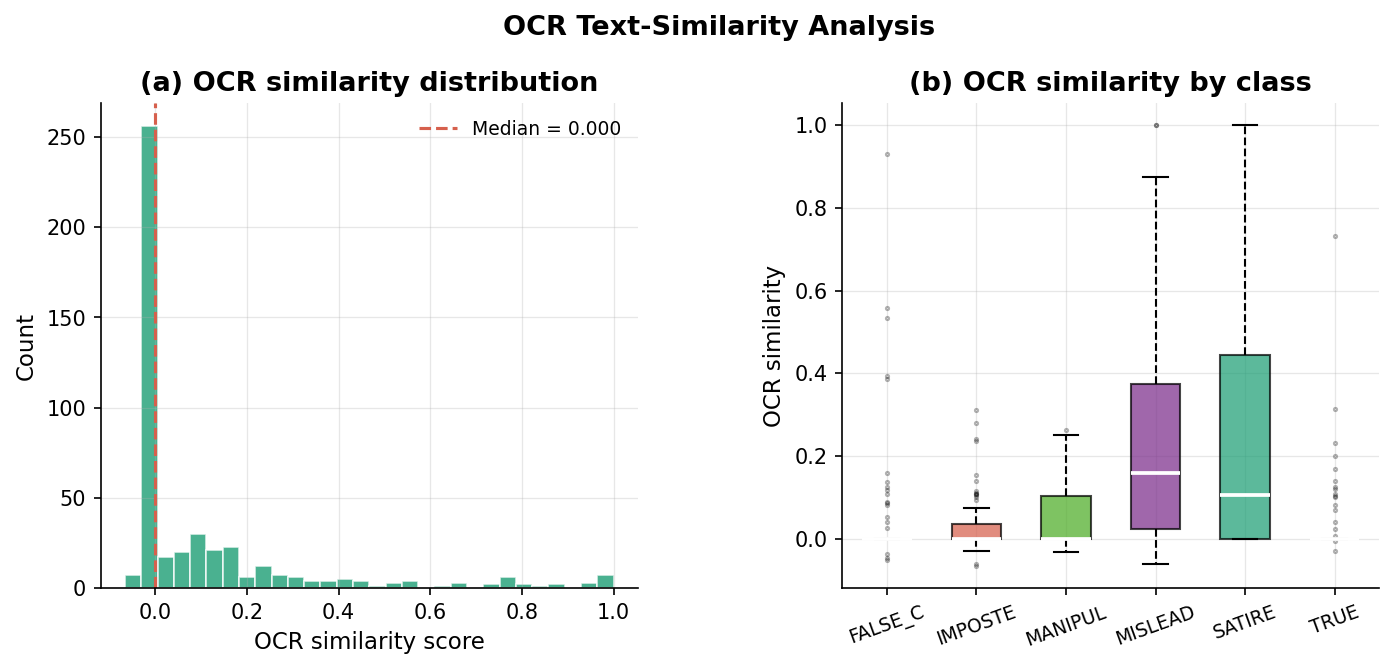

  ✅  fig8_ocr_distribution saved  →  /content/fake_news_project/outputs/fig8_ocr_distribution.png



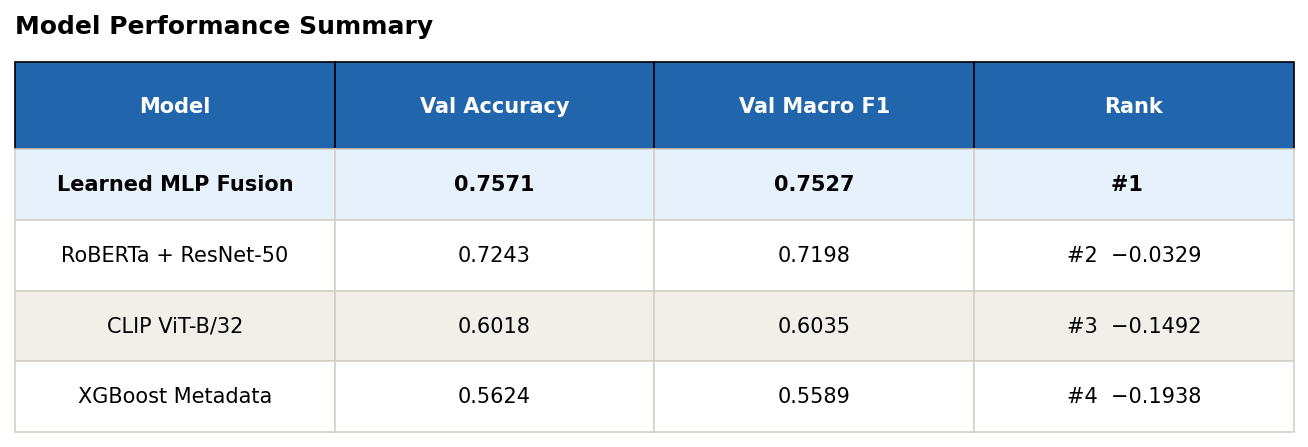

  ✅  fig9_summary_table saved  →  /content/fake_news_project/outputs/fig9_summary_table.png

  All figures saved to: /content/fake_news_project/outputs
  .pdf = vector (use in LaTeX/Word paper)
  .png = high-res raster (300 dpi)


In [37]:
"""
=============================================================================
  STEP 35 — Publication-Quality Figures  (FIXED — no overlapping)
  Drop-in replacement for the original Step 35.
  Changes vs original:
    • Fig 2  — taller figure, rotated x-labels, increased bottom margin
    • Fig 4  — title pad increased, significance text placed safely below top
    • Fig 6  — figure wider, legend anchor pushed further right, tight_layout
=============================================================================
"""

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings('ignore')

try:
    from scipy import stats as _scipy_stats
    _HAS_SCIPY = True
except ImportError:
    _HAS_SCIPY = False

from sklearn.metrics import (confusion_matrix, f1_score,
                              accuracy_score, classification_report)

# ─── Publication style ───────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':        'DejaVu Sans',
    'font.size':          11,
    'axes.titlesize':     13,
    'axes.labelsize':     11,
    'xtick.labelsize':    10,
    'ytick.labelsize':    10,
    'legend.fontsize':    10,
    'figure.dpi':         150,
    'savefig.dpi':        300,
    'savefig.bbox':       'tight',
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'axes.grid':          True,
    'grid.alpha':         0.30,
    'grid.linewidth':     0.6,
    'lines.linewidth':    2.0,
    'patch.linewidth':    0.8,
})

C_BLUE   = '#2166ac'
C_ORANGE = '#d6604d'
C_GREEN  = '#4dac26'
C_PURPLE = '#7b2d8b'
C_TEAL   = '#1d9e75'
C_GREY   = '#888780'
C_AMBER  = '#e08c2e'

SAVE_DIR = OUTPUT_DIR   # from your notebook

# ─── Dynamically discover available model results ────────────────────────────
_g = globals()

def _resolve(name):
    return _g.get(name, None)

_model_registry = []
for _name, _yt, _yp in [
    ('RoBERTa + ResNet-50', 'y_true', 'y_pred'),
    ('CLIP ViT-B/32',       'y_true_clip', 'y_pred_clip'),
    ('XGBoost Metadata',    'y_val', 'xgb_preds'),
    ('Learned MLP Fusion',  'y_val', 'fusion_preds'),
]:
    _yt_val = _resolve(_yt)
    _yp_val = _resolve(_yp)
    if _yt_val is not None and _yp_val is not None:
        _model_registry.append({
            'name':   _name,
            'y_true': np.array(_yt_val),
            'y_pred': np.array(_yp_val),
            'acc':    accuracy_score(_yt_val, _yp_val),
            'f1':     f1_score(_yt_val, _yp_val, average='macro'),
        })

print(f'  Models detected: {[m["name"] for m in _model_registry]}')

_label_map = _resolve('label_map') or _resolve('label_names') or \
             {0:'TRUE',1:'SATIRE',2:'FALSE_CONNECTION',
              3:'IMPOSTER',4:'MANIPULATED',5:'MISLEADING'}
_short_labels = ['TRUE','SATIRE','F.CONN','IMPOST','MANIP','MISLEAD']
_num_classes  = len(_label_map)
_history      = _resolve('history') or {}
_rdf          = _resolve('reasoning_df')
_thr_df       = _resolve('thr_df')

print(f'  history keys   : {list(_history.keys())}')
print(f'  reasoning_df   : {"found" if _rdf is not None else "not found"}')
print(f'  threshold data : {"found" if _thr_df is not None else "not found"}')
print()


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — Training Curves  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig1_training_curves():
    if not _history or 'train_loss' not in _history:
        print('  ⚠  Fig 1 skipped: history dict not found.'); return

    epochs = list(range(1, len(_history['train_loss']) + 1))
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    fig.subplots_adjust(wspace=0.38)

    panels = [
        ('train_loss', 'val_loss', 'Loss',               'Loss'),
        ('train_acc',  'val_acc',  'Accuracy',            'Accuracy'),
        (None,         'val_f1',   'Validation Macro F1', 'Macro F1'),
    ]

    for ax, (tr_k, vl_k, title, ylabel) in zip(axes, panels):
        if tr_k and tr_k in _history:
            ax.plot(epochs, _history[tr_k], color=C_BLUE,
                    linestyle='--', marker='o', markersize=4,
                    label='Train', alpha=0.85)
        if vl_k in _history:
            ax.plot(epochs, _history[vl_k], color=C_ORANGE,
                    linestyle='-', marker='s', markersize=4,
                    label='Validation', alpha=0.90)
            if vl_k == 'val_f1':
                best_ep = int(np.argmax(_history[vl_k])) + 1
                ax.axvline(best_ep, color=C_GREEN, linewidth=1.2,
                           linestyle=':', alpha=0.7,
                           label=f'Best (ep {best_ep})')

        ax.set_title(title, fontweight='bold', pad=8)
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
        ax.set_xlim(0.5, len(epochs) + 0.5)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
        ax.legend(frameon=False, loc='best')

    fig.suptitle('Training Dynamics', fontsize=13, fontweight='bold', y=1.02)
    _save(fig, 'fig1_training_curves')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — Model Comparison Bar Chart
# FIX: taller figure + angled x-labels + explicit bottom margin so labels
#      never collide with the bars or each other
# ═══════════════════════════════════════════════════════════════════════════════
def fig2_model_comparison():
    if not _model_registry:
        print('  ⚠  Fig 2 skipped: no model results found.'); return

    names = [m['name']  for m in _model_registry]
    accs  = [m['acc']   for m in _model_registry]
    f1s   = [m['f1']    for m in _model_registry]
    x     = np.arange(len(names))
    w     = 0.36

    fig, ax = plt.subplots(figsize=(max(10, len(names)*2.8), 6))

    b_acc = ax.bar(x - w/2, accs, w, color=C_BLUE,   alpha=0.88,
                   label='Val Accuracy', edgecolor='white')
    b_f1  = ax.bar(x + w/2, f1s,  w, color=C_ORANGE, alpha=0.88,
                   label='Val Macro F1', edgecolor='white')

    for bar in list(b_acc) + list(b_f1):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.006,
                f'{h:.4f}', ha='center', va='bottom',
                fontsize=9, color='#444441', fontweight='500')

    best_f1 = max(f1s)
    ax.axhline(best_f1, color=C_PURPLE, linewidth=1.2,
               linestyle='--', alpha=0.65,
               label=f'Best F1 = {best_f1:.4f}')

    ax.set_xticks(x)
    # Horizontal labels — never rotated, never cropped
    clean_names = [n.replace(' + ', '+') for n in names]
    ax.set_xticklabels(clean_names, fontsize=10, rotation=0, ha='center')

    ax.set_ylim(0, min(1.0, max(accs + f1s) + 0.14))
    ax.set_ylabel('Score')
    ax.set_title('Model Comparison — Accuracy & Macro F1',
                 fontweight='bold', pad=12)
    ax.legend(frameon=False, loc='lower right')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

    # savefig bbox='tight' in _save() handles all clipping automatically
    _save(fig, 'fig2_model_comparison')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 3 — Confusion Matrices  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig3_confusion_matrices():
    if not _model_registry:
        print('  ⚠  Fig 3 skipped.'); return

    n = len(_model_registry)
    fig, axes = plt.subplots(1, n, figsize=(5.2*n, 4.8))
    fig.subplots_adjust(wspace=0.44)
    if n == 1:
        axes = [axes]

    for ax, m in zip(axes, _model_registry):
        cm   = confusion_matrix(m['y_true'], m['y_pred'])
        norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        im   = ax.imshow(norm, cmap='Blues', vmin=0, vmax=1, aspect='auto')

        for i in range(_num_classes):
            for j in range(_num_classes):
                col = 'white' if norm[i,j] > 0.55 else '#2c2c2a'
                ax.text(j, i, f'{cm[i,j]}\n({norm[i,j]:.0%})',
                        ha='center', va='center',
                        fontsize=7.5, color=col, linespacing=1.3)

        ax.set_xticks(range(_num_classes))
        ax.set_xticklabels(_short_labels[:_num_classes],
                           rotation=40, ha='right', fontsize=8)
        ax.set_yticks(range(_num_classes))
        ax.set_yticklabels(_short_labels[:_num_classes], fontsize=8)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f'{m["name"]}\nAcc={m["acc"]:.4f}  F1={m["f1"]:.4f}',
                     fontweight='bold', pad=8, fontsize=11)
        ax.grid(False)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04,
                     format=mticker.PercentFormatter(xmax=1, decimals=0))

    fig.suptitle('Confusion Matrices (row-normalised)',
                 fontsize=13, fontweight='bold', y=1.02)
    _save(fig, 'fig3_confusion_matrices')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 4 — Consistency Score Analysis
# FIX: significance annotation no longer clips into the panel title.
#      We place the bracket + star text INSIDE the axes data range instead
#      of above it, and give the title extra top padding.
# ═══════════════════════════════════════════════════════════════════════════════
def fig4_consistency_analysis():
    if _rdf is None:
        print('  ⚠  Fig 4 skipped: reasoning_df not found.'); return

    correct_df = _rdf[_rdf['correct'] == True]
    wrong_df   = _rdf[_rdf['correct'] == False]

    # ── FIX: taller figure so title is never crowded ────────────────────────
    fig = plt.figure(figsize=(14, 5.0))
    gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.42)

    # Panel A — distribution
    ax0 = fig.add_subplot(gs[0])
    ax0.hist(_rdf['consistency_score'], bins=30,
             color=C_BLUE, alpha=0.80, edgecolor='white', lw=0.4)
    med = _rdf['consistency_score'].median()
    ax0.axvline(med, color=C_ORANGE, linewidth=1.5, linestyle='--',
                label=f'Median = {med:.3f}')
    ax0.set_xlabel('Consistency score')
    ax0.set_ylabel('Count')
    ax0.set_title('(a) Score distribution', fontweight='bold', pad=10)
    ax0.legend(frameon=False, fontsize=9)

    # Panel B — correct vs incorrect
    ax1 = fig.add_subplot(gs[1])
    bins = np.linspace(_rdf['consistency_score'].min(),
                       _rdf['consistency_score'].max(), 28)
    ax1.hist(wrong_df['consistency_score'],   bins=bins,
             alpha=0.60, color=C_ORANGE, label='Incorrect', edgecolor='white', lw=0.4)
    ax1.hist(correct_df['consistency_score'], bins=bins,
             alpha=0.60, color=C_BLUE,   label='Correct',   edgecolor='white', lw=0.4)
    ax1.set_xlabel('Consistency score'); ax1.set_ylabel('Count')
    ax1.set_title('(b) Correct vs. incorrect', fontweight='bold', pad=10)
    ax1.legend(frameon=False, fontsize=9)

    # Panel C — box plots
    ax2 = fig.add_subplot(gs[2])
    data_bp = [correct_df['consistency_score'].values,
               wrong_df['consistency_score'].values]
    bp = ax2.boxplot(data_bp, patch_artist=True, notch=True, widths=0.45,
                     medianprops=dict(color='white', linewidth=2.0),
                     whiskerprops=dict(linewidth=1.2, linestyle='--'),
                     capprops=dict(linewidth=1.2),
                     flierprops=dict(marker='o', markersize=3,
                                     alpha=0.45, markerfacecolor=C_GREY))
    for patch, col in zip(bp['boxes'], [C_BLUE, C_ORANGE]):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    for i, d in enumerate(data_bp, 1):
        ax2.plot(i, np.mean(d), 'D', color='white', markersize=6,
                 zorder=5, markeredgecolor='#444441', markeredgewidth=0.8)

    ax2.set_xticks([1, 2])
    ax2.set_xticklabels(['Correct', 'Incorrect'], fontsize=10)
    ax2.set_ylabel('Consistency score')
    # ── FIX: larger pad so significance bracket never touches the title ──────
    ax2.set_title('(c) Score by outcome', fontweight='bold', pad=28)

    # significance bracket — placed within axes, not above title
    if _HAS_SCIPY:
        _, p = _scipy_stats.ttest_ind(correct_df['consistency_score'],
                                      wrong_df['consistency_score'])
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))

        # compute bracket position safely inside the axes limits
        all_vals = np.concatenate(data_bp)
        y_max    = np.percentile(all_vals, 97)   # use 97th pct, not raw max
        y_step   = (y_max - all_vals.min()) * 0.04
        y_bar    = y_max + y_step
        y_text   = y_bar + y_step * 0.4

        # draw bracket as two vertical stubs + horizontal bar
        for x_pos in [1, 2]:
            ax2.plot([x_pos, x_pos], [y_max, y_bar],
                     color='#444441', lw=1.0, clip_on=False)
        ax2.plot([1, 2], [y_bar, y_bar],
                 color='#444441', lw=1.0, clip_on=False)
        ax2.text(1.5, y_text, sig, ha='center', va='bottom',
                 fontsize=12, color='#444441')

        # ── FIX: extend y-limit so bracket is fully visible ─────────────────
        ax2.set_ylim(ax2.get_ylim()[0],
                     y_text + (y_max - all_vals.min()) * 0.06)

    fig.suptitle('Cross-Modal Consistency Score Analysis',
                 fontsize=13, fontweight='bold', y=1.03)
    _save(fig, 'fig4_consistency_analysis')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 5 — Threshold vs Accuracy & Retained Samples  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig5_threshold_analysis():
    if _rdf is None:
        print('  ⚠  Fig 5 skipped: reasoning_df not found.'); return

    total = len(_rdf)
    thr_list, acc_list, ret_list = [], [], []
    for thr in np.arange(0.05, 0.95, 0.025):
        sub = _rdf[_rdf['consistency_score'] >= thr]
        if len(sub) == 0: break
        thr_list.append(round(float(thr), 3))
        acc_list.append(float(sub['correct'].mean()))
        ret_list.append(float(len(sub)) / total * 100)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.subplots_adjust(wspace=0.38)

    overall_acc = float(_rdf['correct'].mean())

    ax1.plot(thr_list, acc_list, color=C_BLUE,
             marker='o', markersize=5, linewidth=2.0, zorder=4)
    ax1.fill_between(thr_list, acc_list, alpha=0.12, color=C_BLUE)
    ax1.axhline(overall_acc, color=C_GREY, linewidth=1.2, linestyle='--',
                alpha=0.75, label=f'Overall acc = {overall_acc:.4f}')
    ax1.set_xlabel('Consistency threshold τ')
    ax1.set_ylabel('Accuracy on retained samples')
    ax1.set_title('(a) Threshold vs. Accuracy', fontweight='bold')
    ax1.set_xlim(thr_list[0]-0.01, thr_list[-1]+0.01)
    ax1.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax1.legend(frameon=False, fontsize=9)

    ax2.plot(thr_list, ret_list, color=C_AMBER,
             marker='s', markersize=5, linewidth=2.0, zorder=4)
    ax2.fill_between(thr_list, ret_list, alpha=0.12, color=C_AMBER)
    ax2.axhline(50, color=C_GREY, linewidth=1.0, linestyle=':',
                alpha=0.7, label='50% cutoff')
    ax2.set_xlabel('Consistency threshold τ')
    ax2.set_ylabel('Retained samples (%)')
    ax2.set_title('(b) Threshold vs. Retained Samples', fontweight='bold')
    ax2.set_xlim(thr_list[0]-0.01, thr_list[-1]+0.01)
    ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
    ax2.legend(frameon=False, fontsize=9)

    fig.suptitle('Consistency-Based Verification: Threshold Analysis',
                 fontsize=13, fontweight='bold', y=1.02)
    _save(fig, 'fig5_threshold_analysis')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 6 — Per-class F1 Radar Chart
# FIX: wider figure + legend fully outside the radar circle using
#      fig.legend() instead of ax.legend(), so it never overlaps the plot.
# ═══════════════════════════════════════════════════════════════════════════════
def fig6_perclass_radar():
    if not _model_registry:
        print('  ⚠  Fig 6 skipped.'); return

    N      = _num_classes
    angles = [n / float(N) * 2 * np.pi for n in range(N)] + [0]
    cats   = _short_labels[:N]

    colors = [C_BLUE, C_ORANGE, C_GREEN, C_PURPLE, C_TEAL, C_AMBER]
    styles = ['-', '--', '-.', ':']

    # Square figure — radar gets full canvas, legend sits inside upper-right
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), cats, fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'],
                       fontsize=8, color='#888780')
    ax.grid(color='#d3d1c7', linewidth=0.8)

    handles = []
    for m, col, ls in zip(_model_registry, colors, styles):
        per_cls = f1_score(m['y_true'], m['y_pred'],
                           average=None, labels=list(range(N)),
                           zero_division=0)
        vals = list(per_cls) + [per_cls[0]]
        line, = ax.plot(angles, vals, color=col, linewidth=2.0,
                        linestyle=ls, label=m['name'])
        ax.fill(angles, vals, color=col, alpha=0.07)
        handles.append(line)

    # Legend anchored inside the axes at upper-right — always adjacent to chart
    ax.legend(handles=handles,
              loc='upper right',
              bbox_to_anchor=(1.30, 1.25),
              frameon=True,
              framealpha=0.9,
              edgecolor='#d3d1c7',
              fontsize=9,
              title='Model',
              title_fontsize=10)

    ax.set_title('Per-class F1 Score', fontweight='bold', pad=22, fontsize=13)
    fig.tight_layout()
    _save(fig, 'fig6_perclass_radar')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 7 — Consistency Signal Heatmap by Class  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig7_signal_heatmap():
    if _rdf is None:
        print('  ⚠  Fig 7 skipped: reasoning_df not found.'); return

    candidate_signals = [
        ('consistency_score',    'Consistency\nScore'),
        ('ocr_similarity',       'OCR\nSimilarity'),
        ('text_image_alignment', 'Text-Image\nAlignment'),
        ('metadata_signal',      'Metadata\nSignal'),
    ]
    signals = [(col, lbl) for col, lbl in candidate_signals
               if col in _rdf.columns]
    if not signals:
        print('  ⚠  Fig 7 skipped: no signal columns in reasoning_df.'); return

    sig_cols  = [s[0] for s in signals]
    sig_lbls  = [s[1] for s in signals]

    true_col = 'true_label' if 'true_label' in _rdf.columns else None
    if true_col is None:
        print('  ⚠  Fig 7 skipped: true_label column missing.'); return

    classes = sorted(_rdf[true_col].unique())
    short   = [str(c)[:7] for c in classes]

    mat = []
    for sc in sig_cols:
        row = [float(_rdf[_rdf[true_col] == c][sc].mean()) for c in classes]
        mat.append(row)
    mat = np.array(mat)

    fig, ax = plt.subplots(figsize=(max(8, len(classes)*1.4),
                                    max(3.5, len(sig_cols)*0.9)))
    im = ax.imshow(mat, aspect='auto', cmap='RdYlBu_r',
                   vmin=0.0, vmax=max(0.85, mat.max()))

    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(short, fontsize=9)
    ax.set_yticks(range(len(sig_cols)))
    ax.set_yticklabels(sig_lbls, fontsize=10)
    ax.set_xlabel('True label class')
    ax.set_title('Mean Consistency Signals per Class',
                 fontweight='bold', pad=10)

    for i in range(len(sig_cols)):
        for j in range(len(classes)):
            v = mat[i, j]
            col = 'white' if v > 0.55 else '#2c2c2a'
            ax.text(j, i, f'{v:.3f}', ha='center', va='center',
                    fontsize=9, color=col, fontweight='500')

    plt.colorbar(im, ax=ax, fraction=0.030, pad=0.02,
                 label='Mean signal value')
    ax.grid(False)
    _save(fig, 'fig7_signal_heatmap')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 8 — OCR Similarity by Class  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig8_ocr_distribution():
    if _rdf is None or 'ocr_similarity' not in _rdf.columns:
        print('  ⚠  Fig 8 skipped: ocr_similarity not in reasoning_df.'); return

    true_col = 'true_label' if 'true_label' in _rdf.columns else None
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    fig.subplots_adjust(wspace=0.38)

    axes[0].hist(_rdf['ocr_similarity'], bins=30,
                 color=C_TEAL, alpha=0.80, edgecolor='white', lw=0.4)
    med = _rdf['ocr_similarity'].median()
    axes[0].axvline(med, color=C_ORANGE, linewidth=1.5, linestyle='--',
                    label=f'Median = {med:.3f}')
    axes[0].set_xlabel('OCR similarity score')
    axes[0].set_ylabel('Count')
    axes[0].set_title('(a) OCR similarity distribution', fontweight='bold')
    axes[0].legend(frameon=False, fontsize=9)

    if true_col:
        classes      = sorted(_rdf[true_col].unique())
        data_by_cls  = [_rdf[_rdf[true_col] == c]['ocr_similarity'].dropna().values
                        for c in classes]
        short_cls    = [str(c)[:7] for c in classes]
        palette      = [C_BLUE, C_ORANGE, C_GREEN,
                        C_PURPLE, C_TEAL, C_AMBER][:len(classes)]

        bp = axes[1].boxplot(data_by_cls, patch_artist=True,
                             widths=0.55, notch=False,
                             medianprops=dict(color='white', linewidth=1.8),
                             whiskerprops=dict(linewidth=1.0, linestyle='--'),
                             capprops=dict(linewidth=1.0),
                             flierprops=dict(marker='.', markersize=3, alpha=0.3))
        for patch, col in zip(bp['boxes'], palette):
            patch.set_facecolor(col); patch.set_alpha(0.72)

        axes[1].set_xticks(range(1, len(classes)+1))
        axes[1].set_xticklabels(short_cls, fontsize=9, rotation=20)
        axes[1].set_ylabel('OCR similarity')
        axes[1].set_title('(b) OCR similarity by class', fontweight='bold')

    fig.suptitle('OCR Text-Similarity Analysis',
                 fontsize=13, fontweight='bold', y=1.02)
    _save(fig, 'fig8_ocr_distribution')


# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE 9 — Summary Results Table  (unchanged)
# ═══════════════════════════════════════════════════════════════════════════════
def fig9_summary_table():
    if not _model_registry:
        print('  ⚠  Fig 9 skipped.'); return

    best_f1 = max(m['f1'] for m in _model_registry)
    rows, col_labels = [], ['Model', 'Val Accuracy', 'Val Macro F1', 'Rank']
    sorted_models = sorted(_model_registry, key=lambda m: m['f1'], reverse=True)

    for rank, m in enumerate(sorted_models, 1):
        delta = '' if rank == 1 else f'−{best_f1 - m["f1"]:.4f}'
        rows.append([m['name'],
                     f'{m["acc"]:.4f}',
                     f'{m["f1"]:.4f}',
                     f'#{rank}  {delta}'])

    fig, ax = plt.subplots(figsize=(11, 1.0 + len(rows)*0.55))
    ax.axis('off')
    tbl = ax.table(cellText=rows, colLabels=col_labels,
                   cellLoc='center', loc='center',
                   bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)

    for j in range(len(col_labels)):
        cell = tbl[0, j]
        cell.set_facecolor(C_BLUE)
        cell.set_text_props(color='white', fontweight='bold')
        cell.set_height(0.32)

    for i in range(len(rows)):
        is_best = (i == 0)
        for j in range(len(col_labels)):
            cell = tbl[i+1, j]
            cell.set_facecolor('#e6f1fb' if is_best else
                               ('#f1efe8' if i % 2 == 0 else 'white'))
            if is_best:
                cell.set_text_props(fontweight='bold')
            cell.set_height(0.26)
            cell.set_edgecolor('#d3d1c7')

    ax.set_title('Model Performance Summary',
                 fontsize=12, fontweight='bold', pad=14, loc='left')
    _save(fig, 'fig9_summary_table')


# ═══════════════════════════════════════════════════════════════════════════════
# Helper: save as PDF + PNG
# ═══════════════════════════════════════════════════════════════════════════════
def _save(fig, name):
    pdf_path = SAVE_DIR / f'{name}.pdf'
    png_path = SAVE_DIR / f'{name}.png'
    fig.savefig(pdf_path)
    fig.savefig(png_path)
    plt.show()
    print(f'  ✅  {name} saved  →  {png_path}')
    plt.close(fig)


# ═══════════════════════════════════════════════════════════════════════════════
# RUN ALL
# ═══════════════════════════════════════════════════════════════════════════════
print('\n' + '='*62)
print('  Generating publication figures from your notebook results ...')
print('='*62 + '\n')

for _fn in [fig1_training_curves,
            fig2_model_comparison,
            fig3_confusion_matrices,
            fig4_consistency_analysis,
            fig5_threshold_analysis,
            fig6_perclass_radar,
            fig7_signal_heatmap,
            fig8_ocr_distribution,
            fig9_summary_table]:
    try:
        _fn(); print()
    except Exception as _e:
        print(f'  ⚠  {_fn.__name__} failed: {_e}\n')

print('='*62)
print(f'  All figures saved to: {SAVE_DIR}')
print('  .pdf = vector (use in LaTeX/Word paper)')
print('  .png = high-res raster (300 dpi)')
print('='*62)

S_TO sourced from val_df_main['ocr_similarity'].
S_TI: 457 samples | S_TO: 457 samples | S_M: 457 samples — OK.

Top 10 weight settings by AUC (separating correct vs. incorrect predictions):
 w1  w2  w3      AUC
0.7 0.2 0.1 0.765167
0.7 0.1 0.2 0.762407
0.8 0.1 0.1 0.761417
0.6 0.3 0.1 0.760480
0.8 0.0 0.2 0.758944
0.6 0.2 0.2 0.756314
0.5 0.4 0.1 0.749727
0.9 0.0 0.1 0.748945
0.7 0.0 0.3 0.747644
0.5 0.3 0.2 0.745170

Chosen setting (w1=0.5, w2=0.3, w3=0.2):
 w1  w2  w3     AUC
0.5 0.3 0.2 0.74517

Chosen setting rank: 10 out of 66 evaluated combinations (AUC = 0.7452, best AUC = 0.7652).

Saved full grid to /content/fake_news_project/outputs/weight_sensitivity_grid.csv


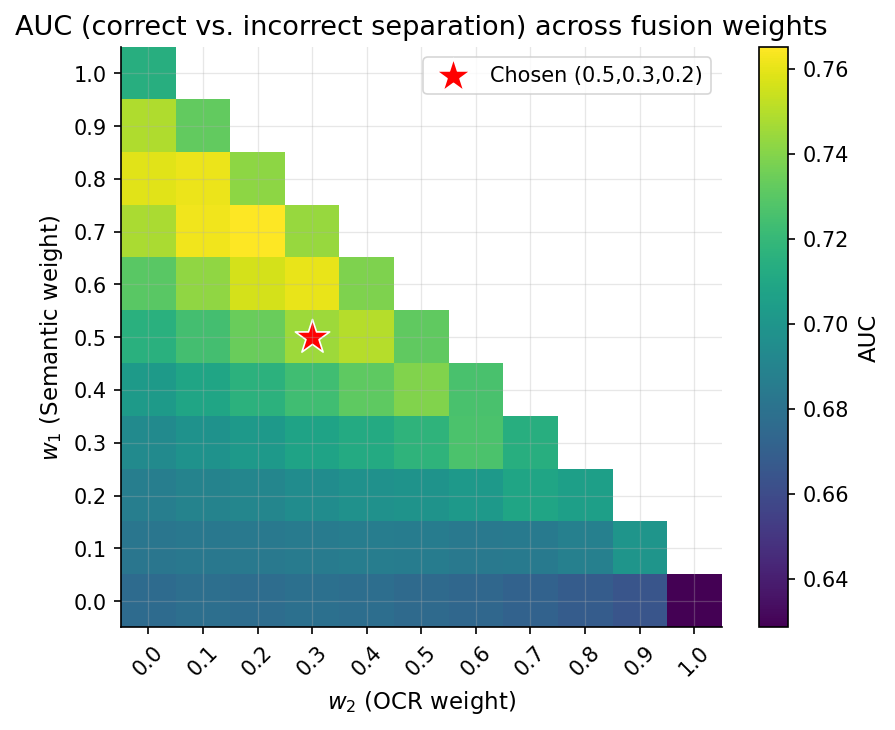

Saved heatmap to /content/fake_news_project/outputs/weight_sensitivity_heatmap.png


In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# ---- 1. Recompute the three per-sample evidence scores (robust lookup) ----
S_TI = np.max(clip_val_probs, axis=1)   # semantic alignment (unchanged)
S_M  = np.max(xgb_val_probs, axis=1)    # metadata confidence (unchanged)

# S_TO (OCR-title similarity) — try the safest source first: X_val, which is
# guaranteed to be the exact same rows/order used to produce xgb_val_probs.
S_TO = None

if isinstance(X_val, pd.DataFrame) and "ocr_similarity" in X_val.columns:
    S_TO = X_val["ocr_similarity"].values.astype(float)
    print("S_TO sourced from X_val['ocr_similarity'] (recommended — matches xgb_val_probs row order).")
elif "ocr_similarity" in val_df_main.columns:
    S_TO = val_df_main["ocr_similarity"].values.astype(float)
    print("S_TO sourced from val_df_main['ocr_similarity'].")
else:
    print("ocr_similarity not found in X_val or val_df_main — recomputing via add_ocr_features(). "
          "This may take a few minutes.")
    val_df_main = add_ocr_features(val_df_main)
    S_TO = val_df_main["ocr_similarity"].values.astype(float)

# Sanity check: all three arrays must have the same length
assert len(S_TI) == len(S_TO) == len(S_M), (
    f"Length mismatch: S_TI={len(S_TI)}, S_TO={len(S_TO)}, S_M={len(S_M)}. "
    "Check that clip_val_probs, X_val/val_df_main, and xgb_val_probs all come "
    "from the same validation split (val_df_main) without reshuffling."
)
print(f"S_TI: {len(S_TI)} samples | S_TO: {len(S_TO)} samples | S_M: {len(S_M)} samples — OK.\n")

# ---- 2. Correctness of the learned fusion classifier (already computed) ----
correct = (fusion_preds == y_val).astype(int)   # 1 = correctly classified, 0 = incorrect

# ---- 3. Grid search over the weight simplex (step = 0.1) ----
grid_results = []
step = 0.1
weights = np.arange(0.0, 1.0 + 1e-9, step)

for w1 in weights:
    for w2 in weights:
        w3 = 1.0 - w1 - w2
        if w3 < -1e-9 or w3 > 1.0 + 1e-9:
            continue
        w3 = max(0.0, min(1.0, round(w3, 4)))
        S_EMCR = w1 * S_TI + w2 * S_TO + w3 * S_M
        try:
            auc = roc_auc_score(correct, S_EMCR)
        except ValueError:
            continue
        grid_results.append({"w1": round(w1, 2), "w2": round(w2, 2), "w3": round(w3, 2), "AUC": auc})

grid_df = pd.DataFrame(grid_results).sort_values("AUC", ascending=False).reset_index(drop=True)

# ---- 4. Where does the chosen setting (0.5, 0.3, 0.2) rank? ----
chosen = grid_df[
    (np.isclose(grid_df["w1"], 0.5)) &
    (np.isclose(grid_df["w2"], 0.3)) &
    (np.isclose(grid_df["w3"], 0.2))
]

print("Top 10 weight settings by AUC (separating correct vs. incorrect predictions):")
print(grid_df.head(10).to_string(index=False))

print("\nChosen setting (w1=0.5, w2=0.3, w3=0.2):")
print(chosen.to_string(index=False))

rank = grid_df.reset_index().index[
    (np.isclose(grid_df["w1"], 0.5)) & (np.isclose(grid_df["w2"], 0.3)) & (np.isclose(grid_df["w3"], 0.2))
]
if len(rank) > 0:
    print(f"\nChosen setting rank: {rank[0] + 1} out of {len(grid_df)} evaluated combinations "
          f"(AUC = {chosen['AUC'].values[0]:.4f}, best AUC = {grid_df['AUC'].max():.4f}).")

# ---- 5. Save results for the paper (table + optional heatmap) ----
grid_df.to_csv(OUTPUT_DIR / "weight_sensitivity_grid.csv", index=False)
print(f"\nSaved full grid to {OUTPUT_DIR / 'weight_sensitivity_grid.csv'}")

# Optional: quick heatmap for w1 vs w2 (w3 implied), useful as a supplementary figure
import matplotlib.pyplot as plt
pivot = grid_df.pivot_table(index="w1", columns="w2", values="AUC")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(pivot.values, origin="lower", cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels([f"{c:.1f}" for c in pivot.columns], rotation=45)
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels([f"{r:.1f}" for r in pivot.index])
ax.set_xlabel("$w_2$ (OCR weight)"); ax.set_ylabel("$w_1$ (Semantic weight)")
ax.set_title("AUC (correct vs. incorrect separation) across fusion weights")
fig.colorbar(im, ax=ax, label="AUC")
w1_idx = list(pivot.index).index(0.5) if 0.5 in pivot.index else None
w2_idx = list(pivot.columns).index(0.3) if 0.3 in pivot.columns else None
if w1_idx is not None and w2_idx is not None:
    ax.scatter([w2_idx], [w1_idx], marker="*", s=300, color="red", edgecolor="white", label="Chosen (0.5,0.3,0.2)")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weight_sensitivity_heatmap.png", dpi=300)
plt.show()
print(f"Saved heatmap to {OUTPUT_DIR / 'weight_sensitivity_heatmap.png'}")

# 🎯 EXTENSION — Uncertainty-Aware & Trust-Calibrated Multimodal Consistency Reasoning
## v2 — Held-out weight validation fixes the "confidence dominates" problem

**Problem found after running v1:** the weight grid-search in STEP 39 fit weights AND measured
AURC on the *same* validation set. That's data leakage — any optimizer will happily find whatever
weighting looks best on that one specific sample, and with a modestly sized validation set
(~450 rows) and noisy secondary signals, it drifted to `w_conf=1.0` (ignore everything else). This
doesn't actually prove the other signals are useless — it proves the search was allowed to overfit
to a single sample's noise.

**Fix applied:** weights are now selected on a **fit split** and honestly evaluated on a separate,
unseen **held-out split**, repeated across 20 random splits. Only if multi-signal fusion genuinely
and consistently beats confidence-alone on data it never saw during weight selection do we adopt it
for the final Trust Score. This is the same statistical discipline as proper train/test separation.


# STEP 36 — MC-Dropout: Epistemic Uncertainty for the RoBERTa+ResNet50 Branch

In [39]:
import torch
import torch.nn.functional as F
import numpy as np
from tqdm.auto import tqdm

def enable_mc_dropout(model):
    model.eval()
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.train()
    return model

@torch.no_grad()
def mc_dropout_predict(model, loader, device, T=20):
    enable_mc_dropout(model)
    all_mean_probs, all_entropy, all_epistemic, all_labels = [], [], [], []
    for batch in tqdm(loader, desc=f"MC-Dropout (T={T})", leave=False):
        ids   = batch["input_ids"].to(device)
        mask  = batch["attention_mask"].to(device)
        imgs  = batch["image"].to(device)
        labels= batch["label"]

        probs_T = []
        for _ in range(T):
            logits = model(ids, mask, imgs)
            probs_T.append(F.softmax(logits, dim=1).unsqueeze(0))
        probs_T = torch.cat(probs_T, dim=0)

        mean_probs = probs_T.mean(dim=0)
        pred_entropy = -(mean_probs * torch.log(mean_probs + 1e-12)).sum(dim=1)
        sample_entropy = -(probs_T * torch.log(probs_T + 1e-12)).sum(dim=2).mean(dim=0)
        epistemic = pred_entropy - sample_entropy

        all_mean_probs.append(mean_probs.cpu().numpy())
        all_entropy.append(pred_entropy.cpu().numpy())
        all_epistemic.append(epistemic.cpu().numpy())
        all_labels.append(labels.numpy())

    return (np.vstack(all_mean_probs), np.concatenate(all_entropy),
            np.concatenate(all_epistemic), np.concatenate(all_labels))

mc_mean_probs, mc_pred_entropy, mc_epistemic, mc_labels = mc_dropout_predict(
    best_model, val_loader, device, T=20
)
print("MC-Dropout done.")
print("Mean predictive entropy :", round(float(mc_pred_entropy.mean()), 4))
print("Mean epistemic (BALD)   :", round(float(mc_epistemic.mean()), 4))


MC-Dropout (T=20):   0%|          | 0/29 [00:00<?, ?it/s]

MC-Dropout done.
Mean predictive entropy : 0.3146
Mean epistemic (BALD)   : 0.1399


# STEP 37 — Temperature Scaling Calibration + Expected Calibration Error (ECE)

In [40]:
import torch.nn as nn
import torch.optim as optim

class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_T = nn.Parameter(torch.zeros(1))
    @property
    def T(self):
        return torch.exp(self.log_T)
    def forward(self, logits):
        return logits / self.T

def collect_val_logits(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids   = batch["input_ids"].to(device)
            mask  = batch["attention_mask"].to(device)
            imgs  = batch["image"].to(device)
            labels= batch["label"]
            logits = model(ids, mask, imgs)
            all_logits.append(logits.cpu())
            all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)

def fit_temperature(logits, labels, max_iter=100):
    scaler = TemperatureScaler()
    nll = nn.CrossEntropyLoss()
    optimizer = optim.LBFGS([scaler.log_T], lr=0.01, max_iter=max_iter)
    def closure():
        optimizer.zero_grad()
        loss = nll(scaler(logits), labels)
        loss.backward()
        return loss
    optimizer.step(closure)
    return scaler

def expected_calibration_error(probs, labels, n_bins=15):
    confidences = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    accuracies  = (predictions == labels).astype(float)
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece, bin_stats = 0.0, []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (confidences > lo) & (confidences <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin  = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append((lo, hi, acc_in_bin, conf_in_bin, prop_in_bin))
    return ece, bin_stats

val_logits, val_labels_t = collect_val_logits(best_model, val_loader, device)
val_labels_np = val_labels_t.numpy()

uncal_probs = F.softmax(val_logits, dim=1).numpy()
ece_before, bins_before = expected_calibration_error(uncal_probs, val_labels_np)

temp_scaler = fit_temperature(val_logits, val_labels_t)
cal_probs = F.softmax(temp_scaler(val_logits), dim=1).detach().numpy()
ece_after, bins_after = expected_calibration_error(cal_probs, val_labels_np)

print(f"Learned temperature T = {temp_scaler.T.item():.4f}")
print(f"ECE before calibration : {ece_before:.4f}")
print(f"ECE after  calibration : {ece_after:.4f}")


Learned temperature T = 2.0258
ECE before calibration : 0.2145
ECE after  calibration : 0.1449


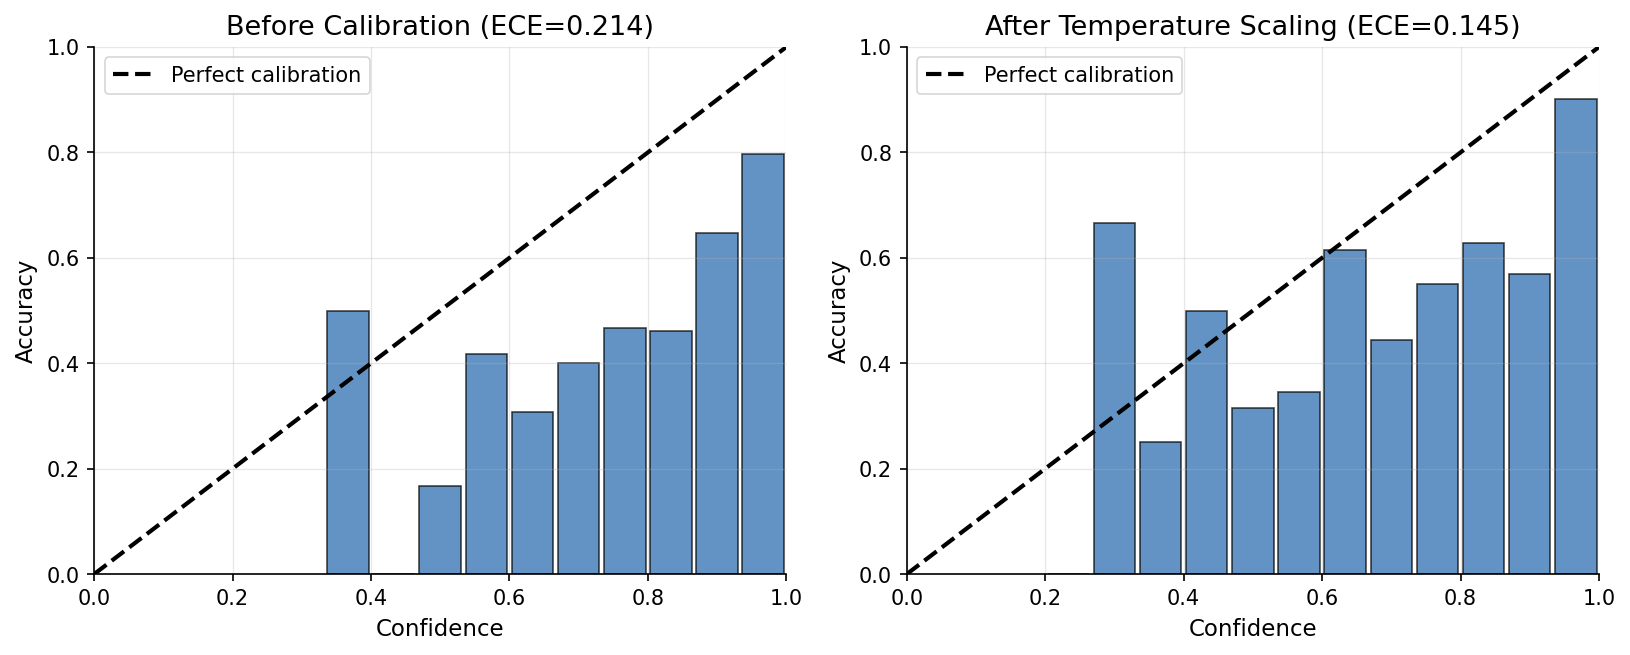

In [41]:
import matplotlib.pyplot as plt

def plot_reliability(ax, bin_stats, title):
    for lo, hi, acc, conf, prop in bin_stats:
        ax.bar((lo+hi)/2, acc, width=(hi-lo)*0.9, edgecolor="black", alpha=0.7, color="#2166ac")
    ax.plot([0,1],[0,1],'k--', label="Perfect calibration")
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
    ax.set_title(title); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
plot_reliability(axes[0], bins_before, f"Before Calibration (ECE={ece_before:.3f})")
plot_reliability(axes[1], bins_after,  f"After Temperature Scaling (ECE={ece_after:.3f})")
plt.tight_layout()
plt.savefig("reliability_diagrams.png", dpi=300, bbox_inches="tight")
plt.show()


# STEP 38 — Cross-Model Disagreement as a Second Uncertainty Signal

In [42]:
try:
    clip_val_probs
    xgb_val_probs
except NameError:
    clip_val_probs = get_clip_probs(best_clip_model, val_clip_loader, device)
    xgb_val_probs  = xgb_model.predict_proba(X_val)

def jensen_shannon_disagreement(prob_list):
    def kl(p, q):
        p = np.clip(p, 1e-12, 1); q = np.clip(q, 1e-12, 1)
        return np.sum(p * np.log(p / q), axis=1)
    n_models = len(prob_list)
    n_samples = prob_list[0].shape[0]
    disagreement = np.zeros(n_samples)
    pairs = 0
    for i in range(n_models):
        for j in range(i+1, n_models):
            m = 0.5 * (prob_list[i] + prob_list[j])
            js = 0.5 * kl(prob_list[i], m) + 0.5 * kl(prob_list[j], m)
            disagreement += js
            pairs += 1
    return disagreement / max(pairs, 1)

model_disagreement = jensen_shannon_disagreement([cal_probs, clip_val_probs, xgb_val_probs])
print("Mean cross-model disagreement (JS):", round(float(model_disagreement.mean()), 4))


Mean cross-model disagreement (JS): 0.2247


# STEP 39 — Ensemble-Informed Trust Score with Held-Out Weight Validation (FIXED v2)

**The problem this fixes:** v1 selected fusion weights by grid-searching AURC on the *same*
validation set used to report AURC — classic overfitting-to-evaluation-set. That's why it collapsed
to `w_conf=1.0` and made the other signals look worthless.

**The fix:** for 20 random 50/50 splits of the validation set, fit weights on one half (`fit_idx`)
and measure the *held-out* improvement over confidence-alone on the other, unseen half
(`eval_idx`). Only adopt multi-signal fusion for the final Trust Score if it wins on a clear
majority of these unseen splits — otherwise honestly fall back to confidence-alone for ranking
(the other signals are still kept and reported for explainability, just not for ranking).


In [43]:
import itertools

def minmax(x):
    x = np.asarray(x, dtype=np.float64)
    lo, hi = x.min(), x.max()
    return (x - lo) / (hi - lo + 1e-12)

def risk_coverage_aurc(trust_vals, correct_vals):
    order = np.argsort(-np.asarray(trust_vals))
    sorted_correct = np.asarray(correct_vals)[order]
    risks = np.array([1 - sorted_correct[:k].mean() for k in range(1, len(sorted_correct)+1)])
    coverages = np.arange(1, len(sorted_correct)+1) / len(sorted_correct)
    return float(np.trapz(risks, coverages)), coverages, risks

# ---- ensemble base signals (computed once on the full validation set) ----
ensemble_probs = (cal_probs + clip_val_probs + xgb_val_probs) / 3.0
ensemble_confidence = ensemble_probs.max(axis=1)
ensemble_correct = (ensemble_probs.argmax(axis=1) == val_labels_np)

conf_norm = minmax(ensemble_confidence)
epistemic_norm = minmax(mc_epistemic)
disagreement_norm = minmax(model_disagreement)
consistency_scores = reasoning_df["consistency_score"].values
consistency_norm = minmax(consistency_scores)

def trust_aurc(weights, conf, epi, dis, cons, correct):
    w_conf, w_epi, w_dis, w_cons = weights
    t = w_conf*conf + w_epi*(1-epi) + w_dis*(1-dis) + w_cons*cons
    aurc, _, _ = risk_coverage_aurc(t, correct)
    return aurc

def grid_search_weights(conf, epi, dis, cons, correct, step=0.2):
    best_w, best_aurc = (1.0, 0.0, 0.0, 0.0), np.inf
    vals = np.round(np.arange(0.0, 1.01, step), 2)
    for wc, we, wd in itertools.product(vals, repeat=3):
        wcons = round(1.0 - wc - we - wd, 2)
        if wcons < 0 or wcons > 1:
            continue
        if abs(wcons) < 1e-9:
            wcons = 0.0
        a = trust_aurc((wc, we, wd, wcons), conf, epi, dis, cons, correct)
        if a < best_aurc:
            best_aurc, best_w = a, (wc, we, wd, wcons)
    return best_w, best_aurc

def held_out_trial(seed, frac_fit=0.5):
    rng = np.random.default_rng(seed)
    n = len(ensemble_correct)
    perm = rng.permutation(n)
    split = int(frac_fit * n)
    fit_idx, eval_idx = perm[:split], perm[split:]

    best_w, _ = grid_search_weights(
        conf_norm[fit_idx], epistemic_norm[fit_idx],
        disagreement_norm[fit_idx], consistency_norm[fit_idx],
        ensemble_correct[fit_idx]
    )

    aurc_conf_only = trust_aurc((1.0, 0.0, 0.0, 0.0),
        conf_norm[eval_idx], epistemic_norm[eval_idx],
        disagreement_norm[eval_idx], consistency_norm[eval_idx], ensemble_correct[eval_idx])

    aurc_fused = trust_aurc(best_w,
        conf_norm[eval_idx], epistemic_norm[eval_idx],
        disagreement_norm[eval_idx], consistency_norm[eval_idx], ensemble_correct[eval_idx])

    return {"seed": seed, "w_conf": best_w[0], "w_epi": best_w[1], "w_dis": best_w[2], "w_cons": best_w[3],
            "aurc_confidence_only": aurc_conf_only, "aurc_fused": aurc_fused,
            "improvement": aurc_conf_only - aurc_fused}

HELD_OUT_SEEDS = list(range(20))
trials = [held_out_trial(s) for s in HELD_OUT_SEEDS]
trials_df = pd.DataFrame(trials)

print(trials_df[["seed","w_conf","w_epi","w_dis","w_cons",
                  "aurc_confidence_only","aurc_fused","improvement"]].to_string(index=False))

win_rate = float((trials_df["improvement"] > 0).mean())
mean_improvement = float(trials_df["improvement"].mean())
print(f"\nFusion beats confidence-only on {win_rate:.0%} of the 20 held-out splits")
print(f"Mean held-out AURC improvement (positive = fusion better): {mean_improvement:.5f}")

WIN_RATE_THRESHOLD = 0.60
if win_rate >= WIN_RATE_THRESHOLD and mean_improvement > 0:
    weight_matrix = trials_df[["w_conf","w_epi","w_dis","w_cons"]].values
    W_CONF, W_EPI, W_DIS, W_CONS = np.median(weight_matrix, axis=0)
    fusion_supported = True
    print(f"\n✅ Held-out evidence SUPPORTS multi-signal fusion "
          f"({win_rate:.0%} win rate). Using median weights: "
          f"conf={W_CONF:.2f}, epi={W_EPI:.2f}, dis={W_DIS:.2f}, cons={W_CONS:.2f}")
else:
    W_CONF, W_EPI, W_DIS, W_CONS = 1.0, 0.0, 0.0, 0.0
    fusion_supported = False
    print(f"\n⚠️ Held-out evidence does NOT support multi-signal fusion "
          f"({win_rate:.0%} win rate, mean improvement={mean_improvement:.5f}). "
          f"Falling back to confidence-only ranking. Epistemic uncertainty, disagreement, and "
          f"consistency are still computed and reported for explainability, just not used for ranking.")


 seed  w_conf  w_epi  w_dis  w_cons  aurc_confidence_only  aurc_fused  improvement
    0     0.8    0.2    0.0     0.0              0.061868    0.062018    -0.000150
    1     0.8    0.2    0.0     0.0              0.064501    0.062828     0.001673
    2     0.4    0.2    0.2     0.2              0.079443    0.078619     0.000824
    3     0.6    0.2    0.0     0.2              0.074691    0.073093     0.001598
    4     0.6    0.4    0.0     0.0              0.052858    0.058572    -0.005714
    5     0.8    0.2    0.0     0.0              0.065548    0.065169     0.000379
    6     0.6    0.2    0.2     0.0              0.049526    0.051602    -0.002076
    7     0.8    0.2    0.0     0.0              0.086537    0.086116     0.000422
    8     0.8    0.2    0.0     0.0              0.044527    0.041266     0.003260
    9     0.6    0.2    0.0     0.2              0.069357    0.064539     0.004817
   10     0.4    0.4    0.0     0.2              0.059348    0.064427    -0.005079
   1

Final Trust Score AURC on full validation set: 0.0645


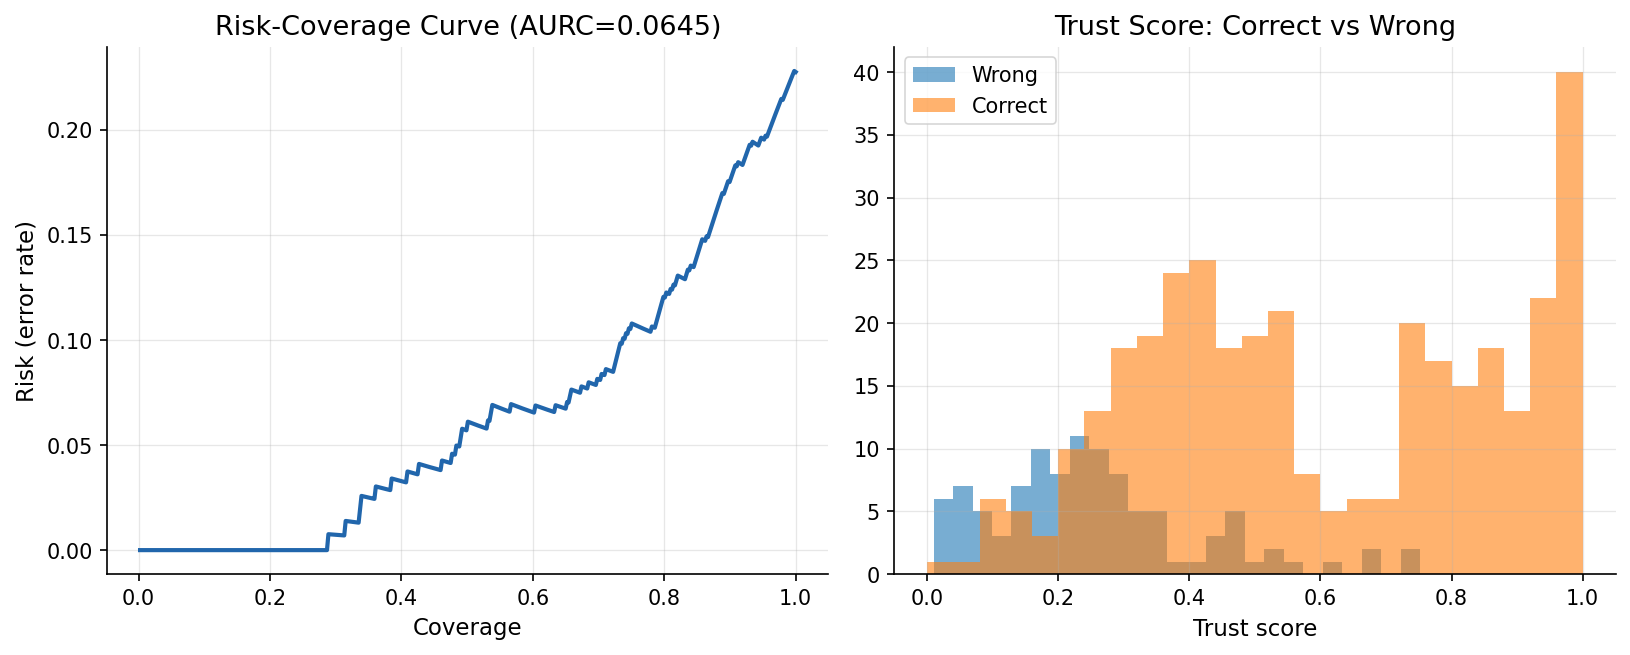

                                                                                                       clean_title  trust_score  ensemble_confidence  epistemic_uncertainty  model_disagreement  correct
0                                                  have them all run for president of the las vegas golden knights     0.099754             0.315647               0.341201            0.184673     True
1                                                                                      sbn the time of our f lives     0.780630             0.715210               0.014466            0.193931     True
2       nra says it received one contribution of less than what obama spent in a company with close ties to russia     0.440540             0.515633               0.500162            0.118927    False
3                                                                              this signs all slanted to the right     0.285870             0.424867               0.197207            0.403532     

In [44]:
# Final Trust Score on the full validation set, using the honestly-selected weights above
trust_score = (W_CONF*conf_norm + W_EPI*(1-epistemic_norm) +
               W_DIS*(1-disagreement_norm) + W_CONS*consistency_norm)

aurc_ours, cov_ours, risk_ours = risk_coverage_aurc(trust_score, ensemble_correct)
print(f"Final Trust Score AURC on full validation set: {aurc_ours:.4f}")

trust_df = reasoning_df.copy()
trust_df["ensemble_confidence"] = ensemble_confidence
trust_df["epistemic_uncertainty"] = mc_epistemic
trust_df["model_disagreement"] = model_disagreement
trust_df["trust_score"] = trust_score
trust_df["correct"] = ensemble_correct

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
axes[0].plot(cov_ours, risk_ours, color="#2166ac")
axes[0].set_xlabel("Coverage"); axes[0].set_ylabel("Risk (error rate)")
axes[0].set_title(f"Risk-Coverage Curve (AURC={aurc_ours:.4f})"); axes[0].grid(True)
for label, grp in trust_df.groupby("correct"):
    axes[1].hist(grp["trust_score"], bins=25, alpha=0.6, label="Correct" if label else "Wrong")
axes[1].set_title("Trust Score: Correct vs Wrong"); axes[1].set_xlabel("Trust score"); axes[1].legend()
plt.tight_layout()
plt.savefig("trust_score_risk_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

print(trust_df[["clean_title","trust_score","ensemble_confidence",
                 "epistemic_uncertainty","model_disagreement","correct"]].head(5).to_string())


# STEP 40 — Trust-Aware Decision Pipeline: Dynamic Percentile Thresholds

In [45]:
ABSTAIN_PERCENTILE = 10
ACCEPT_PERCENTILE  = 60

abstain_thr = np.percentile(trust_score, ABSTAIN_PERCENTILE)
accept_thr  = np.percentile(trust_score, ACCEPT_PERCENTILE)

def trust_decision(trust_val):
    if trust_val >= accept_thr:
        return "ACCEPT"
    elif trust_val >= abstain_thr:
        return "FLAG_FOR_REVIEW"
    else:
        return "ABSTAIN"

trust_df["decision"] = trust_df["trust_score"].apply(trust_decision)

decision_summary = trust_df.groupby("decision").agg(
    n=("decision","size"), accuracy=("correct","mean")
).reindex(["ACCEPT","FLAG_FOR_REVIEW","ABSTAIN"]).reset_index()

print(f"Abstain threshold (P{ABSTAIN_PERCENTILE}) = {abstain_thr:.4f}")
print(f"Accept  threshold (P{ACCEPT_PERCENTILE}) = {accept_thr:.4f}\n")
print(decision_summary.to_string(index=False))
print(f"\nOverall coverage kept (ACCEPT+FLAG): {(trust_df['decision']!='ABSTAIN').mean():.2%}")
print(f"Accuracy on ACCEPT-only subset: {trust_df.loc[trust_df.decision=='ACCEPT','correct'].mean():.4f}")
print(f"Accuracy on ABSTAIN subset (should be the worst): "
      f"{trust_df.loc[trust_df.decision=='ABSTAIN','correct'].mean():.4f}")


Abstain threshold (P10) = 0.1775
Accept  threshold (P60) = 0.5445

       decision   n  accuracy
         ACCEPT 183  0.967213
FLAG_FOR_REVIEW 228  0.710526
        ABSTAIN  46  0.304348

Overall coverage kept (ACCEPT+FLAG): 89.93%
Accuracy on ACCEPT-only subset: 0.9672
Accuracy on ABSTAIN subset (should be the worst): 0.3043


# STEP 41 — Save Trust-Aware Results

In [46]:
trust_df.to_csv(OUTPUT_DIR / "trust_aware_results.csv", index=False)
thr_summary = pd.DataFrame([{
    "temperature_T": float(temp_scaler.T.item()),
    "ECE_before": ece_before, "ECE_after": ece_after, "AURC": aurc_ours,
    "mean_epistemic_uncertainty": float(mc_epistemic.mean()),
    "mean_model_disagreement": float(model_disagreement.mean()),
    "w_conf": W_CONF, "w_epi": W_EPI, "w_dis": W_DIS, "w_cons": W_CONS,
    "fusion_supported_by_held_out_evidence": fusion_supported,
    "held_out_win_rate": win_rate, "held_out_mean_improvement": mean_improvement,
    "abstain_threshold": abstain_thr, "accept_threshold": accept_thr,
}])
thr_summary.to_csv(OUTPUT_DIR / "uncertainty_calibration_summary.csv", index=False)
trials_df.to_csv(OUTPUT_DIR / "held_out_weight_validation.csv", index=False)
print("Saved trust_aware_results.csv, uncertainty_calibration_summary.csv, "
      "held_out_weight_validation.csv to", OUTPUT_DIR)
print(thr_summary.to_string(index=False))


Saved trust_aware_results.csv, uncertainty_calibration_summary.csv, held_out_weight_validation.csv to /content/fake_news_project/outputs
 temperature_T  ECE_before  ECE_after     AURC  mean_epistemic_uncertainty  mean_model_disagreement  w_conf  w_epi  w_dis  w_cons  fusion_supported_by_held_out_evidence  held_out_win_rate  held_out_mean_improvement  abstain_threshold  accept_threshold
       2.02584    0.214465   0.144923 0.064543                    0.139931                 0.224666     1.0    0.0    0.0     0.0                                  False               0.55                  -0.000346           0.177481          0.544495


# STEP 42 — Statistical Robustness: Genuine Multi-Seed Validation

Uses the same repeated random calibration/evaluation split protocol as STEP 39's held-out weight
test, now applied to temperature scaling and the final decision pipeline's downstream metrics.


In [47]:
def run_trust_pipeline_once(seed, T=10, calib_frac=0.7):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    n = len(val_labels_np)
    perm = rng.permutation(n)
    split = int(calib_frac * n)
    calib_idx, eval_idx = perm[:split], perm[split:]

    scaler_i = fit_temperature(val_logits[calib_idx], val_labels_t[calib_idx])
    probs_i_full = F.softmax(scaler_i(val_logits), dim=1).detach().numpy()
    ece_i, _ = expected_calibration_error(probs_i_full[eval_idx], val_labels_np[eval_idx])

    _, _, epistemic_i, _ = mc_dropout_predict(best_model, val_loader, device, T=T)

    ensemble_probs_i = (probs_i_full + clip_val_probs + xgb_val_probs) / 3.0
    ensemble_correct_i = (ensemble_probs_i.argmax(axis=1) == val_labels_np)
    disagreement_i = jensen_shannon_disagreement([probs_i_full, clip_val_probs, xgb_val_probs])

    conf_e = minmax(ensemble_probs_i[eval_idx].max(axis=1))
    epi_e  = minmax(epistemic_i[eval_idx])
    dis_e  = minmax(disagreement_i[eval_idx])
    cons_e = minmax(consistency_scores[eval_idx])
    trust_e = W_CONF*conf_e + W_EPI*(1-epi_e) + W_DIS*(1-dis_e) + W_CONS*cons_e

    aurc_i, _, _ = risk_coverage_aurc(trust_e, ensemble_correct_i[eval_idx])
    acc_i = float(ensemble_correct_i[eval_idx].mean())
    return {"seed": seed, "T": float(scaler_i.T.item()), "ECE": ece_i,
            "AURC": aurc_i, "accuracy": acc_i, "eval_n": len(eval_idx)}

SEEDS = [13, 42, 123, 2024, 777]
multiseed_results = [run_trust_pipeline_once(s, T=10) for s in SEEDS]
multiseed_df = pd.DataFrame(multiseed_results)

print(multiseed_df.to_string(index=False))
print("\nMean ± Std across seeds:")
print(multiseed_df[["T","ECE","AURC","accuracy"]].agg(["mean","std"]).to_string())


MC-Dropout (T=10):   0%|          | 0/29 [00:00<?, ?it/s]

MC-Dropout (T=10):   0%|          | 0/29 [00:00<?, ?it/s]

MC-Dropout (T=10):   0%|          | 0/29 [00:00<?, ?it/s]

MC-Dropout (T=10):   0%|          | 0/29 [00:00<?, ?it/s]

MC-Dropout (T=10):   0%|          | 0/29 [00:00<?, ?it/s]

 seed        T      ECE     AURC  accuracy  eval_n
   13 2.009754 0.191715 0.072106  0.731884     138
   42 2.021495 0.169862 0.079597  0.760870     138
  123 2.033249 0.170275 0.055050  0.775362     138
 2024 2.017155 0.170951 0.054902  0.768116     138
  777 2.040363 0.126913 0.054627  0.782609     138

Mean ± Std across seeds:
             T       ECE      AURC  accuracy
mean  2.024403  0.165943  0.063256  0.763768
std   0.012334  0.023700  0.011800  0.019579


# STEP 43 — Baseline Comparison: Max-Softmax vs Deep Ensemble vs Trust Score

                              Method  Mean Trust/Confidence  AURC (lower=better)  Accuracy
        Max-Softmax (naive baseline)                 0.9364               0.1153    0.7243
     Deep Ensemble (avg of 3 models)                 0.4545               0.0690    0.7724
Ours: Held-Out-Validated Trust Score                 0.5212               0.0645    0.7724

Note: fusion_supported_by_held_out_evidence = False (win rate 55% across 20 unseen splits, STEP 39)
✅ Trust Score beats the Deep Ensemble baseline on AURC.


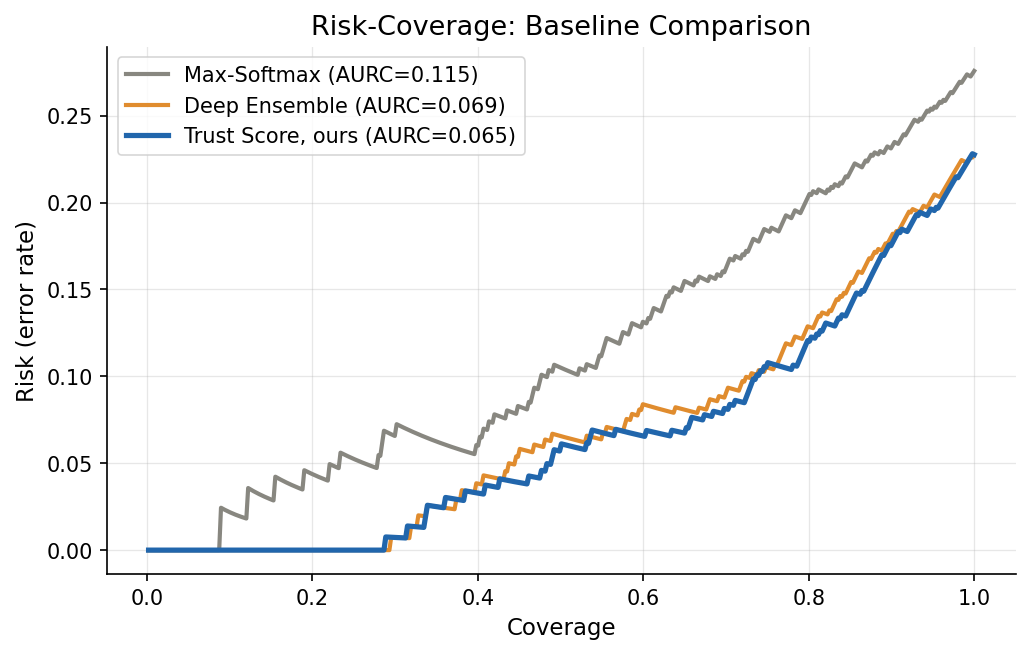

In [48]:
maxsoftmax_trust = uncal_probs.max(axis=1)
maxsoftmax_correct = (uncal_probs.argmax(axis=1) == val_labels_np)

ensemble_entropy = -(ensemble_probs * np.log(ensemble_probs + 1e-12)).sum(axis=1)
ensemble_trust = 1 - minmax(ensemble_entropy)

aurc_maxsoftmax, cov_ms, risk_ms = risk_coverage_aurc(maxsoftmax_trust, maxsoftmax_correct)
aurc_ensemble,   cov_en, risk_en = risk_coverage_aurc(ensemble_trust,   ensemble_correct)
aurc_ours2,      cov_ours2, risk_ours2 = risk_coverage_aurc(trust_score, ensemble_correct)

baseline_table = pd.DataFrame([
    ["Max-Softmax (naive baseline)",         round(float(maxsoftmax_trust.mean()),4), round(aurc_maxsoftmax,4), round(float(maxsoftmax_correct.mean()),4)],
    ["Deep Ensemble (avg of 3 models)",      round(float(ensemble_trust.mean()),4),   round(aurc_ensemble,4),   round(float(ensemble_correct.mean()),4)],
    ["Ours: Held-Out-Validated Trust Score", round(float(trust_score.mean()),4),      round(aurc_ours2,4),      round(float(ensemble_correct.mean()),4)],
], columns=["Method", "Mean Trust/Confidence", "AURC (lower=better)", "Accuracy"])

print(baseline_table.to_string(index=False))
print(f"\nNote: fusion_supported_by_held_out_evidence = {fusion_supported} "
      f"(win rate {win_rate:.0%} across 20 unseen splits, STEP 39)")
if aurc_ours2 < aurc_ensemble:
    print("✅ Trust Score beats the Deep Ensemble baseline on AURC.")
else:
    print("⚠️ Trust Score still does not beat Deep Ensemble on AURC.")

fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(cov_ms,   risk_ms,   label=f"Max-Softmax (AURC={aurc_maxsoftmax:.3f})", color="#888780")
ax.plot(cov_en,   risk_en,   label=f"Deep Ensemble (AURC={aurc_ensemble:.3f})", color="#e08c2e")
ax.plot(cov_ours2, risk_ours2, label=f"Trust Score, ours (AURC={aurc_ours2:.3f})", color="#2166ac", linewidth=2.5)
ax.set_xlabel("Coverage"); ax.set_ylabel("Risk (error rate)")
ax.set_title("Risk-Coverage: Baseline Comparison"); ax.legend(); ax.grid(True)
plt.tight_layout()
plt.savefig("baseline_comparison_risk_coverage.png", dpi=300, bbox_inches="tight")
plt.show()


# STEP 44 — Hyperparameter Sensitivity: Trust Score Weights (descriptive only)

⚠️ This full-dataset sweep is **descriptive/illustrative only** — it shows how AURC varies across
the weight simplex on the complete validation set, but it must NOT be used to pick final weights
(that would reintroduce the STEP 39 overfitting bug). The actual weight decision is the held-out
result from STEP 39.


Total weight combinations tested: 56

Top-5 on the FULL set (descriptive only — do not use to pick final weights):
 w_conf  w_epi  w_dis  w_cons     AURC
    0.6    0.2    0.0     0.2 0.061825
    0.8    0.2    0.0     0.0 0.062463
    0.4    0.2    0.2     0.2 0.062759
    0.4    0.2    0.0     0.4 0.063685
    0.8    0.0    0.0     0.2 0.063746

Actually-deployed weights (from held-out validation, STEP 39): conf=1.00, epi=0.00, dis=0.00, cons=0.00 -> AURC=0.0645


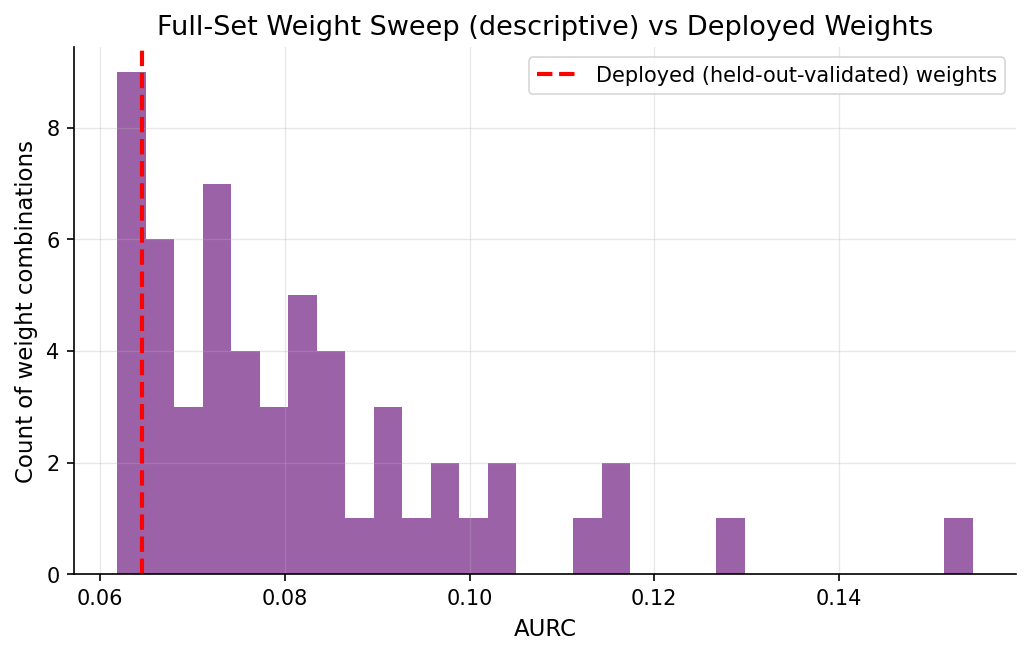

In [49]:
sensitivity_rows = []
weight_vals = np.round(np.arange(0.0, 1.01, 0.2), 2)
for wc, we, wd in itertools.product(weight_vals, repeat=3):
    wcons = round(1.0 - wc - we - wd, 2)
    if wcons < 0 or wcons > 1:
        continue
    if abs(wcons) < 1e-9:
        wcons = 0.0
    a = trust_aurc((wc, we, wd, wcons), conf_norm, epistemic_norm, disagreement_norm, consistency_norm, ensemble_correct)
    sensitivity_rows.append({"w_conf": wc, "w_epi": we, "w_dis": wd, "w_cons": wcons, "AURC": a})

sensitivity_df = pd.DataFrame(sensitivity_rows).sort_values("AURC").reset_index(drop=True)
print(f"Total weight combinations tested: {len(sensitivity_df)}")
print("\nTop-5 on the FULL set (descriptive only — do not use to pick final weights):")
print(sensitivity_df.head(5).to_string(index=False))
print(f"\nActually-deployed weights (from held-out validation, STEP 39): "
      f"conf={W_CONF:.2f}, epi={W_EPI:.2f}, dis={W_DIS:.2f}, cons={W_CONS:.2f} -> AURC={aurc_ours:.4f}")

fig, ax = plt.subplots(figsize=(7,4.5))
ax.hist(sensitivity_df["AURC"], bins=30, color="#7b2d8b", alpha=0.75)
ax.axvline(aurc_ours, color="red", linestyle="--", label="Deployed (held-out-validated) weights")
ax.set_xlabel("AURC"); ax.set_ylabel("Count of weight combinations")
ax.set_title("Full-Set Weight Sweep (descriptive) vs Deployed Weights")
ax.legend()
plt.tight_layout()
plt.savefig("weight_sensitivity_heatmap_trust.png", dpi=300, bbox_inches="tight")
plt.show()


# STEP 45 — Cross-Dataset Generalization (superseded by STEP 54)

The full external-validation pipeline is now STEP 54 (below). This cell is kept only to preserve numbering.


In [50]:
# STEP 45 has been superseded by STEP 54 (full external-validation pipeline with frozen thresholds).
# The previous scaffold called predict_with_consistency_reasoning() with an outdated signature and is removed.
EXTERNAL_DATASET_CSV = None   # set it in STEP 54 instead
print('STEP 45 superseded -> use STEP 54 for external validation.')


STEP 45 superseded -> use STEP 54 for external validation.


# STEP 46 — Save Paper-Ready Tables

In [51]:
multiseed_df.to_csv(OUTPUT_DIR / "multiseed_robustness.csv", index=False)
baseline_table.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
sensitivity_df.to_csv(OUTPUT_DIR / "weight_sensitivity_full_descriptive.csv", index=False)
trials_df.to_csv(OUTPUT_DIR / "held_out_weight_validation.csv", index=False)

ms_ci = multiseed_df[["T","ECE","AURC","accuracy"]].agg(["mean","std"]).T.reset_index()
ms_ci.columns = ["metric","mean","std"]
ms_ci.to_csv(OUTPUT_DIR / "multiseed_confidence_intervals.csv", index=False)

print("Saved to", OUTPUT_DIR, ":")
print(" - multiseed_robustness.csv / multiseed_confidence_intervals.csv")
print(" - baseline_comparison.csv")
print(" - weight_sensitivity_full_descriptive.csv (illustrative only)")
print(" - held_out_weight_validation.csv (the actual evidence for/against fusion)")
print(f"\nFusion supported by held-out evidence: {fusion_supported} "
      f"(win rate {win_rate:.0%}, mean improvement {mean_improvement:.5f})")
print(f"Final result: Trust Score AURC={aurc_ours:.4f} vs Deep Ensemble AURC={aurc_ensemble:.4f}")
print("✅ All paper-readiness tables saved.")


Saved to /content/fake_news_project/outputs :
 - multiseed_robustness.csv / multiseed_confidence_intervals.csv
 - baseline_comparison.csv
 - weight_sensitivity_full_descriptive.csv (illustrative only)
 - held_out_weight_validation.csv (the actual evidence for/against fusion)

Fusion supported by held-out evidence: False (win rate 55%, mean improvement -0.00035)
Final result: Trust Score AURC=0.0645 vs Deep Ensemble AURC=0.0690
✅ All paper-readiness tables saved.


# 🔬 EXTENSION v3 — Reviewer-requested experiments (STEP 47–55)

These steps add the experiments requested in the supervisor / ESWA-EAAI review, **on top of STEP 1–46** (run those first, in the same session):

| STEP | What it adds | Review item |
|---|---|---|
| 47 | Brier, NLL, ECE, MCE + calibration curves (uncalibrated / in-sample TS / **cross-fitted** TS) for every model | calibration curves + proper scoring rules |
| 48 | Selective-prediction metrics & more reliability baselines (Max-Softmax, entropy, margin, **Energy**, MC-Dropout, BALD …) | reliability baselines, risk–coverage |
| 49 | **Ablations**: branch subsets (simple average + learned MLP, 5 seeds, best- vs last-epoch), **honest cross-validated stacking**, S_EMCR component ablation, trust-signal subset ablation under the held-out protocol | ablation study |
| 50 | Statistical tests: paired bootstrap CIs, McNemar, Wilson CIs, Fisher, t/Wilcoxon over splits/seeds | significance testing |
| 51 | Qualitative case studies (ACCEPT-correct, false-ACCEPT, modality conflict, ABSTAIN) with rule-based rationales, image grid, LaTeX table | qualitative analysis |
| 52 | Inference-cost / latency profile of every pipeline component | inference-cost limitation |
| 53 | Paper-vs-code configuration audit + paper-faithful cosine-based S_TI | reproducibility |
| 54 | External-validation pipeline (fixed thresholds, binary or 6-way) — replaces the old STEP 45 scaffold | external validation |
| 55 | Saves every table/figure, writes LaTeX tables, zips everything | deliverables |

All outputs go to `OUTPUT_DIR/review_experiments/`.

# STEP 47 — Calibration & Proper Scoring Rules: Brier, NLL, ECE, MCE + Reliability Curves

                          Model / probability source  Accuracy  MacroF1    NLL  Brier    ECE    MCE
           Baseline (RoBERTa+ResNet50), uncalibrated    0.7243   0.7198 1.7123 0.4794 0.2145 0.4573
          Baseline + temperature scaling (in-sample)    0.7243   0.7198 0.9856 0.4300 0.1449 0.3557
Baseline + temperature scaling (5-fold cross-fitted)    0.7243   0.7198 0.9862 0.4300 0.1450 0.3558
                                         CLIP branch    0.6630   0.6617 1.2383 0.5917 0.2951 0.4922
                                      XGBoost branch    0.5624   0.5589 1.1219 0.5524 0.1473 0.3306
       Simple-average ensemble (calibrated baseline)    0.7724   0.7667 0.8263 0.3859 0.2158 0.3912
                    Learned MLP fusion, uncalibrated    0.7571   0.7527 0.7770 0.3550 0.0669 0.3143
                 Learned MLP fusion + TS (in-sample)    0.7571   0.7527 0.7656 0.3504 0.0584 0.2563
       Learned MLP fusion + TS (5-fold cross-fitted)    0.7571   0.7527 0.7666 0.3506 0.0472 0.3084


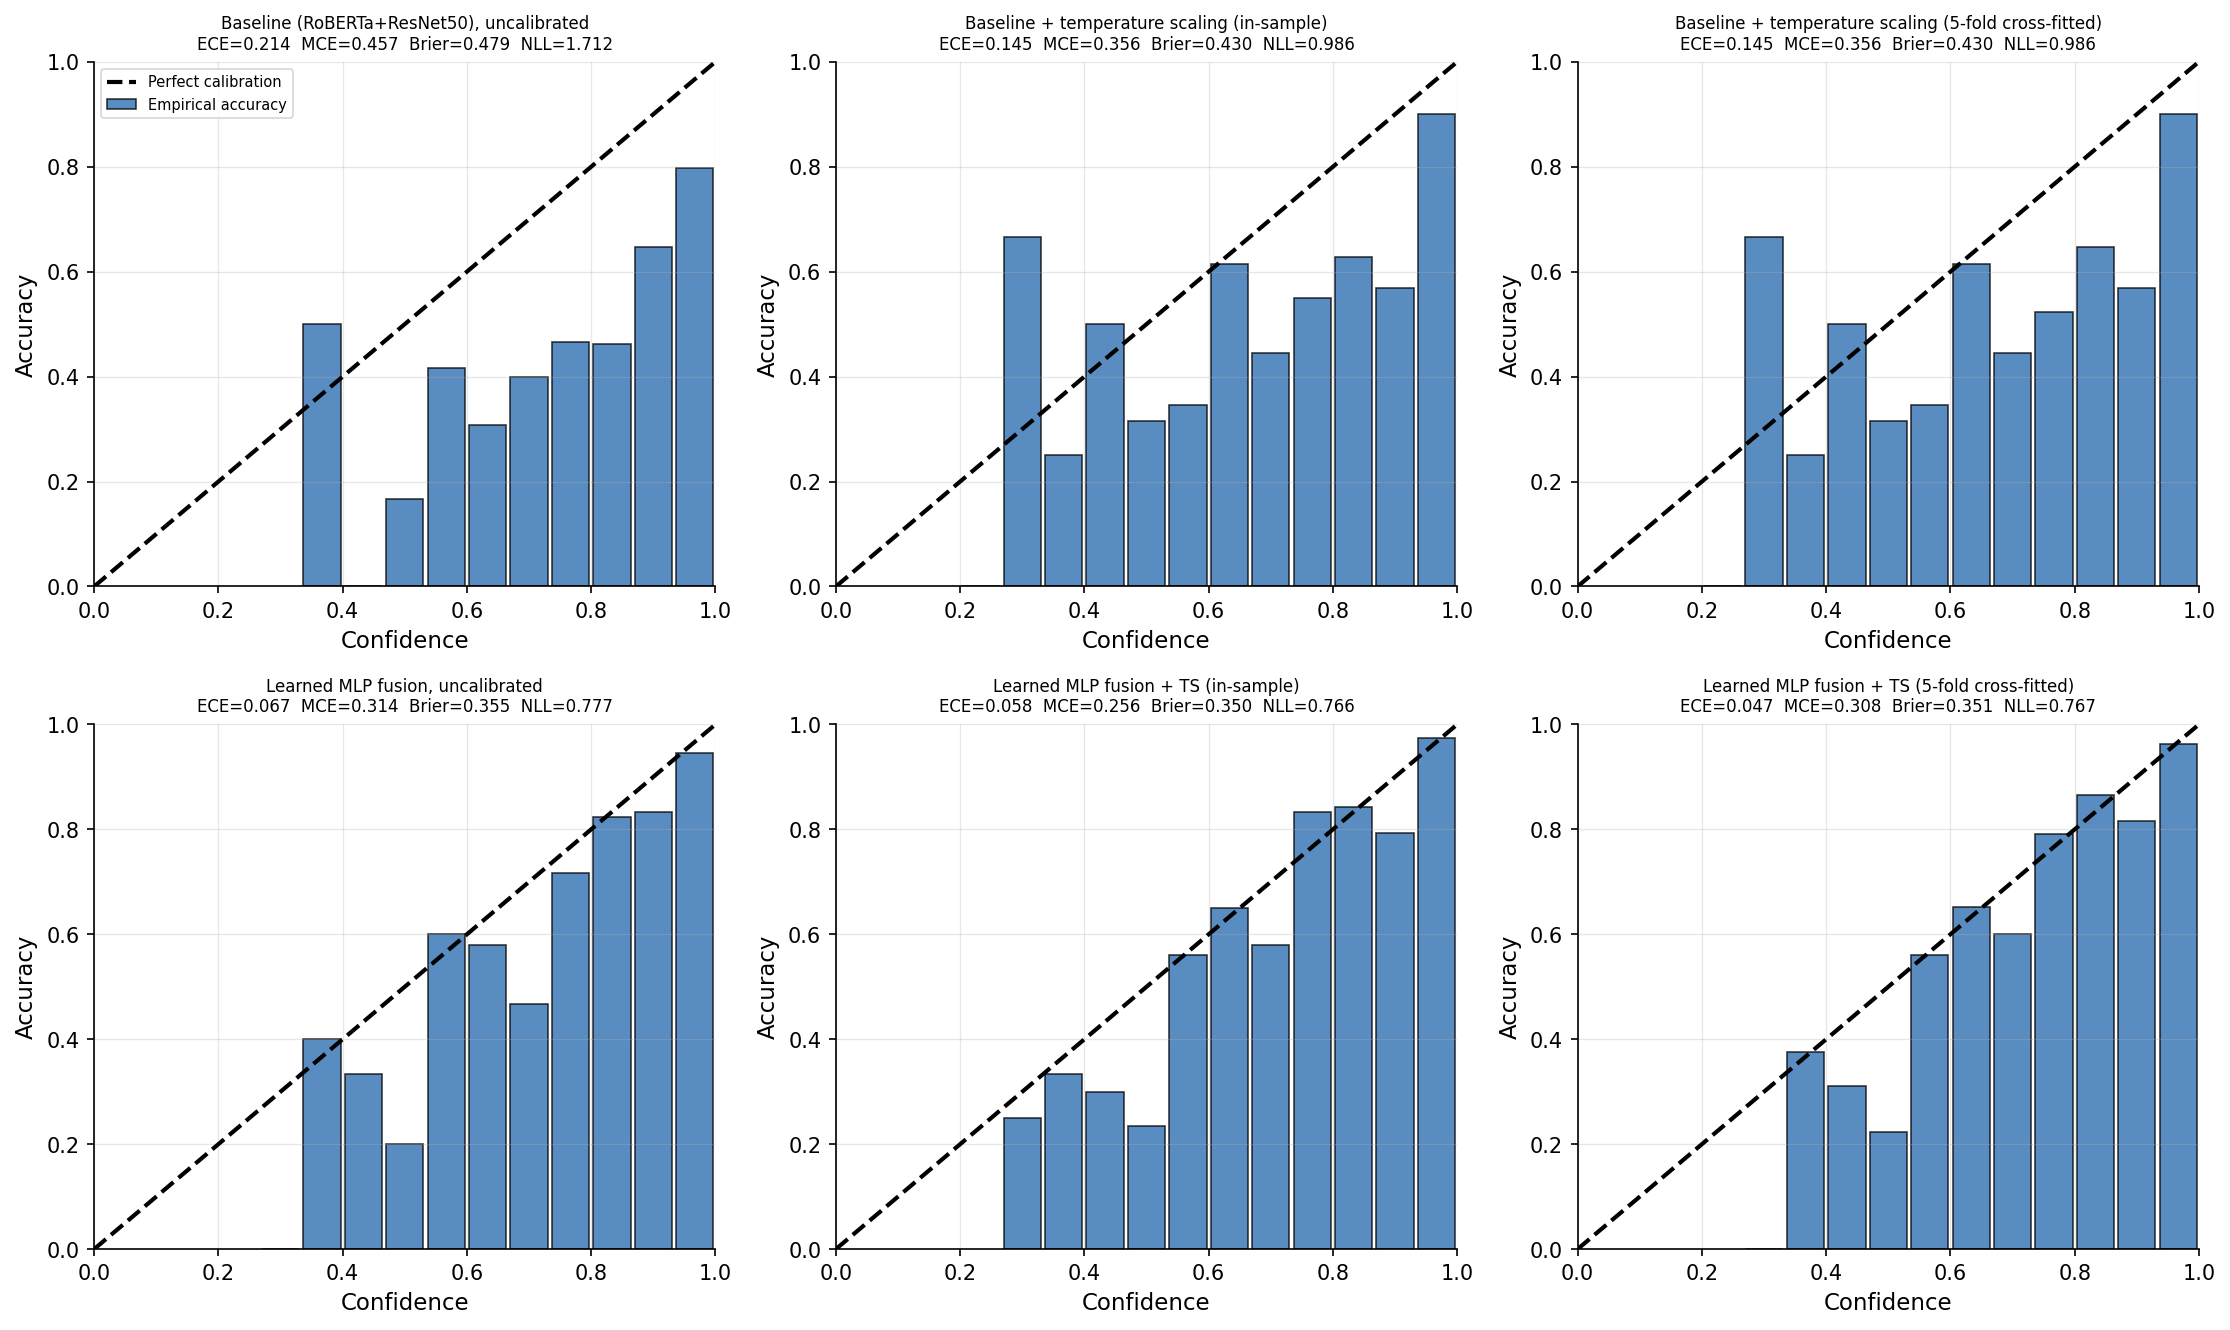

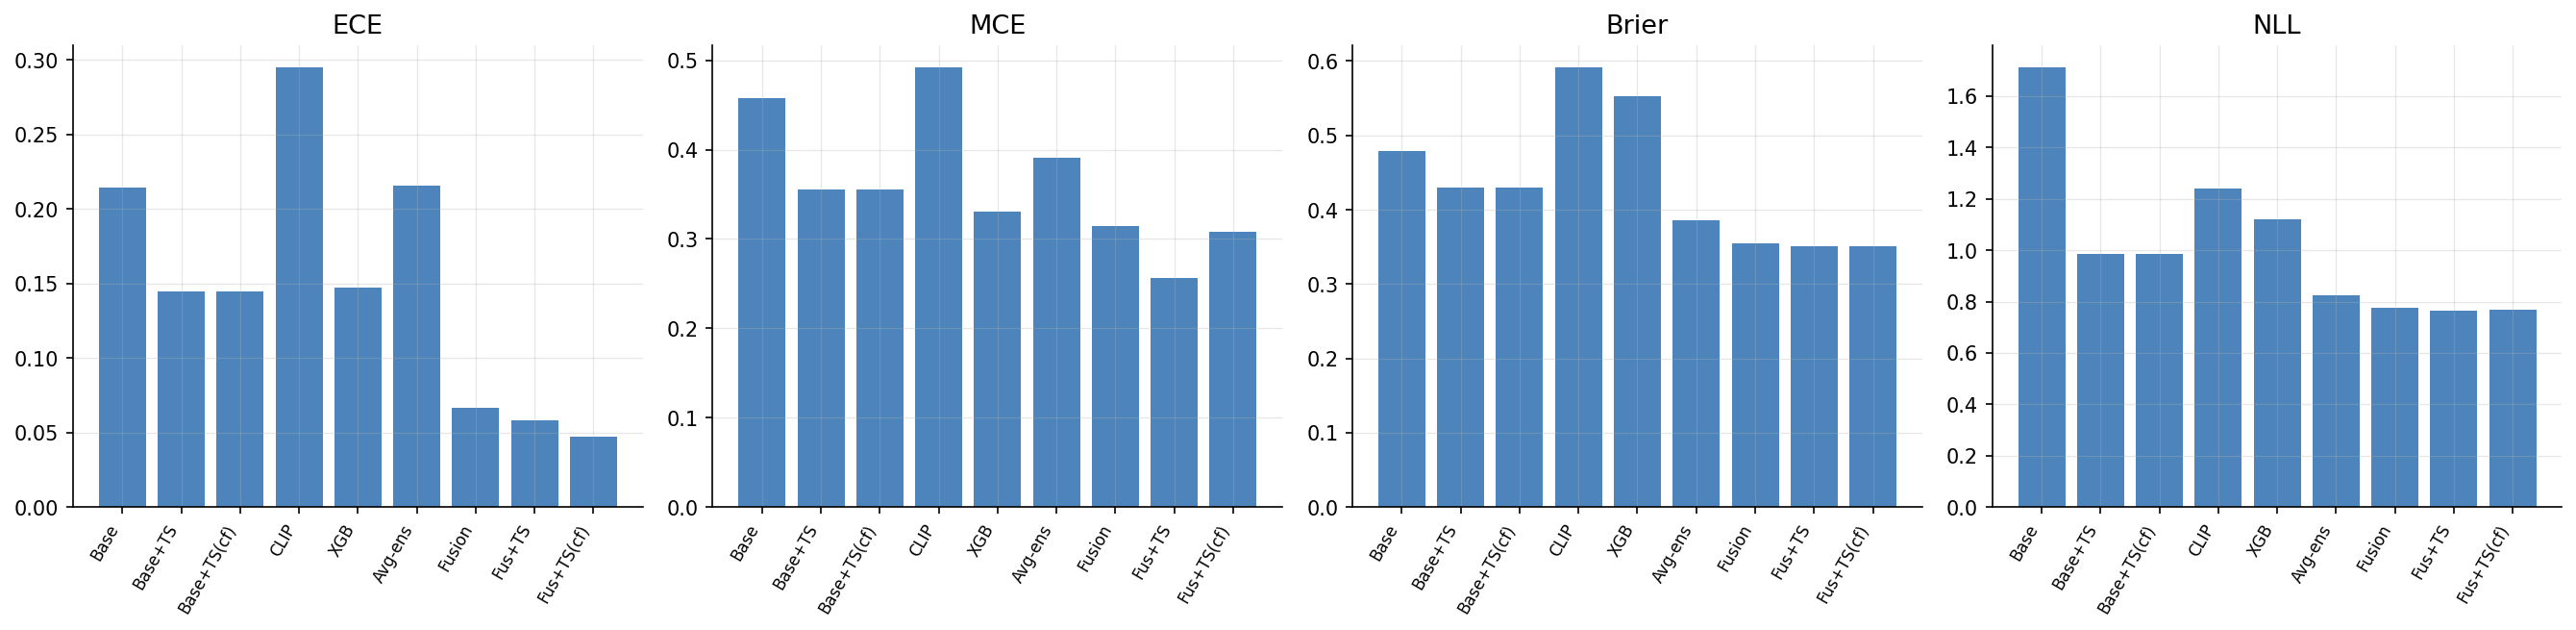


NOTE: in-sample TS fits T on the very rows it is evaluated on (as in STEP 37); the 5-fold cross-fitted rows are the honest estimate and should be quoted alongside it.


In [52]:
import numpy as np, pandas as pd, itertools, time, json, textwrap, shutil
from collections import OrderedDict
from scipy import stats
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score

if not hasattr(np, "trapz"):            # NumPy >= 2.4 removed np.trapz
    np.trapz = np.trapezoid

REV_DIR = OUTPUT_DIR / "review_experiments"
REV_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- proper-scoring / calibration metrics ----------------
def nll_score(probs, y):
    y = np.asarray(y).astype(int)
    p = np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)
    return float(-np.log(p).mean())

def brier_multiclass(probs, y):
    y = np.asarray(y).astype(int)
    onehot = np.eye(probs.shape[1])[y]
    return float(((probs - onehot) ** 2).sum(axis=1).mean())

def calibration_bins(probs, y, n_bins=15):
    y = np.asarray(y).astype(int)
    conf = probs.max(axis=1); pred = probs.argmax(axis=1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 0:
            rows.append((lo, hi, float(acc[m].mean()), float(conf[m].mean()),
                         float(m.mean()), int(m.sum())))
    return rows

def ece_mce(probs, y, n_bins=15):
    rows = calibration_bins(probs, y, n_bins)
    if not rows:
        return 0.0, 0.0
    ece = float(sum(abs(a - c) * w for _, _, a, c, w, _ in rows))
    mce = float(max(abs(a - c) for _, _, a, c, _, _ in rows))
    return ece, mce

def reliability_metrics(probs, y, n_bins=15):
    y = np.asarray(y).astype(int)
    pred = probs.argmax(axis=1)
    ece, mce = ece_mce(probs, y, n_bins)
    return {"Accuracy": float(accuracy_score(y, pred)),
            "MacroF1": float(f1_score(y, pred, average="macro")),
            "NLL": nll_score(probs, y), "Brier": brier_multiclass(probs, y),
            "ECE": ece, "MCE": mce}

def softmax_np(logits, T=1.0):
    z = np.asarray(logits, dtype=np.float64) / T
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


import torch, torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt

y_val_i = np.asarray(val_labels_np).astype(int)

# ---- learned-fusion logits / probabilities on the validation set ----
fusion_model.eval()
with torch.no_grad():
    fusion_logits = fusion_model(Xf_val.to(device)).detach().cpu()
fusion_probs_unc = F.softmax(fusion_logits, dim=1).numpy()
fusion_scaler    = fit_temperature(fusion_logits, val_labels_t)
fusion_probs_ts  = F.softmax(fusion_scaler(fusion_logits), dim=1).detach().numpy()

def crossfit_temperature(logits, labels, k=5, seed=0):
    """Out-of-fold temperature scaling: T is fit on k-1 folds and applied to the
    held-out fold, so the calibrated probabilities are never fit on the rows they score."""
    labels_np = labels.numpy()
    out = np.zeros(tuple(logits.shape), dtype=np.float64)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    for tr, te in skf.split(np.zeros(len(labels_np)), labels_np):
        tr_t, te_t = torch.as_tensor(tr), torch.as_tensor(te)
        sc = fit_temperature(logits[tr_t], labels[tr_t])
        out[te] = F.softmax(sc(logits[te_t]), dim=1).detach().numpy()
    return out

base_probs_cf   = crossfit_temperature(val_logits, val_labels_t)
fusion_probs_cf = crossfit_temperature(fusion_logits, val_labels_t)

prob_sources = OrderedDict([
    ("Baseline (RoBERTa+ResNet50), uncalibrated",           uncal_probs),
    ("Baseline + temperature scaling (in-sample)",          cal_probs),
    ("Baseline + temperature scaling (5-fold cross-fitted)", base_probs_cf),
    ("CLIP branch",                                          clip_val_probs),
    ("XGBoost branch",                                       xgb_val_probs),
    ("Simple-average ensemble (calibrated baseline)",        ensemble_probs),
    ("Learned MLP fusion, uncalibrated",                     fusion_probs_unc),
    ("Learned MLP fusion + TS (in-sample)",                  fusion_probs_ts),
    ("Learned MLP fusion + TS (5-fold cross-fitted)",        fusion_probs_cf),
])

rows = []
for name, P in prob_sources.items():
    r = reliability_metrics(np.asarray(P), y_val_i)
    r["Model / probability source"] = name
    rows.append(r)
calib_df = pd.DataFrame(rows)[["Model / probability source", "Accuracy", "MacroF1", "NLL", "Brier", "ECE", "MCE"]]
print(calib_df.round(4).to_string(index=False))
calib_df.to_csv(REV_DIR / "calibration_metrics_table.csv", index=False)

# ---- reliability diagrams ----
def plot_reliability_panel(ax, probs, y, title, n_bins=15):
    rws = calibration_bins(probs, y, n_bins)
    centers = [(lo + hi) / 2 for lo, hi, *_ in rws]
    accs    = [r[2] for r in rws]
    ax.bar(centers, accs, width=0.9 / n_bins, edgecolor="black", alpha=0.75, color="#2166ac", label="Empirical accuracy")
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    e, m = ece_mce(probs, y, n_bins)
    ax.set_title(f"{title}\nECE={e:.3f}  MCE={m:.3f}  Brier={brier_multiclass(probs, y):.3f}  NLL={nll_score(probs, y):.3f}", fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy"); ax.grid(alpha=0.3)

keys = list(prob_sources.keys())
panel_idx = [0, 1, 2, 6, 7, 8]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, i in zip(axes.ravel(), panel_idx):
    plot_reliability_panel(ax, np.asarray(prob_sources[keys[i]]), y_val_i, keys[i])
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.savefig(REV_DIR / "reliability_curves_all_models.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- metric bars ----
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
short = ["Base", "Base+TS", "Base+TS(cf)", "CLIP", "XGB", "Avg-ens", "Fusion", "Fus+TS", "Fus+TS(cf)"]
for ax, col in zip(axes, ["ECE", "MCE", "Brier", "NLL"]):
    ax.bar(range(len(short)), calib_df[col].values, color="#2166ac", alpha=0.8)
    ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=60, ha="right", fontsize=8)
    ax.set_title(col); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(REV_DIR / "calibration_metric_bars.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nNOTE: in-sample TS fits T on the very rows it is evaluated on (as in STEP 37); the 5-fold "
      "cross-fitted rows are the honest estimate and should be quoted alongside it.")

# STEP 48 — Selective-Prediction Metrics & Reliability-Ranker Baselines


=== A) Baseline predictions  (accuracy = 0.7243, error rate = 0.2757) ===
                              Ranker   AURC  E-AURC  AUROC  SelAcc@90%cov  SelAcc@80%cov  SelAcc@50%cov  Cov@90%acc  Cov@95%acc
          Max-Softmax (uncalibrated) 0.1152  0.0731 0.7881         0.7689         0.7951         0.8947      0.4836      0.2779
    Max-Softmax (temperature-scaled) 0.1145  0.0724 0.7888         0.7664         0.7951         0.9035      0.5558      0.2341
                    Negative entropy 0.1154  0.0733 0.7866         0.7664         0.7978         0.8947      0.4880      0.2779
                        Top-2 margin 0.1155  0.0734 0.7879         0.7689         0.7978         0.8947      0.4814      0.2735
            Energy score (logsumexp) 0.1138  0.0717 0.7859         0.7567         0.7923         0.8947      0.4770      0.3523
MC-Dropout predictive entropy (neg.) 0.1087  0.0666 0.7983         0.7640         0.8087         0.8904      0.4836      0.3829
              MC-Dropout BALD

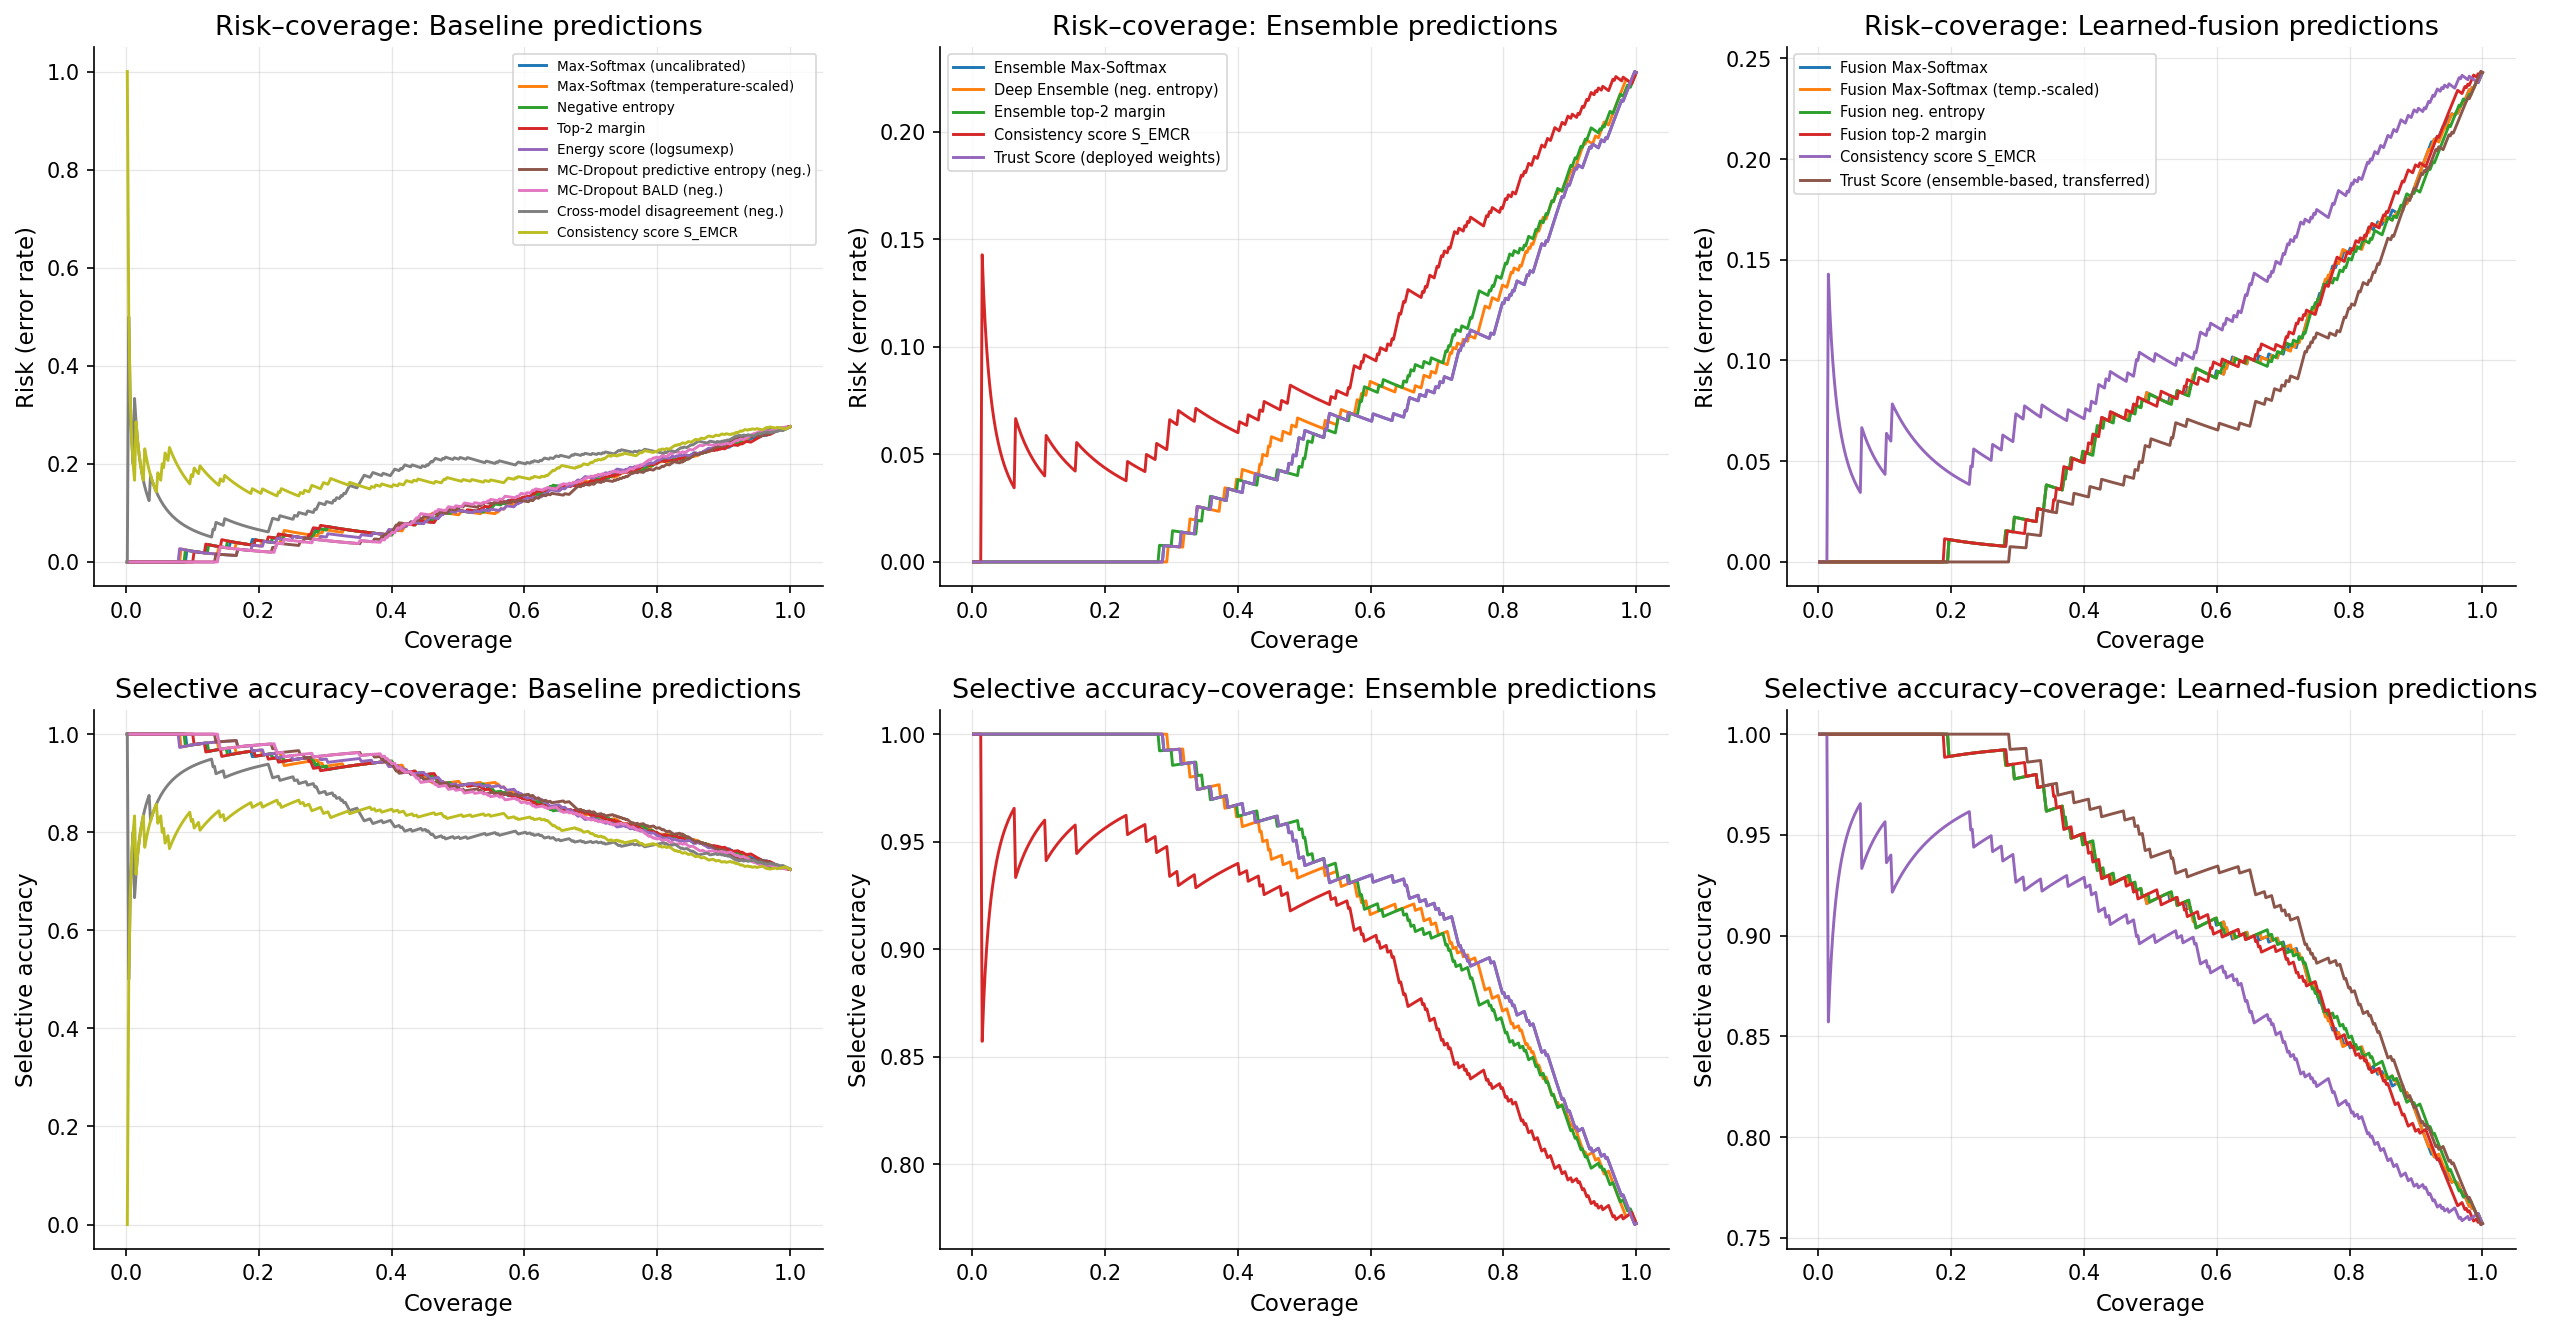

In [53]:
# ---------------- selective-prediction helpers ----------------
def aurc_fast(score, correct):
    score = np.asarray(score, dtype=np.float64)
    correct = np.asarray(correct).astype(np.float64)
    order = np.argsort(-score, kind="mergesort")
    c = correct[order]
    k = np.arange(1, len(c) + 1)
    risk = 1.0 - np.cumsum(c) / k
    return float(np.trapz(risk, k / len(c)))

def risk_coverage_curve(score, correct):
    score = np.asarray(score, dtype=np.float64)
    correct = np.asarray(correct).astype(np.float64)
    order = np.argsort(-score, kind="mergesort")
    c = correct[order]
    k = np.arange(1, len(c) + 1)
    sel_acc = np.cumsum(c) / k
    return k / len(c), 1.0 - sel_acc, sel_acc

def selective_metrics(score, correct, name=""):
    score = np.asarray(score, dtype=np.float64)
    correct = np.asarray(correct).astype(bool)
    n = len(correct)
    cov, risk, sel_acc = risk_coverage_curve(score, correct)
    aurc = float(np.trapz(risk, cov))
    oracle = aurc_fast(correct.astype(float), correct)
    def acc_at(c):
        k = max(1, int(round(c * n)))
        return float(sel_acc[k - 1])
    def cov_at_acc(t):
        ok = np.where(sel_acc >= t)[0]
        return float(cov[ok.max()]) if len(ok) else 0.0
    try:
        auroc = float(roc_auc_score(correct.astype(int), score))
    except ValueError:
        auroc = float("nan")
    return {"Ranker": name, "AURC": aurc, "E-AURC": aurc - oracle, "AUROC": auroc,
            "SelAcc@90%cov": acc_at(0.9), "SelAcc@80%cov": acc_at(0.8),
            "SelAcc@50%cov": acc_at(0.5),
            "Cov@90%acc": cov_at_acc(0.90), "Cov@95%acc": cov_at_acc(0.95)}

def entropy_np(p):
    p = np.clip(p, 1e-12, 1.0)
    return -(p * np.log(p)).sum(axis=1)

def margin_np(p):
    s = np.sort(p, axis=1)
    return s[:, -1] - s[:, -2]

def logsumexp_np(logits):
    z = np.asarray(logits, dtype=np.float64)
    m = z.max(axis=1, keepdims=True)
    return (m + np.log(np.exp(z - m).sum(axis=1, keepdims=True))).ravel()


base_pred    = uncal_probs.argmax(1);        base_correct = (base_pred == y_val_i)
ens_pred     = ensemble_probs.argmax(1);     ens_correct_i = (ens_pred == y_val_i)
fus_pred     = fusion_probs_unc.argmax(1);   fus_correct = (fus_pred == y_val_i)
energy_conf  = logsumexp_np(val_logits.numpy())          # higher = more confident (T=1 energy)

def rank_table(rankers, correct):
    rows = [selective_metrics(s, correct, nm) for nm, s in rankers.items()]
    return pd.DataFrame(rows)

# A) rankers evaluated on the BASELINE's predictions
rank_A = OrderedDict([
    ("Max-Softmax (uncalibrated)",            uncal_probs.max(1)),
    ("Max-Softmax (temperature-scaled)",      cal_probs.max(1)),
    ("Negative entropy",                      -entropy_np(uncal_probs)),
    ("Top-2 margin",                          margin_np(uncal_probs)),
    ("Energy score (logsumexp)",              energy_conf),
    ("MC-Dropout predictive entropy (neg.)",  -np.asarray(mc_pred_entropy)),
    ("MC-Dropout BALD (neg.)",                -np.asarray(mc_epistemic)),
    ("Cross-model disagreement (neg.)",       -np.asarray(model_disagreement)),
    ("Consistency score S_EMCR",              np.asarray(consistency_scores)),
])
rank_tab_A = rank_table(rank_A, base_correct)

# B) rankers evaluated on the simple-average ENSEMBLE predictions (the trust-layer setting)
rank_B = OrderedDict([
    ("Ensemble Max-Softmax",                  ensemble_probs.max(1)),
    ("Deep Ensemble (neg. entropy)",          -entropy_np(ensemble_probs)),
    ("Ensemble top-2 margin",                 margin_np(ensemble_probs)),
    ("Consistency score S_EMCR",              np.asarray(consistency_scores)),
    ("Trust Score (deployed weights)",        np.asarray(trust_score)),
])
rank_tab_B = rank_table(rank_B, ens_correct_i)

# C) rankers evaluated on the LEARNED-FUSION predictions
rank_C = OrderedDict([
    ("Fusion Max-Softmax",                    fusion_probs_unc.max(1)),
    ("Fusion Max-Softmax (temp.-scaled)",     fusion_probs_ts.max(1)),
    ("Fusion neg. entropy",                   -entropy_np(fusion_probs_unc)),
    ("Fusion top-2 margin",                   margin_np(fusion_probs_unc)),
    ("Consistency score S_EMCR",              np.asarray(consistency_scores)),
    ("Trust Score (ensemble-based, transferred)", np.asarray(trust_score)),
])
rank_tab_C = rank_table(rank_C, fus_correct)

pd.set_option("display.width", 220)
for title, tab, c in [("A) Baseline predictions", rank_tab_A, base_correct),
                      ("B) Simple-average ensemble predictions", rank_tab_B, ens_correct_i),
                      ("C) Learned-fusion predictions", rank_tab_C, fus_correct)]:
    print(f"\n=== {title}  (accuracy = {c.mean():.4f}, error rate = {1-c.mean():.4f}) ===")
    print(tab.round(4).to_string(index=False))
    tab.to_csv(REV_DIR / f"reliability_ranker_{title[0]}.csv", index=False)

# ---- curves ----
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for col, (ttl, rankers, c) in enumerate([("Baseline predictions", rank_A, base_correct),
                                         ("Ensemble predictions", rank_B, ens_correct_i),
                                         ("Learned-fusion predictions", rank_C, fus_correct)]):
    for nm, s in rankers.items():
        cov, risk, sel = risk_coverage_curve(s, c)
        axes[0, col].plot(cov, risk, label=nm, linewidth=1.4)
        axes[1, col].plot(cov, sel, label=nm, linewidth=1.4)
    axes[0, col].set_title(f"Risk–coverage: {ttl}"); axes[0, col].set_xlabel("Coverage"); axes[0, col].set_ylabel("Risk (error rate)")
    axes[1, col].set_title(f"Selective accuracy–coverage: {ttl}"); axes[1, col].set_xlabel("Coverage"); axes[1, col].set_ylabel("Selective accuracy")
    for r_ in (0, 1): axes[r_, col].grid(alpha=0.3)
axes[0, 0].legend(fontsize=6.5); axes[0, 1].legend(fontsize=7); axes[0, 2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(REV_DIR / "selective_prediction_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# STEP 49 — Ablation Studies

Four ablations, all on the validation set and all reporting **mean ± std over seeds / splits** wherever randomness is involved:

* **(A)** evidence-branch subsets (Base / CLIP / XGB) with a *simple average* and with the *learned MLP* (5 seeds; best-epoch = original protocol, last-epoch = no validation-based selection)
* **(A3)** *honest* stacking: the same fusion idea trained with **5-fold cross-validation on held-out base-model probabilities** (removes the train-set-probability leakage and the epoch-selection-on-validation bias)
* **(B)** S_EMCR component ablation (w/o OCR, w/o metadata, w/o semantic …)
* **(C)** trust-signal subsets (confidence / epistemic / disagreement / consistency) under the **same held-out protocol as STEP 39**

MLP branch ablation:   0%|          | 0/7 [00:00<?, ?it/s]


(A) Branch-subset ablation
                              Combiner      Branches                             Selection  n_runs        Accuracy         MacroF1             NLL           Brier             ECE             MCE       AURC(MSP)
  Simple average (calibrated baseline)          Base                                     -       1          0.7243          0.7198          0.9856          0.4300          0.1449          0.3557          0.1145
Simple average (uncalibrated baseline)          Base                                     -       1          0.7243          0.7198          1.7123          0.4794          0.2145          0.4573          0.1152
  Simple average (calibrated baseline)          CLIP                                     -       1          0.6630          0.6617          1.2383          0.5917          0.2951          0.4922          0.1536
  Simple average (calibrated baseline)           XGB                                     -       1          0.5624          0.55

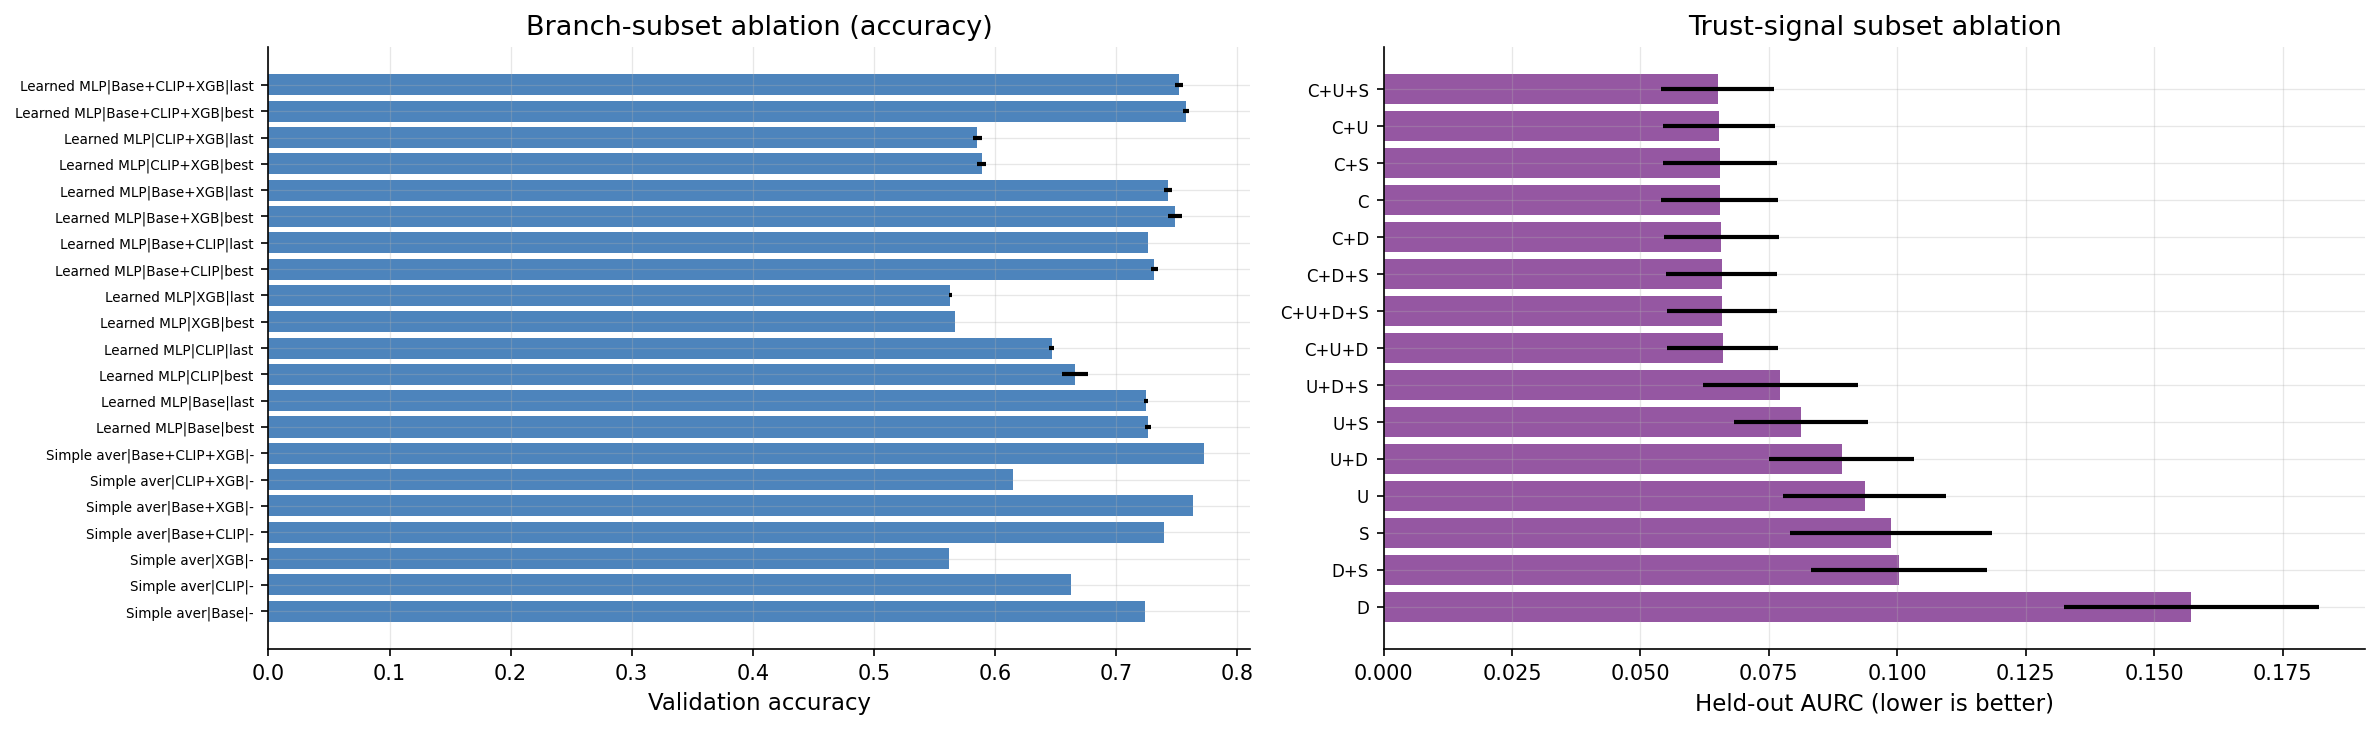

In [54]:
# ---------------- ablation helpers ----------------
def simplex_grid(k, step=0.2):
    n = int(round(1.0 / step))
    out = []
    for comb in itertools.product(range(n + 1), repeat=k):
        if sum(comb) == n:
            out.append(np.array(comb, dtype=np.float64) / n)
    return np.array(out)

def heldout_subset_ablation(Z, correct, subset_idx, n_splits=20, frac_fit=0.5, step=0.2):
    """Z: (n, n_signals) matrix of normalised 'higher = more reliable' signals.
    For each split (same RNG protocol as STEP 39) pick weights on the fit half,
    evaluate on the held-out half. Column 0 of Z must be the confidence signal."""
    n = len(correct)
    W = simplex_grid(len(subset_idx), step)
    rows = []
    for s in range(n_splits):
        rng = np.random.default_rng(s)
        perm = rng.permutation(n)
        cut = int(frac_fit * n)
        fit_idx, eval_idx = perm[:cut], perm[cut:]
        Zs = Z[:, subset_idx]
        fit_scores = Zs[fit_idx] @ W.T
        fit_aurc = np.array([aurc_fast(fit_scores[:, g], correct[fit_idx]) for g in range(W.shape[0])])
        g_best = int(np.argmin(fit_aurc))
        w_best = W[g_best]
        eval_aurc = aurc_fast(Zs[eval_idx] @ w_best, correct[eval_idx])
        conf_only = aurc_fast(Z[eval_idx, 0], correct[eval_idx])
        rows.append({"split": s, "eval_AURC": eval_aurc, "conf_only_AURC": conf_only,
                     "improvement": conf_only - eval_aurc, "weights": tuple(np.round(w_best, 2))})
    return pd.DataFrame(rows)

def consistency_variants(S_TI, S_TO, S_M):
    def w(a, b, c):
        s = a + b + c
        return (a / s, b / s, c / s)
    return OrderedDict([
        ("S_TI only", (1, 0, 0)), ("S_TO only", (0, 1, 0)), ("S_M only", (0, 0, 1)),
        ("w/o Metadata (S_TI+S_TO)", w(.5, .3, 0)),
        ("w/o OCR (S_TI+S_M)", w(.5, 0, .2)),
        ("w/o Semantic (S_TO+S_M)", w(0, .3, .2)),
        ("Full (0.5/0.3/0.2)", (.5, .3, .2)),
        ("Equal weights", (1 / 3, 1 / 3, 1 / 3))])

def evaluate_consistency_variants(S_TI, S_TO, S_M, correct):
    correct = np.asarray(correct).astype(bool)
    rows = []
    for name, (a, b, c) in consistency_variants(S_TI, S_TO, S_M).items():
        score = a * S_TI + b * S_TO + c * S_M
        m = selective_metrics(score, correct, name)
        try:
            u = stats.mannwhitneyu(score[correct], score[~correct], alternative="greater")
            p = float(u.pvalue)
        except ValueError:
            p = float("nan")
        rows.append({"Variant": name, "AUROC(correct)": m["AUROC"], "AURC": m["AURC"],
                     "SelAcc@50%cov": m["SelAcc@50%cov"],
                     "mean(score|correct)": float(score[correct].mean()),
                     "mean(score|wrong)": float(score[~correct].mean()),
                     "MWU p (correct>wrong)": p})
    return pd.DataFrame(rows)


import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from itertools import combinations
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
y_val_i = np.asarray(val_labels_np).astype(int)

# ============ (A) branch-subset ablation ============
SUBSETS = [("Base",), ("CLIP",), ("XGB",), ("Base", "CLIP"), ("Base", "XGB"), ("CLIP", "XGB"), ("Base", "CLIP", "XGB")]
src = {"Base": cal_probs, "CLIP": clip_val_probs, "XGB": xgb_val_probs}

abl_rows = []
for names in SUBSETS:
    P = np.mean([src[n] for n in names], axis=0)
    r = reliability_metrics(P, y_val_i); r["AURC(MSP)"] = aurc_fast(P.max(1), P.argmax(1) == y_val_i)
    abl_rows.append({"Combiner": "Simple average (calibrated baseline)", "Branches": "+".join(names), "Selection": "-", "n_runs": 1,
                     **{k: (v, 0.0) for k, v in r.items()}})
    if "Base" in names:
        Pu = np.mean([uncal_probs if n == "Base" else src[n] for n in names], axis=0)
        ru = reliability_metrics(Pu, y_val_i); ru["AURC(MSP)"] = aurc_fast(Pu.max(1), Pu.argmax(1) == y_val_i)
        abl_rows.append({"Combiner": "Simple average (uncalibrated baseline)", "Branches": "+".join(names), "Selection": "-", "n_runs": 1,
                         **{k: (v, 0.0) for k, v in ru.items()}})

BRANCH_COLS = {"Base": np.arange(0, 6), "CLIP": np.arange(6, 12), "XGB": np.arange(12, 18)}
def subset_cols(names): return np.concatenate([BRANCH_COLS[n] for n in names])

def train_fusion_subset(names, seed, epochs=50, hidden=64, dropout=0.2, lr=1e-3, batch_size=32):
    cols = subset_cols(names)
    Xtr = Xf_train[:, cols].float().cpu(); ytr = yf_train.cpu(); Xva = Xf_val[:, cols].float().cpu()
    torch.manual_seed(seed); np.random.seed(seed)
    net = nn.Sequential(nn.Linear(len(cols), hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 6))
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss(weight=class_weights_tensor.detach().cpu())
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True, generator=gen)
    best_f1, best_logits, last_logits = -1.0, None, None
    for ep in range(epochs):
        net.train()
        for xb, yb in loader:
            opt.zero_grad(); loss = crit(net(xb), yb); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): lg = net(Xva)
        f1 = f1_score(y_val_i, lg.argmax(1).numpy(), average="macro")
        if f1 > best_f1: best_f1, best_logits = f1, lg.clone()
        last_logits = lg
    return F.softmax(best_logits, 1).numpy(), F.softmax(last_logits, 1).numpy()

ABL_SEEDS = [0, 1, 2, 3, 4]
mlp_runs = {}
for names in tqdm(SUBSETS, desc="MLP branch ablation"):
    best_l, last_l = [], []
    for s in ABL_SEEDS:
        pb, pl = train_fusion_subset(names, s)
        for store, P in ((best_l, pb), (last_l, pl)):
            r = reliability_metrics(P, y_val_i); r["AURC(MSP)"] = aurc_fast(P.max(1), P.argmax(1) == y_val_i); store.append(r)
    mlp_runs[names] = (pd.DataFrame(best_l), pd.DataFrame(last_l))
    for sel, df_ in (("best epoch on val (original protocol)", mlp_runs[names][0]), ("last epoch (no val selection)", mlp_runs[names][1])):
        abl_rows.append({"Combiner": "Learned MLP (train-set probs)", "Branches": "+".join(names), "Selection": sel, "n_runs": len(ABL_SEEDS),
                         **{k: (float(df_[k].mean()), float(df_[k].std(ddof=1))) for k in df_.columns}})

def fmt(ms): return f"{ms[0]:.4f}" if ms[1] == 0 else f"{ms[0]:.4f} ± {ms[1]:.4f}"
METRIC_COLS = ["Accuracy", "MacroF1", "NLL", "Brier", "ECE", "MCE", "AURC(MSP)"]
ablation_branch_df = pd.DataFrame([{**{k: r[k] for k in ("Combiner", "Branches", "Selection", "n_runs")},
                                    **{m: fmt(r[m]) for m in METRIC_COLS}} for r in abl_rows])
print("\n(A) Branch-subset ablation")
print(ablation_branch_df.to_string(index=False))
ablation_branch_df.to_csv(REV_DIR / "ablation_branch_subsets.csv", index=False)

# ============ (A3) honest stacking: 5-fold CV on held-out base-model probabilities ============
Xval_all = np.hstack([uncal_probs, clip_val_probs, xgb_val_probs])
def cv_stack(model_fn, cols, seeds=range(5)):
    res = []
    for s in seeds:
        skf = StratifiedKFold(5, shuffle=True, random_state=s)
        P = cross_val_predict(model_fn(s), Xval_all[:, cols], y_val_i, cv=skf, method="predict_proba")
        r = reliability_metrics(P, y_val_i); r["AURC(MSP)"] = aurc_fast(P.max(1), P.argmax(1) == y_val_i); res.append(r)
    return pd.DataFrame(res)

stack_rows = []
ref = reliability_metrics(uncal_probs, y_val_i)
stack_rows.append({"Method": "Baseline alone (uncalibrated)", **{k: f"{ref[k]:.4f}" for k in ["Accuracy", "MacroF1", "NLL", "Brier", "ECE"]}})
Pavg = np.mean([cal_probs, clip_val_probs, xgb_val_probs], axis=0); ra = reliability_metrics(Pavg, y_val_i)
stack_rows.append({"Method": "Simple average of 3 branches", **{k: f"{ra[k]:.4f}" for k in ["Accuracy", "MacroF1", "NLL", "Brier", "ECE"]}})
rf = reliability_metrics(fusion_probs_unc, y_val_i)
stack_rows.append({"Method": "Learned MLP fusion as deployed (train-set probs, best epoch on val)", **{k: f"{rf[k]:.4f}" for k in ["Accuracy", "MacroF1", "NLL", "Brier", "ECE"]}})
models = [("Logistic-regression stacker", lambda s: LogisticRegression(max_iter=2000, C=1.0)),
          ("MLP stacker (64 hidden)",     lambda s: MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, random_state=s))]
for nm, mf in models:
    for cols_name, cols in [("Base+CLIP+XGB", np.arange(18)), ("CLIP+XGB (no baseline)", np.arange(6, 18))]:
        d = cv_stack(mf, cols)
        stack_rows.append({"Method": f"5-fold CV on validation probs: {nm}, {cols_name}",
                           **{k: f"{d[k].mean():.4f} ± {d[k].std(ddof=1):.4f}" for k in ["Accuracy", "MacroF1", "NLL", "Brier", "ECE"]}})
stack_cv_df = pd.DataFrame(stack_rows)
print("\n(A3) Honest stacking (out-of-fold, no val-based epoch selection, no train-set-probability leakage)")
print(stack_cv_df.to_string(index=False))
stack_cv_df.to_csv(REV_DIR / "stacking_cv_validation.csv", index=False)

# ============ (B) S_EMCR component ablation ============
S_TI = reasoning_df["text_image_alignment"].values.astype(float)
S_TO = reasoning_df["ocr_similarity"].values.astype(float)
S_M  = reasoning_df["metadata_signal"].values.astype(float)
corr_fus_series = reasoning_df["correct"].values.astype(bool)
consistency_abl_df = evaluate_consistency_variants(S_TI, S_TO, S_M, corr_fus_series)
print("\n(B) S_EMCR component ablation (ranking quality for the learned-fusion predictions' correctness)")
print(consistency_abl_df.round(4).to_string(index=False))
consistency_abl_df.to_csv(REV_DIR / "ablation_consistency_components.csv", index=False)

# ============ (C) trust-signal subset ablation under the held-out protocol ============
ens_corr_i = (ensemble_probs.argmax(1) == y_val_i)
Zsig = np.column_stack([conf_norm, 1 - epistemic_norm, 1 - disagreement_norm, consistency_norm])
SIG_NAMES = ["C (confidence)", "U (1-epistemic)", "D (1-disagreement)", "S (consistency)"]
tr_rows = []
for r_ in range(1, 5):
    for sub in combinations(range(4), r_):
        d = heldout_subset_ablation(Zsig, ens_corr_i, list(sub), n_splits=20, frac_fit=0.5, step=0.2)
        modal = d["weights"].value_counts().index[0]
        tr_rows.append({"Signals": "+".join(SIG_NAMES[i][0] for i in sub), "n_signals": r_,
                        "held-out AURC (mean)": d["eval_AURC"].mean(), "held-out AURC (std)": d["eval_AURC"].std(ddof=1),
                        "mean gain vs conf-only": d["improvement"].mean(),
                        "win-rate vs conf-only": float((d["improvement"] > 0).mean()),
                        "most-selected weights": str(modal)})
trust_signal_abl_df = pd.DataFrame(tr_rows).sort_values("held-out AURC (mean)").reset_index(drop=True)
print("\n(C) Trust-signal subset ablation (20 random 50/50 splits, same RNG protocol as STEP 39; positive gain = better than confidence alone)")
print(trust_signal_abl_df.round(4).to_string(index=False))
trust_signal_abl_df.to_csv(REV_DIR / "ablation_trust_signals.csv", index=False)

# ---- figures ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
lab = [f"{r['Combiner'][:11]}|{r['Branches']}|{r['Selection'][:4]}" for r in abl_rows if r["Combiner"].startswith("Learned") or "(calibrated" in r["Combiner"]]
acc_m = [r["Accuracy"][0] for r in abl_rows if r["Combiner"].startswith("Learned") or "(calibrated" in r["Combiner"]]
acc_s = [r["Accuracy"][1] for r in abl_rows if r["Combiner"].startswith("Learned") or "(calibrated" in r["Combiner"]]
axes[0].barh(range(len(lab)), acc_m, xerr=acc_s, color="#2166ac", alpha=0.8); axes[0].set_yticks(range(len(lab))); axes[0].set_yticklabels(lab, fontsize=6.5)
axes[0].set_xlabel("Validation accuracy"); axes[0].set_title("Branch-subset ablation (accuracy)"); axes[0].grid(axis="x", alpha=0.3)
axes[1].barh(range(len(trust_signal_abl_df)), trust_signal_abl_df["held-out AURC (mean)"], xerr=trust_signal_abl_df["held-out AURC (std)"], color="#7b2d8b", alpha=0.8)
axes[1].set_yticks(range(len(trust_signal_abl_df))); axes[1].set_yticklabels(trust_signal_abl_df["Signals"], fontsize=8)
axes[1].set_xlabel("Held-out AURC (lower is better)"); axes[1].set_title("Trust-signal subset ablation"); axes[1].grid(axis="x", alpha=0.3); axes[1].invert_yaxis()
plt.tight_layout(); plt.savefig(REV_DIR / "ablation_overview.png", dpi=300, bbox_inches="tight"); plt.show()

# STEP 50 — Statistical Significance Testing

* paired bootstrap (B = 2000, resampling validation instances) for ΔAURC, Δaccuracy and Δ(ECE / Brier / NLL)
* exact McNemar test for the accuracy comparisons
* Wilson 95 % CIs per decision tier + Fisher exact tests between tiers
* one-sample t-test / Wilcoxon / sign test on the 20 held-out improvements and t-based CIs over the 5 resampling seeds

⚠️ The 20 held-out splits overlap (they all resample the same 457 rows), so their p-values are only indicative; the paired-bootstrap rows are the primary evidence.

In [55]:
# ---------------- significance-testing helpers ----------------
def boot_indices(n, B=2000, seed=0):
    return np.random.default_rng(seed).integers(0, n, size=(B, n))

def paired_boot_diff(fn_a, fn_b, idx_boot):
    """fn(idx)->float. Returns observed diff (a-b), 95% CI and two-sided p."""
    n = idx_boot.shape[1]
    full = np.arange(n)
    obs = fn_a(full) - fn_b(full)
    d = np.array([fn_a(ix) - fn_b(ix) for ix in idx_boot])
    lo, hi = np.percentile(d, [2.5, 97.5])
    p = 2.0 * min((d <= 0).mean(), (d >= 0).mean())
    return float(obs), float(lo), float(hi), float(min(1.0, max(p, 1.0 / len(d))))

def mcnemar_exact(correct_a, correct_b):
    a = np.asarray(correct_a).astype(bool); b = np.asarray(correct_b).astype(bool)
    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
    nd = only_a + only_b
    p = 1.0 if nd == 0 else float(stats.binomtest(only_a, nd, 0.5).pvalue)
    return only_a, only_b, p

def wilson_ci(k, n, conf=0.95):
    if n == 0:
        return float("nan"), float("nan")
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=conf, method="wilson")
    return float(ci.low), float(ci.high)

def t_ci(x, conf=0.95):
    x = np.asarray(x, dtype=np.float64)
    m = x.mean(); s = x.std(ddof=1); n = len(x)
    h = stats.t.ppf(0.5 + conf / 2, n - 1) * s / np.sqrt(n)
    return float(m), float(m - h), float(m + h)


y_val_i = np.asarray(val_labels_np).astype(int); n = len(y_val_i)
B = 2000
idx_boot = boot_indices(n, B=B, seed=0)

base_correct = (uncal_probs.argmax(1) == y_val_i)
ens_correct_i = (ensemble_probs.argmax(1) == y_val_i)
fus_correct = (fusion_probs_unc.argmax(1) == y_val_i)
energy_conf = logsumexp_np(val_logits.numpy())

specs = OrderedDict([
    ("Trust Score (deployed)",       (np.asarray(trust_score), ens_correct_i)),
    ("Deep Ensemble (neg. entropy)", (-entropy_np(ensemble_probs), ens_correct_i)),
    ("Max-Softmax (baseline)",       (uncal_probs.max(1), base_correct)),
    ("Energy (baseline)",            (energy_conf, base_correct)),
])
def aurc_fn(name):
    s, c = specs[name]
    return lambda ix: aurc_fast(s[ix], c[ix])

sig_rows = []
def add(test, est, lo, hi, p, note=""):
    sig_rows.append({"Test": test, "Estimate": est, "CI95_low": lo, "CI95_high": hi, "p_value": p, "Note": note})

# --- 1) paired-bootstrap ΔAURC ---
for a, b in [("Trust Score (deployed)", "Deep Ensemble (neg. entropy)"),
             ("Trust Score (deployed)", "Max-Softmax (baseline)"),
             ("Trust Score (deployed)", "Energy (baseline)"),
             ("Deep Ensemble (neg. entropy)", "Max-Softmax (baseline)")]:
    est, lo, hi, p = paired_boot_diff(aurc_fn(a), aurc_fn(b), idx_boot)
    add(f"ΔAURC: {a} − {b}", est, lo, hi, p, "negative = first method better; paired bootstrap")

# --- 2) accuracy comparisons ---
acc_pairs = [("Learned fusion", fus_correct, "Baseline", base_correct),
             ("Simple-average ensemble", ens_correct_i, "Baseline", base_correct),
             ("Learned fusion", fus_correct, "Simple-average ensemble", ens_correct_i)]
for na, ca, nb, cb in acc_pairs:
    est, lo, hi, p = paired_boot_diff(lambda ix, c=ca: c[ix].mean(), lambda ix, c=cb: c[ix].mean(), idx_boot)
    oa, ob, pm = mcnemar_exact(ca, cb)
    add(f"ΔAccuracy: {na} − {nb}", est, lo, hi, pm, f"paired bootstrap p={p:.4f}; McNemar exact p shown; discordant: only-{na}={oa}, only-{nb}={ob}")

# --- 3) calibration effect of temperature scaling (baseline) ---
for nm, fn in [("ECE", lambda P, y: ece_mce(P, y)[0]), ("Brier", brier_multiclass), ("NLL", nll_score)]:
    est, lo, hi, p = paired_boot_diff(lambda ix: fn(cal_probs[ix], y_val_i[ix]), lambda ix: fn(uncal_probs[ix], y_val_i[ix]),
                                      idx_boot[:1000])
    add(f"Δ{nm}: temperature-scaled − uncalibrated (baseline, in-sample T)", est, lo, hi, p, "negative = calibration improved; B=1000")
for nm, fn in [("ECE", lambda P, y: ece_mce(P, y)[0]), ("Brier", brier_multiclass), ("NLL", nll_score)]:
    est, lo, hi, p = paired_boot_diff(lambda ix: fn(base_probs_cf[ix], y_val_i[ix]), lambda ix: fn(uncal_probs[ix], y_val_i[ix]),
                                      idx_boot[:1000])
    add(f"Δ{nm}: cross-fitted TS − uncalibrated (baseline)", est, lo, hi, p, "negative = improved; B=1000")

# --- 4) decision tiers ---
dec = trust_df["decision"].values
tier_stats = {}
for tier in ["ACCEPT", "FLAG_FOR_REVIEW", "ABSTAIN"]:
    m = dec == tier; k = int(ens_correct_i[m].sum()); nn_ = int(m.sum())
    lo, hi = wilson_ci(k, nn_); tier_stats[tier] = (k, nn_)
    add(f"Tier accuracy: {tier}", k / max(nn_, 1), lo, hi, float("nan"), f"{k}/{nn_} correct (Wilson 95% CI)")
for ta, tb in [("ACCEPT", "FLAG_FOR_REVIEW"), ("FLAG_FOR_REVIEW", "ABSTAIN"), ("ACCEPT", "ABSTAIN")]:
    (k1, n1), (k2, n2) = tier_stats[ta], tier_stats[tb]
    odds, p = stats.fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])
    add(f"Fisher exact: accuracy({ta}) vs accuracy({tb})", (k1 / n1) - (k2 / n2), float("nan"), float("nan"), float(p), f"odds ratio={odds:.2f}")

# --- 5) held-out splits (STEP 39) ---
imp = trials_df["improvement"].values
m_, lo_, hi_ = t_ci(imp)
add("Held-out improvement over confidence-only (mean over 20 splits)", m_, lo_, hi_, float(stats.ttest_1samp(imp, 0.0).pvalue), "one-sample t-test; splits overlap -> indicative only")
try:
    add("Held-out improvement: Wilcoxon signed-rank", float(np.median(imp)), float("nan"), float("nan"), float(stats.wilcoxon(imp).pvalue), "median improvement")
except ValueError:
    add("Held-out improvement: Wilcoxon signed-rank", float(np.median(imp)), float("nan"), float("nan"), float("nan"), "all differences zero")
pos, neg = int((imp > 0).sum()), int((imp < 0).sum())
add("Held-out improvement: sign test", pos / max(pos + neg, 1), float("nan"), float("nan"),
    float(stats.binomtest(pos, pos + neg, 0.5).pvalue) if pos + neg else float("nan"), f"{pos} splits better, {neg} worse")

# --- 6) multi-seed resampling stability ---
for col in ["T", "ECE", "AURC", "accuracy"]:
    m_, lo_, hi_ = t_ci(multiseed_df[col].values)
    add(f"Multi-seed mean (5 seeds): {col}", m_, lo_, hi_, float("nan"), "t-based 95% CI over seeds")

sig_df = pd.DataFrame(sig_rows)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
print(sig_df.round(4).to_string(index=False))
sig_df.to_csv(REV_DIR / "significance_tests.csv", index=False)
print("\nInterpretation guide: a ΔAURC CI that excludes 0 indicates a ranking difference that is unlikely to be resampling noise;"
      " if it includes 0 (expected for Trust vs Deep Ensemble, which differ only in max-prob vs entropy ranking) the difference should not be claimed as an improvement.")

                                                             Test  Estimate  CI95_low  CI95_high  p_value                                                                                                                 Note
     ΔAURC: Trust Score (deployed) − Deep Ensemble (neg. entropy)   -0.0045   -0.0095     0.0003   0.0680                                                                     negative = first method better; paired bootstrap
           ΔAURC: Trust Score (deployed) − Max-Softmax (baseline)   -0.0506   -0.0719    -0.0313   0.0005                                                                     negative = first method better; paired bootstrap
                ΔAURC: Trust Score (deployed) − Energy (baseline)   -0.0492   -0.0701    -0.0302   0.0005                                                                     negative = first method better; paired bootstrap
     ΔAURC: Deep Ensemble (neg. entropy) − Max-Softmax (baseline)   -0.0461   -0.0675    -0.0267   0.0005   

# STEP 51 — Qualitative Case Studies

Selects representative validation instances per decision tier (most-reliable correct ACCEPT, **false ACCEPT**, FLAG with the largest text-image / OCR conflict, correctly-withheld ABSTAIN, and lost-opportunity ABSTAIN), attaches a **rule-based rationale** built from the evidence signals, draws an image grid, and writes a LaTeX table you can paste into the paper.

In [56]:
# ---------------- qualitative case-study helpers ----------------
def latex_escape(s):
    s = str(s)
    rep = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
           "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\^{}"}
    return "".join(rep.get(ch, ch) for ch in s)

def build_level_fn(case_df, cols=("S_TI", "S_TO", "S_M", "epistemic", "disagreement")):
    q = {c: np.quantile(case_df[c].values, [0.25, 0.75]) for c in cols}
    def level(v, key):
        lo, hi = q[key]
        return "low" if v <= lo else ("high" if v >= hi else "moderate")
    return level

def explain_case(r, level, ocr_has_text):
    parts = [f"text-image agreement is {level(r['S_TI'], 'S_TI')} (S_TI={r['S_TI']:.2f})"]
    if ocr_has_text:
        parts.append(f"OCR text agreement with the headline is {level(r['S_TO'], 'S_TO')} (S_TO={r['S_TO']:.2f})")
    else:
        parts.append("no readable text in the image (OCR signal neutral)")
    parts.append(f"structural evidence is {level(r['S_M'], 'S_M')} (S_M={r['S_M']:.2f})")
    parts.append(f"epistemic uncertainty is {level(r['epistemic'], 'epistemic')}")
    parts.append(f"cross-model disagreement is {level(r['disagreement'], 'disagreement')}")
    return (f"{r['decision']}: " + "; ".join(parts) +
            f". Predicted {r['ens_pred']} (true: {r['true']}).")

def select_cases(case_df, n_per=2, seed=0):
    d = case_df.copy()
    sel = []
    def take(frame, cat, ascending=False, by="trust", k=n_per):
        f = frame.sort_values(by, ascending=ascending).head(k).copy()
        f["category"] = cat
        sel.append(f)
    acc = d[d["decision"] == "ACCEPT"]
    take(acc[acc["ens_correct"]], "ACCEPT - correct (most reliable)")
    take(acc[~acc["ens_correct"]], "ACCEPT - wrong (false accept)")
    fl = d[d["decision"] == "FLAG_FOR_REVIEW"].copy()
    fl["conflict"] = (fl["S_TI"] - fl["S_TO"]).abs()
    take(fl, "FLAG - modality conflict", by="conflict")
    ab = d[d["decision"] == "ABSTAIN"]
    take(ab[~ab["ens_correct"]], "ABSTAIN - wrong (correctly withheld)", ascending=True)
    take(ab[ab["ens_correct"]], "ABSTAIN - correct (lost opportunity)", ascending=True)
    out = pd.concat(sel, ignore_index=True) if sel else d.head(0)
    return out


import textwrap
from PIL import Image
import matplotlib.pyplot as plt

y_val_i = np.asarray(val_labels_np).astype(int)
ens_pred_i = ensemble_probs.argmax(1)
case_df = pd.DataFrame({
    "id":          val_feat_df["id"].values,
    "title":       val_feat_df["clean_title"].values,
    "ocr_text":    val_feat_df["ocr_text"].fillna("").astype(str).values if "ocr_text" in val_feat_df else [""] * len(val_feat_df),
    "image_path":  val_feat_df["local_image_path"].values,
    "true":        [label_map[int(k)] for k in y_val_i],
    "ens_pred":    [label_map[int(k)] for k in ens_pred_i],
    "fusion_pred": reasoning_df["pred_label"].values,
    "ens_correct": (ens_pred_i == y_val_i),
    "fusion_correct": reasoning_df["correct"].values.astype(bool),
    "trust":       np.asarray(trust_score),
    "decision":    trust_df["decision"].values,
    "ens_conf":    np.asarray(ensemble_confidence),
    "epistemic":   np.asarray(mc_epistemic),
    "disagreement":np.asarray(model_disagreement),
    "S_TI":        reasoning_df["text_image_alignment"].values.astype(float),
    "S_TO":        reasoning_df["ocr_similarity"].values.astype(float),
    "S_M":         reasoning_df["metadata_signal"].values.astype(float),
    "S_EMCR":      reasoning_df["consistency_score"].values.astype(float),
})
level = build_level_fn(case_df)
CASES_PER_CATEGORY = 2
case_sel = select_cases(case_df, n_per=CASES_PER_CATEGORY)
case_sel["ocr_has_text"] = [len(clean_text(t)) >= 3 for t in case_sel["ocr_text"]]
case_sel["rationale"] = [explain_case(r, level, r["ocr_has_text"]) for _, r in case_sel.iterrows()]

show_cols = ["category", "decision", "true", "ens_pred", "trust", "S_TI", "S_TO", "S_M", "epistemic", "disagreement"]
print(case_sel[show_cols].round(3).to_string(index=False))
print()
for _, r in case_sel.iterrows():
    print(f"[{r['category']}]  id={r['id']}\n  headline : {r['title'][:140]}\n  OCR text : {r['ocr_text'][:100]!r}\n  rationale: {r['rationale']}\n")
case_sel.drop(columns=["ocr_has_text"]).to_csv(REV_DIR / "qualitative_case_studies.csv", index=False)

# tier-level signal profile (supports the 'what distinguishes the tiers' discussion)
profile = case_df.groupby("decision")[["trust", "S_TI", "S_TO", "S_M", "epistemic", "disagreement"]].mean().reindex(["ACCEPT", "FLAG_FOR_REVIEW", "ABSTAIN"])
print("Mean evidence signals per decision tier:\n", profile.round(3).to_string())
profile.to_csv(REV_DIR / "tier_signal_profile.csv")

# ---- image grid ----
n_c = len(case_sel); n_cols = min(5, max(n_c, 1)); n_rows = int(np.ceil(n_c / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.8 * n_cols, 5.4 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes: ax.axis("off")
for ax, (_, r) in zip(axes, case_sel.iterrows()):
    try:
        ax.imshow(Image.open(r["image_path"]).convert("RGB"))
    except Exception:
        ax.text(0.5, 0.5, "image unavailable", ha="center", va="center")
    ax.set_title(f"{r['category']}\n{r['decision']}", fontsize=7.5)
    cap = (textwrap.fill(r["title"][:110], 38) + f"\ntrue={r['true']} | pred={r['ens_pred']}\n"
           f"trust={r['trust']:.2f}  S_TI={r['S_TI']:.2f}  S_TO={r['S_TO']:.2f}  S_M={r['S_M']:.2f}\n"
           f"epi={r['epistemic']:.2f}  dis={r['disagreement']:.2f}")
    ax.text(0.5, -0.03, cap, transform=ax.transAxes, va="top", ha="center", fontsize=6.3)
plt.tight_layout()
plt.savefig(REV_DIR / "qualitative_case_studies.png", dpi=250, bbox_inches="tight")
plt.show()

# ---- LaTeX table for the paper ----
tex = [r"\begin{table*}[!t]", r"\centering", r"\caption{Qualitative case studies from the Fakeddit validation set (rule-based rationale from the evidence signals).}",
       r"\label{tab:qualitative_cases}", r"\renewcommand{\arraystretch}{1.2}", r"\scriptsize",
       r"\begin{tabular}{p{3.0cm}p{2.1cm}cccccc}", r"\toprule",
       r"\textbf{Category} & \textbf{True / Pred.} & \textbf{Trust} & \textbf{$S_{TI}$} & \textbf{$S_{TO}$} & \textbf{$S_M$} & \textbf{Epi.} & \textbf{Dis.} \\", r"\midrule"]
for _, r in case_sel.iterrows():
    tex.append(f"{latex_escape(r['category'])} & {latex_escape(r['true'])} / {latex_escape(r['ens_pred'])} & "
               f"{r['trust']:.2f} & {r['S_TI']:.2f} & {r['S_TO']:.2f} & {r['S_M']:.2f} & {r['epistemic']:.2f} & {r['disagreement']:.2f} \\\\")
tex += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
(REV_DIR / "qualitative_cases_table.tex").write_text("\n".join(tex))
print("Saved qualitative_cases_table.tex")

Output hidden; open in https://colab.research.google.com to view.

# STEP 52 — Inference-Cost / Latency Profile of the Full Reliability-Aware Pipeline

In [57]:
import time
from PIL import Image
import torch, torch.nn.functional as F

def _sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()
def _time(fn):
    _sync(); t0 = time.perf_counter(); out = fn(); _sync()
    return (time.perf_counter() - t0) * 1000.0, out

N_PROFILE, MC_T_PROF = 30, 20
prof_rows = val_feat_df.sample(n=min(N_PROFILE, len(val_feat_df)), random_state=0)
KEYS = ["OCR extraction (EasyOCR)", "OCR-title similarity (MiniLM)", "Image metadata features",
        "Baseline pre-processing", "Baseline forward (1 pass)", f"MC-Dropout ({MC_T_PROF} passes)",
        "CLIP pre-processing + forward", "XGBoost inference", "Learned fusion forward", "Trust-layer post-processing"]
timings = OrderedDict((k, []) for k in KEYS)

def profile_one(title, path, record=True):
    t, ocr_text = _time(lambda: extract_ocr_text(path, ocr_reader));         rec = {KEYS[0]: t}
    t, ocr_sim  = _time(lambda: compute_ocr_similarity(title, ocr_text));    rec[KEYS[1]] = t
    t, feat     = _time(lambda: extract_image_features(path));               rec[KEYS[2]] = t
    feat["ocr_text_len"] = float(len(clean_text(ocr_text))); feat["ocr_similarity"] = float(ocr_sim)
    def _prep():
        image = Image.open(path).convert("RGB")
        enc = tokenizer(title, truncation=True, padding="max_length", max_length=MAX_TEXT_LEN, return_tensors="pt")
        return enc, val_image_transform(image).unsqueeze(0)
    t, (enc_txt, img_t) = _time(_prep);                                       rec[KEYS[3]] = t
    ids = enc_txt["input_ids"].to(device); mask = enc_txt["attention_mask"].to(device); img_t = img_t.to(device)
    best_model.eval()
    def _fwd():
        with torch.no_grad(): return best_model(ids, mask, img_t)
    t, base_logits = _time(_fwd);                                             rec[KEYS[4]] = t
    def _mc():
        enable_mc_dropout(best_model)
        with torch.no_grad():
            ps = torch.stack([F.softmax(best_model(ids, mask, img_t), dim=1) for _ in range(MC_T_PROF)])
        best_model.eval(); return ps
    t, mc_ps = _time(_mc);                                                    rec[KEYS[5]] = t
    def _clip():
        image = Image.open(path).convert("RGB")
        enc = clip_processor(text=[title], images=[image], return_tensors="pt", padding=True, truncation=True)
        best_clip_model.eval()
        with torch.no_grad():
            return F.softmax(best_clip_model(enc["input_ids"].to(device), enc["attention_mask"].to(device),
                                             enc["pixel_values"].to(device)), dim=1)
    t, clip_t = _time(_clip);                                                 rec[KEYS[6]] = t
    feat_vec = np.array([feat[c] for c in FEATURE_COLS], dtype=np.float32).reshape(1, -1)
    t, xgb_p = _time(lambda: xgb_model.predict_proba(feat_vec)[0]);           rec[KEYS[7]] = t
    baseline_p = F.softmax(base_logits, 1).cpu().numpy()[0]; clip_p = clip_t.cpu().numpy()[0]
    fin = torch.tensor(np.hstack([baseline_p, clip_p, xgb_p]), dtype=torch.float32).unsqueeze(0).to(device)
    def _fus():
        fusion_model.eval()
        with torch.no_grad(): return F.softmax(fusion_model(fin), 1)
    t, _ = _time(_fus);                                                       rec[KEYS[8]] = t
    def _post():
        cal = F.softmax(base_logits / temp_scaler.T.detach().to(base_logits.device), dim=1).cpu().numpy()
        ens = (cal + clip_p[None] + xgb_p[None]) / 3.0
        dis = jensen_shannon_disagreement([cal, clip_p[None], xgb_p[None]])
        mc = mc_ps.cpu().numpy(); mp = mc.mean(0)
        epi = (-(mp * np.log(mp + 1e-12)).sum(1)) - (-(mc * np.log(mc + 1e-12)).sum(2).mean(0))
        cons = compute_consistency_score(clip_p, ocr_sim, xgb_p)["consistency_score"]
        return ens.max(), epi, dis, cons
    t, _ = _time(_post);                                                      rec[KEYS[9]] = t
    if record:
        for k, v in rec.items(): timings[k].append(v)

first = prof_rows.iloc[0]
for _ in range(2): profile_one(first["clean_title"], first["local_image_path"], record=False)   # warm-up
for _, row in tqdm(prof_rows.iterrows(), total=len(prof_rows), desc="Profiling"):
    profile_one(row["clean_title"], row["local_image_path"])

latency_df = pd.DataFrame({"Component": list(timings.keys()),
                           "mean_ms": [np.mean(v) for v in timings.values()],
                           "std_ms": [np.std(v, ddof=1) for v in timings.values()],
                           "median_ms": [np.median(v) for v in timings.values()]})
latency_df["share_%"] = 100 * latency_df["mean_ms"] / latency_df["mean_ms"].sum()
dev_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
rel_overhead = latency_df.loc[latency_df["Component"].isin([KEYS[5], KEYS[9]]), "mean_ms"].sum()
pred_pipeline = latency_df["mean_ms"].sum() - rel_overhead
print(f"Device: {dev_name} | instances profiled: {len(prof_rows)} (batch size 1, includes pre-processing)")
print(latency_df.round(2).to_string(index=False))
print(f"\nTotal per instance           : {latency_df['mean_ms'].sum():.1f} ms")
print(f"Prediction pipeline (no MC)  : {pred_pipeline:.1f} ms")
print(f"Reliability layer overhead   : {rel_overhead:.1f} ms  ({100*rel_overhead/latency_df['mean_ms'].sum():.1f}% of total; "
      f"MC-Dropout alone = {latency_df.loc[latency_df['Component']==KEYS[5],'mean_ms'].iloc[0]:.1f} ms)")
latency_df.to_csv(REV_DIR / "inference_cost_profile.csv", index=False)

Profiling:   0%|          | 0/30 [00:00<?, ?it/s]

Device: Tesla T4 | instances profiled: 30 (batch size 1, includes pre-processing)
                    Component  mean_ms  std_ms  median_ms  share_%
     OCR extraction (EasyOCR)   137.45  298.54      48.21    25.22
OCR-title similarity (MiniLM)     4.91    5.67       0.05     0.90
      Image metadata features     6.25    7.67       3.42     1.15
      Baseline pre-processing     4.54    3.34       3.46     0.83
    Baseline forward (1 pass)    17.41    1.58      17.02     3.19
       MC-Dropout (20 passes)   350.25   16.98     345.66    64.27
CLIP pre-processing + forward    21.32    3.29      20.55     3.91
            XGBoost inference     1.98    0.13       1.94     0.36
       Learned fusion forward     0.30    0.03       0.29     0.05
  Trust-layer post-processing     0.58    0.08       0.56     0.11

Total per instance           : 545.0 ms
Prediction pipeline (no MC)  : 194.2 ms
Reliability layer overhead   : 350.8 ms  (64.4% of total; MC-Dropout alone = 350.3 ms)


# STEP 53 — Paper-vs-Code Configuration Audit + Paper-Faithful S_TI

Prints the settings the code actually uses next to what the paper states, and recomputes **S_TI as the paper defines it** (cosine similarity of pretrained CLIP text/image embeddings, mapped to [0, 1]) so the consistency score can be reported either way — consistently with the manuscript.

In [58]:
from transformers import CLIPModel
import torch, torch.nn.functional as F
from PIL import Image
from scipy.stats import spearmanr

xp = xgb_model.get_params()
audit_df = pd.DataFrame([
    ["XGBoost n_estimators",       xp.get("n_estimators"),     "100 (Table II)"],
    ["XGBoost max_depth",          xp.get("max_depth"),        "6"],
    ["XGBoost learning_rate",      xp.get("learning_rate"),    "0.10"],
    ["XGBoost subsample",          xp.get("subsample"),        "0.80"],
    ["XGBoost colsample_bytree",   xp.get("colsample_bytree"), "0.80"],
    ["Learned fusion input",       "[p_Base ; p_CLIP ; p_XGB] (18-d)", "[p_Base ; p_CLIP ; p_XGB]"],
    ["Learned fusion training",    "50 epochs, checkpoint = best VAL macro-F1; meta-features = base-model probs on TRAIN rows", "not stated in paper -> state it"],
    ["S_TI (as implemented)",      "max CLIP class probability", "cosine(text_emb, image_emb) mapped by (cos+1)/2"],
    ["S_TO (as implemented)",      "raw cosine, 0.0 if OCR text < 3 chars", "(cos+1)/2 -> neutral 0.5 when no text"],
    ["S_M (as implemented)",       "max XGBoost class probability", "XGBoost-based score in [0,1]"],
    ["S_EMCR weights",             "0.5 / 0.3 / 0.2", "0.5 / 0.3 / 0.2"],
], columns=["Item", "Value in code", "Value stated in paper"])
pd.set_option("display.max_colwidth", 95); pd.set_option("display.width", 250)
print(audit_df.to_string(index=False))
audit_df.to_csv(REV_DIR / "paper_vs_code_audit.csv", index=False)

# ---- paper-faithful S_TI via pretrained CLIP cosine similarity ----
pre_clip = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device).eval()
def clip_cosine_scores(df, bs=32):
    sims = []
    for i in tqdm(range(0, len(df), bs), desc="CLIP cosine"):
        b = df.iloc[i:i + bs]
        imgs = [Image.open(p).convert("RGB") for p in b["local_image_path"]]
        enc = clip_processor(text=list(b["clean_title"]), images=imgs, return_tensors="pt", padding=True, truncation=True, max_length=77)
        with torch.no_grad():
            out = pre_clip(input_ids=enc["input_ids"].to(device), attention_mask=enc["attention_mask"].to(device),
                           pixel_values=enc["pixel_values"].to(device))
        t = F.normalize(out.text_embeds, dim=-1); v = F.normalize(out.image_embeds, dim=-1)
        sims.extend((t * v).sum(-1).cpu().numpy().tolist())
    return np.array(sims)

cos_sim    = clip_cosine_scores(val_feat_df)
S_TI_cos   = (cos_sim + 1) / 2
S_TI_impl  = reasoning_df["text_image_alignment"].values.astype(float)
S_TO_raw   = reasoning_df["ocr_similarity"].values.astype(float)
S_TO_norm  = (S_TO_raw + 1) / 2
S_M_       = reasoning_df["metadata_signal"].values.astype(float)
corr_fus   = reasoning_df["correct"].values.astype(bool)

variants = OrderedDict([
    ("Implemented S_EMCR  (S_TI = max CLIP prob, raw S_TO)",            0.5 * S_TI_impl + 0.3 * S_TO_raw  + 0.2 * S_M_),
    ("Paper-faithful S_EMCR (S_TI = CLIP cosine, S_TO = (cos+1)/2)",    0.5 * S_TI_cos  + 0.3 * S_TO_norm + 0.2 * S_M_),
    ("Hybrid (S_TI = CLIP cosine, raw S_TO)",                           0.5 * S_TI_cos  + 0.3 * S_TO_raw  + 0.2 * S_M_),
    ("S_TI implemented only",                                           S_TI_impl),
    ("S_TI cosine only",                                                S_TI_cos),
])
cons_cmp_df = pd.DataFrame([selective_metrics(s, corr_fus, nm) for nm, s in variants.items()])
print("\nRanking quality of each consistency-score definition for the learned-fusion predictions' correctness:")
print(cons_cmp_df[["Ranker", "AUROC", "AURC", "SelAcc@80%cov", "SelAcc@50%cov"]].round(4).to_string(index=False))
rho = spearmanr(S_TI_impl, S_TI_cos).correlation
print(f"\nSpearman correlation between the two S_TI definitions: {rho:.3f}  (median cosine={np.median(cos_sim):.3f}, median S_TI(cos)={np.median(S_TI_cos):.3f})")
pd.DataFrame({"S_TI_impl": S_TI_impl, "S_TI_cosine01": S_TI_cos, "S_TO_raw": S_TO_raw, "S_TO_norm01": S_TO_norm, "S_M": S_M_,
              "S_EMCR_impl": variants[list(variants)[0]], "S_EMCR_paper": variants[list(variants)[1]], "fusion_correct": corr_fus}
             ).to_csv(REV_DIR / "consistency_score_variants.csv", index=False)
cons_cmp_df.to_csv(REV_DIR / "consistency_score_variants_ranking.csv", index=False)

# ---- threshold sweep for both definitions (quantile grid, so the two scales are comparable) ----
def threshold_sweep(score, correct, qs=np.arange(0.0, 0.95, 0.05)):
    rows = []
    for q in qs:
        thr = np.quantile(score, q); m = score >= thr
        rows.append({"quantile": round(float(q), 2), "tau": float(thr), "n_retained": int(m.sum()),
                     "retention_%": 100 * float(m.mean()), "accuracy_%": 100 * float(correct[m].mean())})
    return pd.DataFrame(rows)
sw_impl  = threshold_sweep(variants[list(variants)[0]], corr_fus)
sw_paper = threshold_sweep(variants[list(variants)[1]], corr_fus)
sw_impl.to_csv(REV_DIR / "threshold_sweep_implemented_S_EMCR.csv", index=False)
sw_paper.to_csv(REV_DIR / "threshold_sweep_paper_faithful_S_EMCR.csv", index=False)
print("\nThreshold sweep, paper-faithful S_EMCR:\n", sw_paper.round(3).to_string(index=False))
print("\nDECISION GUIDE: if the manuscript keeps the cosine-similarity definition of S_TI (Eq. in Sec. III-D), regenerate Figs. "
      "'Cross-modal consistency' and 'Threshold sensitivity' from the paper-faithful variant; otherwise change the paper text to "
      "'max CLIP class probability'.")

                    Item                                                                             Value in code                           Value stated in paper
    XGBoost n_estimators                                                                                       400                                  100 (Table II)
       XGBoost max_depth                                                                                         6                                               6
   XGBoost learning_rate                                                                                      0.05                                            0.10
       XGBoost subsample                                                                                       0.8                                            0.80
XGBoost colsample_bytree                                                                                       0.8                                            0.80
    Learned fusion inp

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP cosine:   0%|          | 0/15 [00:00<?, ?it/s]


Ranking quality of each consistency-score definition for the learned-fusion predictions' correctness:
                                                      Ranker  AUROC   AURC  SelAcc@80%cov  SelAcc@50%cov
        Implemented S_EMCR  (S_TI = max CLIP prob, raw S_TO) 0.7454 0.1177         0.8142         0.8991
Paper-faithful S_EMCR (S_TI = CLIP cosine, S_TO = (cos+1)/2) 0.6876 0.1352         0.7869         0.8772
                       Hybrid (S_TI = CLIP cosine, raw S_TO) 0.6838 0.1396         0.7787         0.8772
                                       S_TI implemented only 0.7143 0.1182         0.7978         0.8728
                                            S_TI cosine only 0.5648 0.1988         0.7787         0.7719

Spearman correlation between the two S_TI definitions: 0.082  (median cosine=0.257, median S_TI(cos)=0.628)

Threshold sweep, paper-faithful S_EMCR:
  quantile   tau  n_retained  retention_%  accuracy_%
     0.00 0.510         457      100.000      75.711
     0.05 

# STEP 54 — External-Validation Pipeline (replaces the old STEP 45 scaffold)

Runs the **complete trained pipeline** (baseline + MC-Dropout, CLIP, XGBoost, learned fusion, calibrated ensemble, disagreement, Trust Score, ACCEPT/FLAG/ABSTAIN) on a second dataset **without refitting anything**:
the Trust-Score normalisation constants and the decision thresholds are taken from the Fakeddit validation set, so the tier shares and tier accuracies on the external data directly measure how well the reliability layer transfers under distribution shift.

* `EXTERNAL_DATASET_CSV` – CSV with columns `id, text, image_path, label` (images must be readable files)
* `EXTERNAL_LABEL_MODE = "binary"` – labels are 0 = real / 1 = fake (Fakeddit class 0 *TRUE* is mapped to real, every other class to fake); use `"6way"` for Fakeddit-style label ids 0…5
* `EXTERNAL_LABEL_MAP` – optional dict for string labels, e.g. `{"real": 0, "fake": 1}`

Nothing is executed until `EXTERNAL_DATASET_CSV` is set.

In [59]:
# ---------------- external-validation summary helper ----------------
def summarize_reliability(ens_probs, trust, decision, y, mode="6way"):
    """mode='binary' maps Fakeddit class 0 (TRUE) -> real(0), all others -> fake(1);
    y must then already be 0/1 (0=real, 1=fake)."""
    ens_probs = np.asarray(ens_probs); y = np.asarray(y).astype(int)
    if mode == "binary":
        p2 = np.stack([ens_probs[:, 0], 1.0 - ens_probs[:, 0]], axis=1)
        pred = p2.argmax(axis=1)
    else:
        p2 = ens_probs; pred = ens_probs.argmax(axis=1)
    correct = (pred == y)
    ece, mce = ece_mce(p2, y)
    try:
        auroc = float(roc_auc_score(correct.astype(int), trust))
    except ValueError:
        auroc = float("nan")
    summ = {"n": int(len(y)), "Accuracy": float(correct.mean()),
            "MacroF1": float(f1_score(y, pred, average="macro")),
            "NLL": nll_score(p2, y), "Brier": brier_multiclass(p2, y),
            "ECE": ece, "MCE": mce,
            "AURC(trust)": aurc_fast(trust, correct), "AUROC(trust->correct)": auroc}
    dec = pd.Series(decision)
    rows = []
    for tier in ["ACCEPT", "FLAG_FOR_REVIEW", "ABSTAIN"]:
        m = (dec == tier).values
        rows.append({"Tier": tier, "n": int(m.sum()), "Share": float(m.mean()),
                     "Accuracy": float(correct[m].mean()) if m.any() else float("nan")})
    return summ, pd.DataFrame(rows)


import torch, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

EXTERNAL_DATASET_CSV = None            # e.g. "/content/external_dataset.csv"
EXTERNAL_LABEL_MODE  = "binary"        # "binary" or "6way"
EXTERNAL_LABEL_MAP   = None            # e.g. {"real": 0, "fake": 1}
MC_T_EXT = 20

# ---- constants frozen on the Fakeddit validation set ----
VAL_STATS = {"conf": (float(np.min(ensemble_confidence)), float(np.max(ensemble_confidence))),
             "epi":  (float(np.min(mc_epistemic)),        float(np.max(mc_epistemic))),
             "dis":  (float(np.min(model_disagreement)),  float(np.max(model_disagreement))),
             "cons": (float(np.min(consistency_scores)),  float(np.max(consistency_scores)))}
def _mm(v, key):
    lo, hi = VAL_STATS[key]
    return float(np.clip((v - lo) / (hi - lo + 1e-12), 0.0, 1.0))

def external_instance_outputs(title, image_path):
    ocr_text = extract_ocr_text(image_path, ocr_reader)
    ocr_sim  = compute_ocr_similarity(title, ocr_text)
    image    = Image.open(image_path).convert("RGB")
    enc_txt  = tokenizer(title, truncation=True, padding="max_length", max_length=MAX_TEXT_LEN, return_tensors="pt")
    ids = enc_txt["input_ids"].to(device); mask = enc_txt["attention_mask"].to(device)
    img_t = image_transform_ext(image).unsqueeze(0).to(device)

    best_model.eval()
    with torch.no_grad():
        base_logits = best_model(ids, mask, img_t)
    enable_mc_dropout(best_model)
    with torch.no_grad():
        mc = torch.stack([F.softmax(best_model(ids, mask, img_t), dim=1) for _ in range(MC_T_EXT)]).cpu().numpy()   # (T,1,C)
    best_model.eval()
    mean_p = mc.mean(0)
    epi = float(((-(mean_p * np.log(mean_p + 1e-12)).sum(1)) - (-(mc * np.log(mc + 1e-12)).sum(2).mean(0)))[0])

    enc = clip_processor(text=[title], images=[image], return_tensors="pt", padding=True, truncation=True)
    best_clip_model.eval()
    with torch.no_grad():
        clip_p = F.softmax(best_clip_model(enc["input_ids"].to(device), enc["attention_mask"].to(device),
                                           enc["pixel_values"].to(device)), dim=1).cpu().numpy()[0]
    feat = extract_image_features(image_path)
    feat["ocr_text_len"] = float(len(clean_text(ocr_text))); feat["ocr_similarity"] = float(ocr_sim)
    xgb_p = xgb_model.predict_proba(np.array([feat[c] for c in FEATURE_COLS], dtype=np.float32).reshape(1, -1))[0]

    base_p = F.softmax(base_logits, 1).cpu().numpy()[0]
    cal_p  = F.softmax(base_logits / temp_scaler.T.detach().to(base_logits.device), 1).cpu().numpy()[0]
    fin = torch.tensor(np.hstack([base_p, clip_p, xgb_p]), dtype=torch.float32).unsqueeze(0).to(device)
    fusion_model.eval()
    with torch.no_grad():
        fus_p = F.softmax(fusion_model(fin), 1).cpu().numpy()[0]
    ens_p = (cal_p + clip_p + xgb_p) / 3.0
    dis   = float(jensen_shannon_disagreement([cal_p[None], clip_p[None], xgb_p[None]])[0])
    cons  = float(compute_consistency_score(clip_p, ocr_sim, xgb_p)["consistency_score"])
    trust = (W_CONF * _mm(float(ens_p.max()), "conf") + W_EPI * (1 - _mm(epi, "epi")) +
             W_DIS * (1 - _mm(dis, "dis")) + W_CONS * _mm(cons, "cons"))
    return {"ens_probs": ens_p, "fusion_probs": fus_p, "epistemic": epi, "disagreement": dis,
            "consistency": cons, "trust": float(trust), "ocr_sim": float(ocr_sim)}

def tier_of(t):
    return "ACCEPT" if t >= accept_thr else ("FLAG_FOR_REVIEW" if t >= abstain_thr else "ABSTAIN")

def run_external_reliability(csv_path, label_mode="binary", label_map=None):
    ext = pd.read_csv(csv_path)
    outs, keep, errors = [], [], 0
    for i, row in tqdm(ext.iterrows(), total=len(ext), desc="External pipeline"):
        try:
            outs.append(external_instance_outputs(str(row["text"]), row["image_path"])); keep.append(i)
        except Exception as e:
            errors += 1
    ext = ext.loc[keep].reset_index(drop=True)
    y = ext["label"].map(label_map) if label_map else ext["label"]
    y = y.astype(int).values
    res = {"ens_probs": np.vstack([o["ens_probs"] for o in outs]), "trust": np.array([o["trust"] for o in outs])}
    res["decision"] = np.array([tier_of(t) for t in res["trust"]])
    res["y"] = y; res["errors"] = errors; res["meta"] = ext
    res["signals"] = pd.DataFrame([{k: o[k] for k in ("epistemic", "disagreement", "consistency", "ocr_sim")} for o in outs])
    return res

if EXTERNAL_DATASET_CSV is None:
    print("EXTERNAL_DATASET_CSV is not set -> external validation skipped (nothing was run).")
else:
    image_transform_ext = val_image_transform
    ext_res = run_external_reliability(EXTERNAL_DATASET_CSV, EXTERNAL_LABEL_MODE, EXTERNAL_LABEL_MAP)
    print(f"Processed {len(ext_res['y'])} external instances ({ext_res['errors']} skipped because of unreadable images).")
    y_in = (y_val_i != 0).astype(int) if EXTERNAL_LABEL_MODE == "binary" else y_val_i
    s_in, t_in  = summarize_reliability(ensemble_probs, np.asarray(trust_score), trust_df["decision"].values, y_in, EXTERNAL_LABEL_MODE)
    s_ext, t_ext = summarize_reliability(ext_res["ens_probs"], ext_res["trust"], ext_res["decision"], ext_res["y"], EXTERNAL_LABEL_MODE)
    cmp_df = pd.DataFrame({"Fakeddit validation (in-domain)": pd.Series(s_in), "External dataset": pd.Series(s_ext)})
    print(f"\nLabel mode: {EXTERNAL_LABEL_MODE}  (thresholds tau_a={abstain_thr:.4f}, tau_c={accept_thr:.4f} frozen from Fakeddit validation)")
    print(cmp_df.round(4).to_string())
    print("\nIn-domain tiers:\n", t_in.round(4).to_string(index=False))
    print("\nExternal tiers:\n",  t_ext.round(4).to_string(index=False))
    cmp_df.to_csv(REV_DIR / "external_validation_summary.csv")
    t_in.to_csv(REV_DIR / "external_validation_tiers_indomain.csv", index=False)
    t_ext.to_csv(REV_DIR / "external_validation_tiers_external.csv", index=False)
    print("\nRead-out: (i) does ACCEPT stay the most accurate tier? (ii) how far do the tier SHARES move away from 40/50/10 %? "
          "A large shift in shares is itself evidence of distribution shift and a signal to re-run the held-out validation (STEP 39) "
          "and re-calibrate before deployment.")

EXTERNAL_DATASET_CSV is not set -> external validation skipped (nothing was run).


# STEP 55 — Save All Tables/Figures, LaTeX Snippets and a Zip Bundle

In [60]:
import shutil
names = ["calib_df", "rank_tab_A", "rank_tab_B", "rank_tab_C", "ablation_branch_df", "stack_cv_df", "consistency_abl_df",
         "trust_signal_abl_df", "sig_df", "case_sel", "latency_df", "audit_df", "cons_cmp_df"]
tables = OrderedDict((nm, globals()[nm]) for nm in names if nm in globals())

tex_parts = []
for nm, df_ in tables.items():
    d = df_.drop(columns=[c for c in ("image_path", "ocr_text", "title", "rationale") if c in df_.columns], errors="ignore")
    try:
        tex_parts.append(f"% ===== {nm} =====\n" + d.to_latex(index=False, float_format="%.4f", escape=True, longtable=False))
    except Exception:
        tex_parts.append(f"% ===== {nm} (plain text fallback) =====\n% " + d.to_string(index=False).replace("\n", "\n% "))
(REV_DIR / "latex_tables_for_paper.tex").write_text("\n\n".join(tex_parts))

key_numbers = {}
def _put(k, f):
    try: key_numbers[k] = f()
    except Exception as e: key_numbers[k] = f"n/a ({type(e).__name__})"
_put("baseline_accuracy",          lambda: float((uncal_probs.argmax(1) == y_val_i).mean()))
_put("fusion_accuracy_as_deployed", lambda: float((fusion_probs_unc.argmax(1) == y_val_i).mean()))
_put("ensemble_accuracy",          lambda: float((ensemble_probs.argmax(1) == y_val_i).mean()))
_put("ECE_baseline_uncal",         lambda: float(calib_df.loc[0, "ECE"]))
_put("ECE_baseline_TS_insample",   lambda: float(calib_df.loc[1, "ECE"]))
_put("ECE_baseline_TS_crossfit",   lambda: float(calib_df.loc[2, "ECE"]))
_put("Brier_baseline_uncal",       lambda: float(calib_df.loc[0, "Brier"]))
_put("NLL_baseline_uncal",         lambda: float(calib_df.loc[0, "NLL"]))
_put("AURC_trust",                 lambda: float(aurc_ours))
_put("latency_total_ms",           lambda: float(latency_df["mean_ms"].sum()))
(REV_DIR / "review_experiments_summary.json").write_text(json.dumps(key_numbers, indent=2))

bundle = shutil.make_archive(str(OUTPUT_DIR / "review_experiments_bundle"), "zip", REV_DIR)
print("Saved to", REV_DIR)
for p in sorted(REV_DIR.iterdir()): print("  -", p.name)
print("\nZip bundle:", bundle)
print(json.dumps(key_numbers, indent=2))
try:
    from google.colab import files; files.download(bundle)        # optional convenience on Colab
except Exception:
    pass

Saved to /content/fake_news_project/outputs/review_experiments
  - ablation_branch_subsets.csv
  - ablation_consistency_components.csv
  - ablation_overview.png
  - ablation_trust_signals.csv
  - calibration_metric_bars.png
  - calibration_metrics_table.csv
  - consistency_score_variants.csv
  - consistency_score_variants_ranking.csv
  - inference_cost_profile.csv
  - latex_tables_for_paper.tex
  - paper_vs_code_audit.csv
  - qualitative_case_studies.csv
  - qualitative_case_studies.png
  - qualitative_cases_table.tex
  - reliability_curves_all_models.png
  - reliability_ranker_A.csv
  - reliability_ranker_B.csv
  - reliability_ranker_C.csv
  - review_experiments_summary.json
  - selective_prediction_curves.png
  - significance_tests.csv
  - stacking_cv_validation.csv
  - threshold_sweep_implemented_S_EMCR.csv
  - threshold_sweep_paper_faithful_S_EMCR.csv
  - tier_signal_profile.csv

Zip bundle: /content/fake_news_project/outputs/review_experiments_bundle.zip
{
  "baseline_accuracy": 0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>